# QIMED — classificação de pressão assistencial: clássico e dois MoEs

Proposta implementada: dez outer folds temporais, com uma validação fixa de seis meses e um Analysis posterior de seis meses por fold. Somente classificação. Base, testes externos, grids, VQC, métricas e gammas preservados.

Execute as definições em ordem após reiniciar o kernel. Triton é carregado antes de CUDA-Q. A configuração atual usa TileLang/GPU com statevector de 19 qubits, expectativas exatas e até 54 componentes PCA, com encoding multi-axis nos três eixos da cadeia. O benchmark e os dois experimentos completos estão ativados nas respectivas células; verifique as flags antes de executar. Os resultados salvos refletem as configurações das execuções anteriores.


Cada amostra é CNES × mês de processamento; o alvo `pressao_prox_mes` indica demanda processada no mês seguinte estritamente acima do limiar histórico. APACs não equivalem diretamente a pacientes ou sessões.


## Protocolo vigente — reserva temporal 6 + 6 meses

Em cada outer train: **inner train → validação (6 meses) → Analysis (6 meses)**. O outer test mantém seus seis meses futuros originais.

Uma única divisão temporal fixa (equivalente a um PredefinedSplit) seleciona os parâmetros por AP. O melhor candidato é reajustado no inner train; a validação também ajusta temperatura e depois threshold F1. Os especialistas iniciais não treinam nos rótulos de validação ou Analysis. O VQC mantém configuração fixa, sem grid.

Os especialistas iniciais calibrados predizem Analysis. Cada router XGBoost aprende `z = 1` quando seu secundário acerta e o clássico erra. Os primeiros cinco meses selecionam candidatos, o último mês valida learning rate; em seguida, refit do router nos seis meses. O pré-processador de seleção usa apenas os primeiros cinco meses.

Por fim, os especialistas são reajustados em **todo o outer train**, com os hiperparâmetros já escolhidos, sem nova busca. Temperaturas, thresholds e routers permanecem fixos. Essa transferência entre modelos iniciais e finais é um compromisso metodológico, não equivalência garantida.

Não há meta-folds nem OOF internas neste protocolo. As previsões de validação, Analysis e teste são exportadas separadamente. O melhor gamma permanece exploratório, selecionado pelos resultados externos.

![Protocolo temporal atual: especialistas, validação, Analysis, refit e teste](figuras_demanda_pressao/protocolo_temporal_atual.png)


In [1]:
import hashlib
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, auc, average_precision_score, balanced_accuracy_score,
    confusion_matrix, f1_score, mean_squared_error,
    precision_recall_curve, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

DATA_DIR = Path("protocolo_comparacao")
SEED = 42
N_JOBS = 4
INNER_VALIDATION_MONTHS = 6
GAMMAS = (0.5, 0.6, 0.7, 0.8, 0.9)
TARGETS = {
    "classificacao": "pressao_prox_mes",
}
ANALYSIS_MONTHS = 6
TEMPORAL_PROTOCOL = "temporal_holdout_validation6_analysis6_v1"


In [2]:
from contextlib import contextmanager
from contextvars import ContextVar
from datetime import datetime
from functools import wraps
from inspect import signature

_ACTIVE_TIMING = ContextVar("demanda_active_timing", default=None)
TIMING_COLUMNS = ["task", "fold", "stage_id", "parent_id", "depth", "stage",
                  "started_at", "finished_at", "seconds", "exclusive_seconds", "status"]


def format_duration(seconds):
    """Formata duração monotônica em HH:MM:SS.sss; não representa horário do dia."""
    hours, rest = divmod(float(seconds), 3600)
    minutes, rest = divmod(rest, 60)
    return f"{int(hours):02d}:{int(minutes):02d}:{rest:06.3f}"


def format_log_timestamp(timestamp):
    """Exibe horário local com dois espaços entre data e hora, sem sufixo de fuso."""
    return datetime.fromisoformat(timestamp).strftime("%Y-%m-%d  %H:%M:%S")


@contextmanager
def measure_stage(label):
    """Registra início/fim e tempo inclusivo/exclusivo de uma etapa do fold ativo.

    Usa perf_counter para duração e horário local com fuso apenas para os logs.
    parent_id/depth descrevem a hierarquia: não somar pais e filhos. Sem fold
    ativo, não instrumenta chamadas isoladas nem o benchmark CPU/GPU.
    """
    state = _ACTIVE_TIMING.get()
    if state is None:
        yield
        return
    stack, records = state["stack"], state["records"]
    row = dict(task=state["task"], fold=state["fold"], stage_id=len(records),
               parent_id=stack[-1] if stack else None, depth=len(stack), stage=label,
               started_at=datetime.now().astimezone().isoformat(timespec="seconds"),
               status="running")
    records.append(row)
    stack.append(row["stage_id"])
    prefix = f"{row['task']}: fold {row['fold']:02d} | " + "  " * row["depth"] + label
    print(f"[{format_log_timestamp(row['started_at'])}] {prefix}: início", flush=True)
    start = time.perf_counter()
    try:
        yield
    except BaseException:
        row["status"] = "failed"
        raise
    else:
        row["status"] = "completed"
    finally:
        row["seconds"] = time.perf_counter() - start
        row["finished_at"] = datetime.now().astimezone().isoformat(timespec="seconds")
        children = sum(r["seconds"] for r in records
                       if r["parent_id"] == row["stage_id"] and "seconds" in r)
        row["exclusive_seconds"] = max(0., row["seconds"] - children)
        stack.pop()
        status = "concluído" if row["status"] == "completed" else "interrompido/erro"
        print(f"[{format_log_timestamp(row['finished_at'])}] {prefix}: {status} em "
              f"{format_duration(row['seconds'])}", flush=True)


def timed_function(label):
    """Instrumenta funções sem mudar entradas/saídas; inclui kind/stage no rótulo."""
    def decorate(function):
        """Preserva assinatura/documentação da função e devolve seu invólucro de medição."""
        parameters = signature(function)
        @wraps(function)
        def wrapped(*args, **kwargs):
            """Encaminha argumentos e resultado sem alteração, registrando a duração no contexto ativo."""
            bound = parameters.bind(*args, **kwargs)
            bound.apply_defaults()
            detail = bound.arguments.get("kind", bound.arguments.get("stage"))
            name = f"{label} [{detail}]" if detail is not None else label
            with measure_stage(name):
                return function(*args, **kwargs)
        return wrapped
    return decorate


@contextmanager
def record_fold_timings(task, fold, label):
    """Cria uma coleta independente por fold e restaura o contexto mesmo em erro."""
    state = dict(task=task, fold=int(fold), records=[], stack=[])
    token = _ACTIVE_TIMING.set(state)
    try:
        with measure_stage(label):
            yield state["records"]
    finally:
        _ACTIVE_TIMING.reset(token)


## Carregamento e validação da base congelada

O protocolo JSON é a fonte dos nomes das features, grids e intervalos externos. Conferimos as datas contra `fold_teste`, além da unicidade CNES-mês, horizonte, alvos e valores finitos. O SHA-256 identifica os bytes da base usados na execução.

Usamos todas as linhas: não há amostragem de 2.000 registros, balanceamento por subamostragem ou estratificação. Essas etapas do notebook de readmissão não pertencem ao pipeline de demanda.

A sequência das linhas é preservada exatamente como no Parquet original (CNES/mês). Após atualizar esta correção, recarregue a base e recrie os folds. Saídas históricas anteriores foram treinadas na ordem mês/CNES e não são atualizadas pela edição do código.


In [3]:
def load_dataset(data_dir=DATA_DIR):
    """Lê a base congelada e valida alvos, chaves e horizonte; retorna dados, protocolo e SHA-256, sem refazer o ETL."""
    data_dir = Path(data_dir)
    path = data_dir / 'base_modelagem_congelada.parquet'
    protocol = json.loads((data_dir / 'protocolo.json').read_text(encoding='utf-8'))
    data = pd.read_parquet(path)
    features = protocol['features_numericas'] + protocol['features_categoricas']
    required = {'cnes', 'competencia', 'mes_alvo', 'fold_teste', 'demanda_prox_mes', *features, *TARGETS.values()}
    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f'Colunas ausentes: {sorted(missing)}')
    for column in ('competencia', 'mes_alvo'):
        data[column] = pd.to_datetime(data[column])
        if data[column].isna().any() or not data[column].dt.is_month_start.all():
            raise ValueError(f'Datas mensais inválidas: {column}')
    if data['cnes'].isna().any() or data.duplicated(['cnes', 'competencia']).any():
        raise ValueError('Identificador nulo ou duplicatas CNES-mês.')
    if not (data['mes_alvo'] == data['competencia'] + pd.DateOffset(months=1)).all():
        raise ValueError('O horizonte deve ser de um mês.')
    if not np.isfinite(data[protocol['features_numericas']].to_numpy(dtype=float)).all():
        raise ValueError('Features numéricas não finitas.')
    demand = data['demanda_prox_mes'].to_numpy(dtype=float)
    if not np.isfinite(demand).all() or (demand < 0).any():
        raise ValueError('Demanda inválida.')
    expected_pressure = (demand > data['limiar_pressao'].to_numpy()).astype(int)
    if not np.array_equal(data[TARGETS['classificacao']].to_numpy(), expected_pressure):
        raise ValueError('Classe de pressão diverge da demanda e do limiar.')
    if set(data[TARGETS['classificacao']].unique()) != {0, 1}:
        raise ValueError('A base deve conter ambas as classes.')
    if len(features) != 24 or len(set(features)) != len(features):
        raise ValueError('Esperadas 24 features distintas.')
    # Preserva a sequência do Parquet, a mesma usada pelo notebook clássico.
    # Os folds filtram por datas; não é necessário reordenar a base temporal.
    return (data, protocol, hashlib.sha256(path.read_bytes()).hexdigest())


In [4]:
data, protocol, dataset_sha256 = load_dataset()
FEATURES_NUM = protocol["features_numericas"]
FEATURES_CAT = protocol["features_categoricas"]
FEATURES = FEATURES_NUM + FEATURES_CAT
GRID_CLASSIFICATION = protocol["grades_classificacao"]["xgboost"]

display(pd.Series({
    "amostras": len(data),
    "estabelecimentos": data["cnes"].nunique(),
    "features_originais": len(FEATURES),
    "primeiro_mes_alvo": data["mes_alvo"].min().date(),
    "ultimo_mes_alvo": data["mes_alvo"].max().date(),
    "prevalencia_pressao": data["pressao_prox_mes"].mean(),
    "sha256": dataset_sha256,
}, name="base"))
display(pd.Series(GRID_CLASSIFICATION, name="grid_classificacao"))


amostras                                                           35300
estabelecimentos                                                     341
features_originais                                                    24
primeiro_mes_alvo                                             2016-02-01
ultimo_mes_alvo                                               2025-12-01
prevalencia_pressao                                             0.369632
sha256                 885a31b7fb25735656b817b2a53b742bc77c2d170f6ec1...
Name: base, dtype: object

learning_rate       [0.05, 0.1, 0.2]
max_depth                  [4, 6, 8]
min_child_weight         [5, 10, 20]
Name: grid_classificacao, dtype: object

## Divisões temporais — mesmos dez testes externos

A base congelada e `protocol["folds_externos"]` definem o calendário externo. Dentro de cada treino, os últimos seis meses são Analysis, os seis anteriores são validação, e o restante é inner train. Todos os CNES de um mês permanecem juntos. A união dos três blocos é o conjunto usado no refit final.

No primeiro fold: inner train fev/2016–dez/2019 (13.293 linhas), validação jan–jun/2020 (1.787), Analysis jul–dez/2020 (1.799) e teste jan–jun/2021 (1.812). A tabela seguinte verifica todos os folds.


In [5]:
def split_outer_train(frame):
    """Particiona o treino em histórico, validação de 6 meses e Analysis de 6 meses."""
    if INNER_VALIDATION_MONTHS != 6 or ANALYSIS_MONTHS != 6:
        raise ValueError("Este protocolo exige validação e Analysis de seis meses.")
    months = pd.DatetimeIndex(sorted(frame.mes_alvo.unique()))
    if (len(months) <= INNER_VALIDATION_MONTHS + ANALYSIS_MONTHS
            or frame.empty or frame.mes_alvo.isna().any()
            or frame.duplicated(["cnes", "mes_alvo"]).any()
            or not months.equals(pd.date_range(months[0], months[-1], freq="MS"))):
        raise ValueError("Histórico insuficiente, duplicado ou calendário descontínuo.")
    analysis_start = months[-ANALYSIS_MONTHS]
    validation_start = months[-ANALYSIS_MONTHS-INNER_VALIDATION_MONTHS]
    return (frame.loc[frame.mes_alvo < validation_start],
            frame.loc[frame.mes_alvo.between(validation_start, analysis_start, inclusive="left")],
            frame.loc[frame.mes_alvo >= analysis_start])


def make_temporal_folds(data, protocol):
    """Mantém os dez testes originais e reserva 6+6 meses dentro de cada outer train."""
    folds, seen_test = [], set()
    for spec in protocol["folds_externos"]:
        number = int(spec["fold"])
        start, end = pd.Timestamp(spec["teste_inicio"]), pd.Timestamp(spec["teste_fim"])
        train = np.flatnonzero((data.mes_alvo < start).to_numpy())
        test = np.flatnonzero(data.mes_alvo.between(start, end).to_numpy())
        tagged = np.flatnonzero(data.fold_teste.eq(number).fillna(False).to_numpy(bool))
        if not len(train) or not len(test) or not np.array_equal(test, tagged):
            raise ValueError(f"Fold {number}: datas incompatíveis com fold_teste.")
        train_frame, test_frame = data.iloc[train], data.iloc[test]
        months = pd.DatetimeIndex(sorted(test_frame.mes_alvo.unique()))
        if (train_frame.mes_alvo.min() != pd.Timestamp(spec["treino_inicio"])
                or train_frame.mes_alvo.max() != pd.Timestamp(spec["treino_fim"])
                or not months.equals(pd.date_range(start, end, freq="MS")) or len(months) != 6):
            raise ValueError("Intervalos divergentes do protocolo externo.")
        if seen_test.intersection(test):
            raise ValueError("Testes externos sobrepostos.")
        seen_test.update(test)
        blocks = split_outer_train(train_frame)
        roles = {name: train[np.flatnonzero(train_frame.mes_alvo.isin(frame.mes_alvo).to_numpy())]
                 for name, frame in zip(("inner_train", "inner_validation", "analysis"), blocks)}
        folds.append(dict(fold=number, train=train, test=test, expert=roles["inner_train"].copy(),
                          temporal_protocol=TEMPORAL_PROTOCOL, **roles))
    if len(folds) != 10 or len({f["fold"] for f in folds}) != 10:
        raise ValueError("Esperados dez folds externos distintos.")
    if seen_test != set(np.flatnonzero(data.fold_teste.notna().to_numpy())):
        raise ValueError("Há linhas de teste sem um fold correspondente.")
    return folds


def validate_fold_reservations(data, folds):
    """Confere índices e reservas antes de treinar; rejeita folds do protocolo anterior."""
    if not folds or len({f["fold"] for f in folds}) != len(folds):
        raise ValueError("Folds ausentes ou duplicados.")
    for fold in folds:
        message = "Folds incompatíveis com reserva 6+6; reexecute make_temporal_folds."
        if fold.get("temporal_protocol") != TEMPORAL_PROTOCOL or "meta_folds" in fold:
            raise ValueError(message)
        tagged = np.flatnonzero(data.fold_teste.eq(fold["fold"]).fillna(False).to_numpy(bool))
        if not len(tagged) or not np.array_equal(fold["test"], tagged):
            raise ValueError(message)
        test_months = pd.DatetimeIndex(sorted(data.iloc[tagged].mes_alvo.unique()))
        if len(test_months) != 6 or not test_months.equals(pd.date_range(test_months[0], test_months[-1], freq="MS")):
            raise ValueError(message)
        train = np.flatnonzero((data.mes_alvo < test_months[0]).to_numpy())
        if not np.array_equal(fold["train"], train):
            raise ValueError(message)
        frame = data.iloc[train]
        for role, block in zip(("inner_train", "inner_validation", "analysis"), split_outer_train(frame)):
            expected = train[np.flatnonzero(frame.mes_alvo.isin(block.mes_alvo).to_numpy())]
            if not np.array_equal(fold[role], expected):
                raise ValueError(message)
        if not np.array_equal(fold["expert"], fold["inner_train"]):
            raise ValueError(message)


def describe_folds(data, folds):
    """Uma linha por papel e fold; train é a união usada no refit final."""
    rows = []
    for fold in folds:
        for role in ("train", "inner_train", "inner_validation", "analysis", "test"):
            block = data.iloc[fold[role]]
            rows.append(dict(fold=fold["fold"], bloco=role, inicio=block.mes_alvo.min().date(),
                             fim=block.mes_alvo.max().date(), meses=block.mes_alvo.nunique(),
                             amostras=len(block), funcao=role,
                             percentual_amostras_treino=100*len(block)/len(fold["train"]) if role != "test" else np.nan))
    return pd.DataFrame(rows)


In [6]:
folds = make_temporal_folds(data, protocol)
fold_summary = describe_folds(data, folds)
display(fold_summary)
print("Amostras únicas em teste:", sum(len(fold["test"]) for fold in folds))


,fold,bloco,inicio,fim,meses,amostras,funcao,percentual_amostras_treino
0,1,train,2016-02-01,2020-12-01,59,16879,train,100.000000
1,1,inner_train,2016-02-01,2019-12-01,47,13293,inner_train,78.754666
2,1,inner_validation,2020-01-01,2020-06-01,6,1787,inner_validation,10.587120
3,1,analysis,2020-07-01,2020-12-01,6,1799,analysis,10.658214
4,1,test,2021-01-01,2021-06-01,6,1812,test,NaN
5,2,train,2016-02-01,2021-06-01,65,18691,train,100.000000
6,2,inner_train,2016-02-01,2020-06-01,53,15080,inner_train,80.680541
7,2,inner_validation,2020-07-01,2020-12-01,6,1799,inner_validation,9.624953
8,2,analysis,2021-01-01,2021-06-01,6,1812,analysis,9.694505
9,2,test,2021-07-01,2021-12-01,6,1810,test,NaN


Amostras únicas em teste: 18421


## Especialista clássico e seleção interna

Imputação, escala e one-hot são ajustados no inner train durante a seleção e ajustados novamente em todo o outer train no refit final. São 27 candidatos XGBoost, um ajuste inicial do melhor candidato e um refit final por outer fold. A validação seleciona por AP; temperatura e threshold F1 usam os scores do melhor candidato reajustado no inner train.


In [7]:
def make_preprocessor(protocol):
    """Constrói imputação/escala numérica e one-hot de UF; o chamador deve ajustar apenas no bloco de treino apropriado."""
    return ColumnTransformer([('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), protocol['features_numericas']), ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('one_hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), protocol['features_categoricas'])], remainder='drop')

def make_estimator(task, params):
    """Cria XGBoost de classificação com os parâmetros aprovados."""
    if task != "classificacao":
        raise ValueError("Este notebook executa somente classificação.")
    return XGBClassifier(
        objective="binary:logistic", eval_metric="aucpr", n_estimators=300,
        subsample=0.85, colsample_bytree=0.85, tree_method="hist",
        n_jobs=N_JOBS, random_state=SEED, verbosity=0, **params,
    )

def make_pipeline(task, params, protocol):
    """Encadeia pré-processamento e estimador não ajustados para impedir reutilização de estatísticas entre candidatos."""
    return Pipeline([('preprocessor', make_preprocessor(protocol)), ('model', make_estimator(task, params))])

@timed_function('Clássico: busca interna')
def tune_classic(data, fold, protocol, task, grid):
    """Ajusta candidatos somente em inner_train e seleciona por AP em inner_validation; retorna parâmetros e tabela, sem usar Analysis ou teste externo."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    target = TARGETS[task]
    train, validation = (data.iloc[fold[role]] for role in ('inner_train', 'inner_validation'))
    for block in (train, validation):
        if block[target].nunique() != 2:
            raise ValueError('Treino e validação de classificação exigem duas classes.')
    rows = []
    for params in ParameterGrid(grid):
        start = time.perf_counter()
        model = make_pipeline(task, params, protocol)
        model.fit(train[features], train[target])
        score = average_precision_score(validation[target], model.predict_proba(validation[features])[:, 1])
        if not np.isfinite(score):
            raise ValueError('Métrica interna não finita.')
        rows.append({'params': params, 'score': float(score), 'seconds': time.perf_counter() - start})
    if not rows:
        raise ValueError('Grid vazio.')
    select = max
    best = select(rows, key=lambda row: row['score'])
    return (dict(best['params']), pd.DataFrame(rows))


## Experimento 1 — classificação de pressão

O clássico é XGBoost, selecionado por AP na validação temporal. Os especialistas iniciais são ajustados no inner train; seus resultados em Analysis treinam os routers. Após a seleção, os especialistas são reajustados em todo o outer train e o clássico é compartilhado pelos dois MoEs.

- **moe_vqc:** encoder 256–128–64 → VQC de seis qubits/seis camadas → expectativa ⟨Z₀⟩ → cabeça MLP 1–8–1 → sigmoid. O decoder participa da perda de reconstrução nas amostras y=0. Perda: 0,5 reconstrução + 0,5 BCE; sem estimador clássico após a cabeça.
- **moe_Heisenberg:** PCA de entrada → Heisenberg → observáveis locais Z/X/Y + features clássicas → StandardScaler → seleção TreeSHAP das 50 features mais importantes → XGBoost. Mesmo grid do clássico, seleção independente.
- **Calibração definitiva:** uma temperatura e um threshold por expert ajustados na validação temporal. A temperatura minimiza NLL; o threshold maximiza F1 com decisão `score ≥ threshold`.
- **Router por MoE:** XGBClassifier (100 árvores, profundidade 3), escolhido por log-loss na divisão temporal de Analysis. `z=1` somente quando o secundário acerta e o clássico erra; demais casos dão zero. A seção Analysis explica os ajustes auxiliares usados durante a seleção.
- **Hard routing no teste:** `P(router=1) > γ` escolhe o secundário; caso contrário, usa o clássico. Aplicam-se os calibradores definitivos aos experts finais; o alvo real é consultado apenas nas métricas.




In [8]:
def fit_temperature(probability, y):
    """Minimiza NLL nos scores/rótulos da calibração; retorna temperatura positiva, sem alterar pesos do especialista."""
    probability = np.asarray(probability, dtype=float)
    y = np.asarray(y, dtype=int)
    if set(np.unique(y)) != {0, 1}:
        raise ValueError("Calibração exige ambas as classes.")
    logits = logit(np.clip(probability, 1e-7, 1 - 1e-7))

    def nll(log_temperature):
        """Calcula a perda de calibração para log-temperatura; retorna a média da log-loss numericamente estável."""
        scaled = logits / np.exp(log_temperature)
        return float(np.mean(np.logaddexp(0, scaled) - y * scaled))

    lower, upper = np.log(0.01), np.log(100.0)
    result = minimize_scalar(nll, bounds=(lower, upper), method="bounded")
    if not result.success:
        raise RuntimeError("Falha ao ajustar temperatura.")
    candidates = [0.0, lower, upper, float(result.x)]
    return float(np.exp(min(candidates, key=nll)))


def apply_temperature(probability, temperature):
    """Transforma probabilidades usando temperatura já ajustada; não aprende nem consulta rótulos."""
    if not np.isfinite(temperature) or temperature <= 0:
        raise ValueError("Temperatura inválida.")
    return expit(logit(np.clip(probability, 1e-7, 1 - 1e-7)) / temperature)


def best_f1_threshold(y, score):
    """Seleciona o limiar de maior F1 no bloco fornecido de calibração; retorna um score observado, nunca um limiar escolhido no teste."""
    precision, recall, thresholds = precision_recall_curve(y, score)
    if not len(thresholds):
        raise ValueError("Não foi possível determinar um limiar.")
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    return float(thresholds[int(np.argmax(f1))])


def classification_metrics(y, score, prediction):
    """Recebe rótulos, scores e classes previstos; retorna métricas e matriz de confusão, sem ajustar modelos."""
    tn, fp, fn, tp = confusion_matrix(y, prediction, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    precision, recall, _ = precision_recall_curve(y, score)
    return {
        "AP": average_precision_score(y, score) if both else np.nan,
        "AUPRC_trapezoidal": auc(recall, precision) if both else np.nan,
        "ROC-AUC": roc_auc_score(y, score) if both else np.nan,
        "Accuracy": accuracy_score(y, prediction),
        "BalancedAccuracy": balanced_accuracy_score(y, prediction),
        "Precision": precision_score(y, prediction, zero_division=0),
        "Recall": recall_score(y, prediction, zero_division=0),
        "F1": f1_score(y, prediction, zero_division=0),
        "Specificity": tn / (tn + fp) if tn + fp else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }


## Ajuste do especialista clássico


In [9]:
@timed_function('Clássico: ajuste e calibração')
def fit_classic(expert, inner_train, inner_validation, calibration,
                protocol, task, grid):
    # As tabelas recebidas não contêm o teste nem o bloco do roteador.
    """Busca interna e refit em expert; calibration=None desativa ajuste local para usar posteriormente a calibração na validação interna."""
    tuning_data = pd.concat([inner_train, inner_validation], ignore_index=True)
    inner_fold = {
        "inner_train": np.arange(len(inner_train)),
        "inner_validation": np.arange(len(inner_train), len(tuning_data)),
    }
    start = time.perf_counter()
    params, tuning = tune_classic(tuning_data, inner_fold, protocol, task, grid)
    features = protocol["features_numericas"] + protocol["features_categoricas"]
    model = make_pipeline(task, params, protocol)
    with measure_stage('Clássico: reajuste final em expert'):
        model.fit(expert[features], expert[TARGETS[task]])
    fitted = {"pipeline": model, "params": params, "tuning": tuning, "task": task}
    if task == "classificacao" and calibration is not None:
        with measure_stage('Clássico: calibração (temperatura e F1)'):
            probability = model.predict_proba(calibration[features])[:, 1]
            y = calibration[TARGETS[task]]
            temperature = fit_temperature(probability, y)
            score = apply_temperature(probability, temperature)
            fitted.update(temperature=temperature, threshold=best_f1_threshold(y, score))
    fitted["fit_seconds"] = time.perf_counter() - start
    return fitted


## Especialistas quânticos

VQC: arquitetura e 50 épocas preservadas. Heisenberg: features clássicas concatenadas às quânticas, scaler e seleção SHAP top 50 após a concatenação. O PCA de entrada do circuito é preservado. Os candidatos do grid compartilham as mesmas features quânticas dentro da busca. O refit final usa PCA e mapa reajustados no outer train, exigindo nova extração.


In [10]:
import copy
import torch
import importlib.util
import sys
if importlib.util.find_spec('triton') is not None:
    if 'cudaq' in sys.modules and 'triton' not in sys.modules:
        raise RuntimeError('CUDA-Q foi carregado antes do Triton. Reinicie o kernel e execute as definições em ordem antes do benchmark ou dos experimentos.')
    import triton
from torch import nn
from sklearn.decomposition import PCA
torch.set_num_threads(1)
VQC_CONFIG = dict(n_qubits=6, n_layers=6, hidden=(256, 128, 64), head_width=8, reconstruction_weight=0.5, epochs=50, batch_size=32, learning_rate=0.001)

def validate_task_data(X, y, task):
    """Confere matriz X e alvo y finitos, alinhados e compatíveis com a tarefa; retorna arrays validados ou gera erro."""
    X, y = (np.asarray(X, dtype=float), np.asarray(y, dtype=float))
    if task not in TARGETS or X.ndim != 2 or y.ndim != 1 or (len(X) != len(y)) or (not len(y)) or (not np.isfinite(X).all()) or (not np.isfinite(y).all()):
        raise ValueError('Tarefa, features ou alvos inválidos.')
    if task == 'classificacao' and set(np.unique(y)) != {0, 1}:
        raise ValueError('O treinamento do classificador exige ambas as classes.')
    return (X, y)


In [11]:
class DifferentiableVQC(nn.Module):
    """Qubit 0 = eixo mais significativo; RY encoding uma vez, seguido de ALA."""

    def __init__(self, n_qubits=6, n_layers=6):
        """Valida a arquitetura, inicializa ângulos e pré-calcula operadores.
        
                As permutações CNOT e os sinais de Z são buffers: acompanham o dispositivo
                do módulo, mas não são parâmetros treináveis.
        
        """
        super().__init__()
        if n_qubits < 1 or n_layers < 1:
            raise ValueError("n_qubits e n_layers devem ser positivos.")
        self.n_qubits = n_qubits
        self.n_layers = n_layers
        self.theta = nn.Parameter(0.1 * torch.randn(n_layers, n_qubits, 2))
        basis = torch.arange(2 ** n_qubits)
        self.edges = [(q, q + 1) for parity in (0, 1)
                      for q in range(parity, n_qubits - 1, 2)]
        for i, (control, target) in enumerate(self.edges):
            active = (basis >> (n_qubits - 1 - control)) & 1
            permutation = basis ^ (active << (n_qubits - 1 - target))
            self.register_buffer(f"cnot_{i}", permutation)
        self.register_buffer("z_sign", (1 - 2 * ((basis >> (n_qubits - 1)) & 1)).float())

    def rotation(self, state, angle, qubit, axis):
        """Aplica RY ou RZ a um qubit de um lote de statevectors.
        
                ``angle`` pode conter um valor por amostra (encoding) ou um escalar treinável.
                O reshape isola o eixo do qubit sem construir matrizes unitárias completas.
        
        """
        shaped = state.reshape(state.shape[0], *([2] * self.n_qubits))
        moved = shaped.movedim(qubit + 1, -1)
        zero, one = moved[..., 0], moved[..., 1]
        # Um ângulo por amostra (encoding) ou um escalar (parâmetro variacional).
        if angle.ndim:
            angle = angle.reshape(-1, *([1] * (self.n_qubits - 1)))
        if axis == "Y":
            c, s = torch.cos(angle / 2), torch.sin(angle / 2)
            new = torch.stack((c * zero - s * one, s * zero + c * one), dim=-1)
        elif axis == "Z":
            new = torch.stack((torch.exp(-0.5j * angle) * zero,
                               torch.exp(0.5j * angle) * one), dim=-1)
        else:
            raise ValueError("Eixo esperado: Y ou Z.")
        return new.movedim(-1, qubit + 1).reshape(state.shape)

    def statevector(self, angles):
        """Produz o estado complexo final para cada linha de ângulos.
        
                Verifica uma coluna por qubit, começa em |0...0>, codifica os dados uma vez
                e depois executa todas as camadas variacionais e CNOTs na ordem documentada.
        
        """
        if angles.ndim != 2 or angles.shape[1] != self.n_qubits:
            raise ValueError("Uma coluna de ângulo por qubit é necessária.")
        dtype = torch.complex128 if angles.dtype == torch.float64 else torch.complex64
        state = torch.zeros((len(angles), 2 ** self.n_qubits), dtype=dtype, device=angles.device)
        state[:, 0] = 1
        for q in range(self.n_qubits):
            state = self.rotation(state, angles[:, q], q, "Y")
        for layer in range(self.n_layers):
            for q in range(self.n_qubits):
                state = self.rotation(state, self.theta[layer, q, 0], q, "Y")
                state = self.rotation(state, self.theta[layer, q, 1], q, "Z")
            for i in range(len(self.edges)):
                state = state[:, getattr(self, f"cnot_{i}")]
        return state

    def forward(self, angles):
        """Converte statevectors na expectativa de Z do qubit 0.
        
                Retorna tensor real de forma ``(n_amostras, 1)`` usado como entrada da
                cabeça neural; não realiza medição amostrada nem adiciona ruído.
        
        """
        probabilities = self.statevector(angles).abs().square()
        return (probabilities * self.z_sign).sum(dim=1, keepdim=True)


def mlp(widths):
    """Monta um MLP com camadas lineares e ReLU entre camadas ocultas.
    
            A última camada permanece linear; sigmoid/BCE são aplicadas posteriormente
            de forma numericamente estável.
    
    """
    layers = []
    for i, (a, b) in enumerate(zip(widths[:-1], widths[1:])):
        layers.append(nn.Linear(a, b))
        if i < len(widths) - 2:
            layers.append(nn.ReLU())
    return nn.Sequential(*layers)


class GQCNetwork(nn.Module):
    """Agrupa encoder, decoder, VQC e cabeça neural do GQC.
    
            O encoder gera seis ângulos; o decoder sustenta a perda de reconstrução;
            o VQC gera uma expectativa; a cabeça produz logit ou alvo padronizado.
    
    """
    def __init__(self, input_width, n_qubits=6, n_layers=6,
                 hidden=(256, 128, 64), head_width=8):
        """Constrói os quatro módulos segundo a configuração fornecida.
        """
        super().__init__()
        self.encoder = mlp((input_width, *hidden, n_qubits))
        self.decoder = mlp((n_qubits, *reversed(hidden), input_width))
        self.quantum = DifferentiableVQC(n_qubits, n_layers)
        self.head = mlp((1, head_width, 1))

    def forward(self, X, reconstruct=False):
        """Executa a predição neural e, opcionalmente, o decoder.
        
                Com ``reconstruct=True`` retorna ``(logits, reconstrução)`` para o treino;
                na inferência retorna apenas logits, evitando trabalho do decoder.
        
        """
        latent = self.encoder(X)
        logits = self.head(self.quantum(latent)).squeeze(1)
        if reconstruct:
            return logits, self.decoder(latent)
        return logits


In [12]:
def vqc_loss(output, reconstructed, X, y, task, weight=0.5):
    """Combina perda supervisionada e reconstrução somente para y=0."""
    if not 0 <= weight <= 1 or task not in TARGETS:
        raise ValueError('Peso ou tarefa inválidos.')
    mask = y == 0
    reconstruction = nn.functional.mse_loss(reconstructed[mask], X[mask]) if mask.any() else reconstructed.sum() * 0
    supervised = nn.functional.binary_cross_entropy_with_logits(output, y)
    return (weight * reconstruction + (1 - weight) * supervised, reconstruction, supervised)

class VQCExpert:
    """Autoencoder + VQC + cabeça neural; o decoder é usado apenas no treino."""

    def __init__(self, task, config=None, seed=SEED):
        """Inicializa VQCExpert com a configuração recebida; treinamento ocorre somente em fit ou na otimização explícita."""
        self.task, self.seed = (task, seed)
        self.config = dict(VQC_CONFIG, **config or {})

    @timed_function('VQC: treinamento')
    def fit(self, X, y):
        """Treina encoder, circuito e cabeça em X/y; retorna histórico sem usar reservas futuras."""
        X, y = validate_task_data(X, y, self.task)
        cfg = self.config
        if cfg['epochs'] < 1 or cfg['batch_size'] < 1 or cfg['learning_rate'] <= 0:
            raise ValueError('Configuração de treinamento inválida.')
        self.n_features_in_, self.n_fit_samples_ = (X.shape[1], len(X))
        with torch.random.fork_rng(devices=[]):
            torch.manual_seed(self.seed)
            self.network_ = GQCNetwork(X.shape[1], **{key: cfg[key] for key in ('n_qubits', 'n_layers', 'hidden', 'head_width')})
        Xt = torch.tensor(X, dtype=torch.float32)
        yt = torch.tensor(y, dtype=torch.float32)
        optimizer = torch.optim.Adam(self.network_.parameters(), lr=cfg['learning_rate'])
        generator = torch.Generator().manual_seed(self.seed)
        self.history_ = []
        self.network_.train()
        for epoch in range(cfg['epochs']):
            sums = np.zeros(3)
            for indices in torch.randperm(len(Xt), generator=generator).split(cfg['batch_size']):
                optimizer.zero_grad()
                output, reconstructed = self.network_(Xt[indices], reconstruct=True)
                losses = vqc_loss(output, reconstructed, Xt[indices], yt[indices], self.task, cfg['reconstruction_weight'])
                if not torch.isfinite(losses[0]):
                    raise FloatingPointError('Perda VQC não finita.')
                losses[0].backward()
                optimizer.step()
                sums += np.array([loss.detach().item() for loss in losses]) * len(indices)
            self.history_.append(dict(epoch=epoch + 1, loss=sums[0] / len(Xt), reconstruction=sums[1] / len(Xt), supervised=sums[2] / len(Xt)))
        self.network_.eval()
        return self

    def predict_raw(self, X, stage='inference'):
        """Produz scores ou demanda na escala original com rede congelada; retorna vetor e aceita lote vazio, sem atualizar pesos."""
        X = np.asarray(X, dtype=np.float32)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or (not np.isfinite(X).all()):
            raise ValueError('Features inválidas para o VQC.')
        if not len(X):
            return np.empty(0)
        with torch.no_grad():
            output = np.concatenate([self.network_(batch).numpy() for batch in torch.from_numpy(X).split(self.config['batch_size'])]).astype(float)
        return expit(output)


### Configuração Heisenberg — statevector de 19 qubits

A configuração atual usa TileLang/GPU, statevector em precisão dupla e expectativas `exact`, sem amostragem. São 19 qubits em cadeia: 18 arestas × 3 eixos (`XX`, `YY`, `ZZ`) = 54 posições de encoding, com uma componente por eixo de cada aresta. A saída contém 57 observáveis locais Z/X/Y (3 por qubit). O circuito usa R=2 e alpha=0.1; após concatenar os observáveis às features clássicas, TreeSHAP seleciona até 50 features para o XGBoost. Os parâmetros de limite de vínculo e truncamento só são relevantes quando MPS está ativado. O benchmark compara TileLang e CUDA-Q nas amostras escolhidas; ele não valida o experimento completo.

Escolha `HEISENBERG_PRECISION = "double"` (FP64, padrão) ou `"single"` (FP32) na célula de opções. Qiskit MPS e TileLang exigem `"double"`. TileLang usa apenas GPU, statevector e expectativas `"exact"`. Após mudar a opção, recrie e ajuste os mapas; resultados anteriores não são convertidos.

A PCA usa `min(54, número de features, número de amostras de treino - 1)` componentes. As posições restantes do bloco são zeradas pelo Heisenberg; não são criadas features artificiais. A dimensão efetiva é fixada no treino e reutilizada na transformação.


In [13]:
# Execute esta célula antes de configurar/medir o Heisenberg.
# Não inicializa CUDA-Q nem executa circuitos.
import inspect
import sys
import pqfmlib
from pqfmlib import HeisenbergProjectiveQFM

print("Python do kernel:", sys.executable)
print("pqfmlib importada de:", pqfmlib.__file__)
if not {"framework", "precision", "topology", "interaction_axes", "encoding_mode"}.issubset(inspect.signature(HeisenbergProjectiveQFM).parameters):
    raise RuntimeError(
        "A classe HeisenbergProjectiveQFM carregada neste kernel não disponibiliza os parâmetros de framework, precisão, topologia e encoding por eixos. "
        "Reinicie o kernel e execute novamente as células de definição/configuração. "
        "Se persistir, instale a cópia atual deste repositório no ambiente do kernel: "
        '%pip install --no-deps -e "/caminho/para/pqfmlib-api". '
        "Use o caminho real do repositório e reinicie o kernel após instalar. "
        "Reexecutar apenas o import não atualiza módulos já carregados."
    )
print("API Heisenberg com seleção de framework, precisão e encoding por eixos disponível.")


Python do kernel: /home/rafael/projects/pqfmlib-api/.venv_gpu/bin/python
pqfmlib importada de: /home/rafael/projects/pqfmlib-api/pqfmlib/__init__.py
API Heisenberg com seleção de framework, precisão e encoding por eixos disponível.


In [14]:
def heisenberg_execution_config(device, expectation_method, mps=False, framework="qiskit", precision="double"):
    """Valida framework, expectativas e dispositivo sem fallback entre simuladores."""
    if framework not in ("qiskit", "cudaq", "tilelang"):
        raise ValueError("HEISENBERG_FRAMEWORK deve ser qiskit, cudaq ou tilelang.")
    if precision not in ("single", "double"):
        raise ValueError("HEISENBERG_PRECISION deve ser single ou double.")
    if framework == "qiskit" and mps and precision == "single":
        raise ValueError("Qiskit MPS não suporta precisão single; use double.")
    if device not in ("CPU", "GPU"):
        raise ValueError("HEISENBERG_DEVICE deve ser CPU ou GPU.")
    methods = ("exact",) if framework == "tilelang" else (("statevector", "shots", "exact") if framework == "cudaq" else ("statevector", "shots"))
    if expectation_method not in methods:
        raise ValueError(f"expectation_method para {framework} deve ser um de {methods}.")
    if not isinstance(mps, bool):
        raise ValueError("HEISENBERG_MPS deve ser booleano.")
    if framework == "tilelang" and (mps or precision != "double"):
        raise ValueError("TileLang exige statevector (mps=False) e precisão double.")
    if mps and expectation_method == "statevector":
        raise ValueError("Expectativas exatas com MPS exigem framework='cudaq' e expectation_method='exact'.")
    if framework in ("cudaq", "tilelang") and device != "GPU":
        raise ValueError(f"{framework} requer HEISENBERG_DEVICE='GPU'.")
    if framework == "qiskit" and mps and device != "CPU":
        print("MPS do Qiskit permite apenas CPU; HEISENBERG_DEVICE não se aplica neste modo.", flush=True)
    return dict(
        framework=framework, precision=precision, expectation_method=expectation_method, mps=mps,
        use_gpu_statevector=not mps and device == "GPU",
        statevector_device=None if mps and framework == "qiskit" else device,
    )


In [15]:
# ÚNICA CÉLULA A EDITAR para configurar o Heisenberg.
HEISENBERG_FRAMEWORK = "tilelang"  # "qiskit", "cudaq" ou "tilelang".
HEISENBERG_PRECISION = "double"  # "single" (FP32) ou "double" (FP64); Qiskit MPS e TileLang exigem double.
HEISENBERG_DEVICE = "GPU"  # "CPU" ou "GPU"; não há fallback automático.
HEISENBERG_EXPECTATION_METHOD = "exact"  # TileLang: "exact"; CUDA-Q: "exact" ou "shots"; Qiskit: "statevector" ou "shots".
HEISENBERG_MPS = False  # True: MPS (Qiskit/CPU ou CUDA-Q/GPU); False: statevector.

HEISENBERG_CONFIG = dict(
    n_components=54, q_enc=19,  # PCA: até 54 componentes; o mapa completa as posições restantes com zeros.
    topology="chain", interaction_axes=("x", "y", "z"), encoding_mode="multi_axis", #shared_feature
    hybrid_shap_top_k=50,  # Top features por média de |SHAP| no treino, após concatenação.
    R=2, alpha=0.1,  # Repetições e intensidade da evolução Heisenberg.
    use_tanh_scaling=True, measure_2local_diagonal=False, measure_cross_observables=False,  # 3 observáveis locais/qubit.
    shots=4096,  # Usado SOMENTE no modo "shots"; ignorado nas expectativas exatas.
    ideal=True, simulation=True, fakebackend=False,  # Apenas simulação ideal.
    mps_max_bond_dimension=16, mps_truncation_threshold=0.0,  # None: teto automático no CUDA-Q; inteiro: limite explícito. Cutoff zero usa piso numérico no CUDA-Q.
    **heisenberg_execution_config(HEISENBERG_DEVICE, HEISENBERG_EXPECTATION_METHOD, HEISENBERG_MPS, HEISENBERG_FRAMEWORK, HEISENBERG_PRECISION),
)
effective_device = HEISENBERG_CONFIG["statevector_device"] or "CPU"
print("Heisenberg configurado:", HEISENBERG_FRAMEWORK, HEISENBERG_EXPECTATION_METHOD, HEISENBERG_PRECISION,
      f"{'MPS' if HEISENBERG_MPS else 'statevector'}/{effective_device}; {HEISENBERG_CONFIG['q_enc']} qubits")
# O backend efetivo será conferido e exibido ao ajustar cada mapa.


Heisenberg configurado: cudaq exact double statevector/GPU; 19 qubits


In [16]:
def make_heisenberg_map(config, seed=SEED):
    """Valida opções de simulação ideal e disponibilidade do dispositivo; retorna mapa público pqfmlib sem fallback nem hardware real."""
    if not config['ideal'] or not config['simulation'] or config['fakebackend'] or config['measure_2local_diagonal'] or config.get('measure_cross_observables', False):
        raise ValueError('Heisenberg requer simulação ideal e observáveis locais.')
    method = config['expectation_method']
    framework = config.get('framework', 'qiskit')
    device = 'CPU' if config['mps'] and framework == 'qiskit' else config['statevector_device']
    expected = heisenberg_execution_config(device, method, config['mps'], framework, config.get('precision', 'double'))
    if any((config.get(key, 'qiskit' if key == 'framework' else ('double' if key == 'precision' else None)) != value for key, value in expected.items())):
        raise ValueError('Opções contraditórias: use a célula exclusiva de configuração Heisenberg.')
    # if config.get('topology', 'chain') != 'chain':
    #     raise ValueError('Este experimento usa a topologia chain.')
    features_per_edge = len(config['interaction_axes']) if config.get('encoding_mode') == 'multi_axis' else 1
    block_capacity = (config['q_enc'] - 1) * features_per_edge
    if config['n_components'] != block_capacity or config['n_components'] < 1 or config['shots'] < 1:
        raise ValueError(f'Esperado um bloco com {block_capacity} componentes e shots positivos.')
    if framework == 'qiskit':
        from qiskit_aer import AerSimulator
        if device not in AerSimulator().available_devices():
            raise RuntimeError(f'Aer não disponibiliza {device}. Verifique instalação/driver; sem fallback.')
    from pqfmlib import HeisenbergProjectiveQFM
    return HeisenbergProjectiveQFM(name_file='demanda_pressao_heisenberg', seed=seed, save_circuit_drawings=False, **{key: value for key, value in config.items() if key not in {'n_components', 'hybrid_shap_top_k', 'hybrid_pca_variance'}})

class HeisenbergFeatures:
    """PCA e mapa congelados; registra operações sem salvar artefatos da biblioteca."""

    def __init__(self, config=None, seed=SEED, factory=make_heisenberg_map):
        """Inicializa HeisenbergFeatures com a configuração recebida; treinamento ocorre somente em fit ou na otimização explícita."""
        self.config = dict(HEISENBERG_CONFIG, **config or {})
        self.seed, self.factory = (seed, factory)
        self.calls = []

    @timed_function('Heisenberg: preparar PCA/mapa')
    def fit(self, X, stage='expert'):
        """Ajusta PCA/mapa em X do papel indicado e valida backend; retorna self. Não extrai todas as features: isso cabe a transform."""
        X = np.asarray(X, dtype=float)
        requested = self.config['n_components']
        if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] < 1 or not np.isfinite(X).all():
            raise ValueError('PCA requer matriz finita com pelo menos duas amostras e uma feature.')
        if isinstance(requested, bool) or not isinstance(requested, (int, np.integer)) or requested < 1:
            raise ValueError('n_components deve ser um inteiro positivo.')
        self.n_components_requested_ = int(requested)
        self.n_components_ = min(self.n_components_requested_, X.shape[1], X.shape[0] - 1)
        self.n_zero_slots_ = self.n_components_requested_ - self.n_components_
        print(f'PCA Heisenberg [{stage}]: {self.n_components_}/{requested} componentes; '
              f'{self.n_zero_slots_} posições de encoding preenchidas com zero pelo mapa.', flush=True)
        start = time.perf_counter()
        self.pca_ = PCA(n_components=self.n_components_, svd_solver='full').fit(X)
        rng = np.random.get_state()
        try:
            self.map_ = self.factory(self.config, self.seed)
            self.map_.fit(self.pca_.transform(X))
        finally:
            np.random.set_state(rng)
        framework = self.config.get('framework', 'qiskit')
        mps = self.config['mps']
        if framework == 'tilelang':
            backend = self.map_.backend
            if backend.precision != self.config['precision'] or backend.device != 'GPU':
                raise RuntimeError('Backend TileLang divergente.')
            self.backend_ = dict(framework=framework, method=backend.target, device=backend.device, precision=backend.precision)
        elif framework == 'cudaq':
            backend = self.map_.backend
            target = 'tensornet-mps' if mps else 'nvidia'
            if backend.precision != self.config.get('precision', 'double') or backend.target != target or backend.mps != mps or backend.mps_max_bond_dimension != self.config['mps_max_bond_dimension'] or (backend.mps_truncation_threshold != self.config['mps_truncation_threshold']):
                raise RuntimeError(f'Backend Heisenberg divergente: target={backend.target}')
            self.backend_ = dict(framework=framework, method=backend.target, device='GPU', precision=backend.precision, bond_dimension=backend.mps_max_bond_dimension, truncation=backend.mps_truncation_threshold)
        else:
            options = self.map_.backend.options
            self.backend_ = {'framework': framework, 'method': str(options.method), 'device': str(options.device), 'precision': str(options.precision), 'bond_dimension': options.matrix_product_state_max_bond_dimension, 'truncation': float(options.matrix_product_state_truncation_threshold)}
            expected = dict(method='matrix_product_state' if mps else 'statevector', device='CPU' if mps else self.config['statevector_device'], precision=self.config.get('precision', 'double'))
            if mps:
                expected.update(
                    bond_dimension=self.config['mps_max_bond_dimension'],
                    truncation=self.config['mps_truncation_threshold'],
                )
            if any((self.backend_[key] != value for key, value in expected.items())):
                raise RuntimeError(f'Backend Heisenberg divergente: {self.backend_}')
        print(f'Heisenberg [{stage}]: {self.backend_['framework']}/{self.backend_['method']}/{self.backend_['device']}; expectativas={self.config['expectation_method']}; {self.config['q_enc']} qubits; mapa preparado, extração ainda não iniciada', flush=True)
        self.n_fit_samples_ = len(X)
        self.calls.append(dict(stage=stage, operation='fit', n_rows=len(X),
                               n_components_requested=self.n_components_requested_,
                               n_components_effective=self.n_components_, zero_encoding_slots=self.n_zero_slots_,
                               seconds=time.perf_counter() - start))
        return self

    @timed_function('Heisenberg: extração')
    def transform(self, X, stage='inference'):
        """Aplica PCA/mapa congelados a X; retorna 3*q_enc features por linha e registra tempo/papel, sem reajuste."""
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.pca_.n_features_in_ or (not np.isfinite(X).all()):
            raise ValueError('Features inválidas para Heisenberg.')
        if not len(X):
            return np.empty((0, 3 * self.config['q_enc']))
        start = time.perf_counter()
        quantum = np.asarray(self.map_.transform(self.pca_.transform(X)), dtype=float)
        if quantum.shape != (len(X), 3 * self.config['q_enc']) or not np.isfinite(quantum).all():
            raise RuntimeError('Saída quântica com dimensão ou valores inválidos.')
        self.calls.append(dict(stage=stage, operation='transform', n_rows=len(X), seconds=time.perf_counter() - start))
        return quantum

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.utils.validation import check_is_fitted
import shap


class HybridSHAPSelector(TransformerMixin, BaseEstimator):
    """Seleciona colunas originais por média de |TreeSHAP|, só no treino recebido."""

    def __init__(self, estimator, top_k=50):
        self.estimator = estimator
        self.top_k = top_k

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        if (isinstance(self.top_k, bool) or not isinstance(self.top_k, (int, np.integer))
                or self.top_k < 1):
            raise ValueError("top_k deve ser um inteiro positivo.")
        if X.ndim != 2 or not len(X) or not X.shape[1] or not np.isfinite(X).all():
            raise ValueError("SHAP requer uma matriz de treino finita e não vazia.")
        self.n_features_in_, self.n_samples_seen_ = X.shape[1], len(X)
        # Mesmo XGBoost/parâmetros do preditor, ajustado antes da seleção.
        ranking_model = clone(self.estimator).fit(X, y)
        explainer = shap.TreeExplainer(ranking_model, feature_perturbation="tree_path_dependent",
                                       model_output="raw")
        total = np.zeros(X.shape[1], dtype=float)
        # Todas as linhas de treino; lotes limitam memória sem amostragem.
        for start in range(0, len(X), 1024):
            batch = X[start:start + 1024]
            values = np.asarray(explainer.shap_values(batch), dtype=float)
            if values.shape != batch.shape or not np.isfinite(values).all():
                raise ValueError("TreeSHAP binário retornou valores inválidos.")
            total += np.abs(values).sum(axis=0)
        self.feature_importances_ = total / len(X)
        # Empates são resolvidos pelo índice original, de forma determinística.
        self.ranking_ = np.argsort(-self.feature_importances_, kind="stable")
        self.n_selected_ = min(self.top_k, X.shape[1])
        self.selected_indices_ = self.ranking_[:self.n_selected_]
        return self

    def transform(self, X):
        check_is_fitted(self, "selected_indices_")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Features incompatíveis com a seleção SHAP ajustada.")
        return X[:, self.selected_indices_]


def quantum_estimator(task, params, config=None):
    """Ajusta ranking SHAP e retreina o XGBoost nas top features, somente no treino."""
    cfg = HEISENBERG_CONFIG if config is None else config
    estimator = make_estimator(task, params)
    return Pipeline([
        ('hybrid_scaler', StandardScaler()),
        ('hybrid_shap', HybridSHAPSelector(estimator, top_k=cfg['hybrid_shap_top_k'])),
        ('model', clone(estimator)),
    ])


def hybrid_selection_diagnostics(expert):
    """Identifica cada coluna concatenada e seu ranking no modelo já ajustado."""
    selector = expert['model'].model.named_steps['hybrid_shap']
    quantum_names = [f'quantum_{axis}_{i}' for i in range(expert['config']['q_enc'])
                     for axis in ('z', 'x', 'y')]
    classic_names = list(expert['preprocessor'].get_feature_names_out())
    names = quantum_names + classic_names
    if len(names) != selector.n_features_in_:
        raise ValueError("Nomes das features divergentes da matriz híbrida.")
    selected = set(selector.selected_indices_.tolist())
    ranking = [dict(rank=rank, index=int(i), feature=names[i],
                    origin='quantum' if i < len(quantum_names) else 'classic',
                    mean_abs_shap=float(selector.feature_importances_[i]), selected=i in selected)
               for rank, i in enumerate(selector.ranking_, start=1)]
    quantum_count = sum(i < len(quantum_names) for i in selected)
    return dict(method='tree_shap_mean_absolute_train', top_k=selector.top_k,
                n_input=selector.n_features_in_, n_selected=selector.n_selected_,
                n_train=selector.n_samples_seen_, n_quantum_selected=quantum_count,
                n_classic_selected=selector.n_selected_ - quantum_count, ranking=ranking)

class HeisenbergExpert:

    def __init__(self, task, feature_map, model):
        """Inicializa HeisenbergExpert com a configuração recebida; treinamento ocorre somente em fit ou na otimização explícita."""
        self.task, self.feature_map, self.model = (task, feature_map, model)

    def predict_raw(self, X, stage='inference'):
        """Extrai features com mapa congelado e aplica estimador treinado; retorna probabilidades ou demanda não negativa."""
        if not len(X):
            return np.empty(0)
        quantum = self.feature_map.transform(X, stage=stage)
        hybrid = np.column_stack([quantum, X])
        return self.model.predict_proba(hybrid)[:, 1]

@timed_function('Heisenberg: seleção interna')
def tune_heisenberg(inner_train, inner_validation, protocol, task, grid, config=None, factory=make_heisenberg_map):
    """Ajusta pré-processamento/PCA/mapa em inner_train, extrai treino/validação uma vez e reutiliza no grid; retorna melhores parâmetros, tabela e chamadas."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    target = TARGETS[task]
    preprocessing = make_preprocessor(protocol).fit(inner_train[features])
    Xt = preprocessing.transform(inner_train[features])
    Xv = preprocessing.transform(inner_validation[features])
    validate_task_data(Xt, inner_train[target], task)
    if task == 'classificacao' and inner_validation[target].nunique() != 2:
        raise ValueError('Validação de classificação exige ambas as classes.')
    feature_map = HeisenbergFeatures(config, factory=factory).fit(Xt, stage='inner_train')
    qt = np.column_stack([feature_map.transform(Xt, stage='inner_train'), Xt])
    qv = np.column_stack([feature_map.transform(Xv, stage='inner_validation'), Xv])
    rows = []
    with measure_stage('Heisenberg: grid ML sobre features reutilizadas'):
        for params in ParameterGrid(grid):
            start = time.perf_counter()
            model = quantum_estimator(task, params, feature_map.config).fit(qt, inner_train[target])
            score = average_precision_score(inner_validation[target], model.predict_proba(qv)[:, 1])
            if not np.isfinite(score):
                raise ValueError('Métrica interna quântica não finita.')
            rows.append(dict(params=params, score=float(score), seconds=time.perf_counter() - start))
    if not rows:
        raise ValueError('Grid quântico vazio.')
    select = max
    best = dict(select(rows, key=lambda row: row['score'])['params'])
    return (best, pd.DataFrame(rows), feature_map.calls)


/home/rafael/projects/pqfmlib-api/.venv_gpu/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Router treinado exclusivamente em Analysis

Cada MoE tem um XGBoost próprio, com features clássicas e alvo de correção exclusiva: `z = (secundário acerta) & (clássico erra)`. Temperatura e threshold foram ajustados anteriormente na validação. Empates recebem zero. A seleção do learning rate usa cinco meses e valida no sexto, seguida de refit nos seis meses. O teste usa `P(z=1 | X) > gamma`, sem acessar rótulos.


In [17]:
# Roteadores dos dois MoEs de classificação; grid independente dos especialistas.
ROUTER_LEARNING_RATE_GRID = [0.01, 0.03, 0.05, 0.1, 0.2]
ROUTER_DEFAULT_LEARNING_RATE = 0.1  # Só quando o treino interno de z tem uma classe.
ROUTER_PARAMS = dict(
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    n_estimators=100, max_depth=3, subsample=1.0, colsample_bytree=1.0,
    random_state=SEED, n_jobs=N_JOBS, verbosity=0,
)
ROUTER_PROTOCOL = "xgboost_analysis6_last_month_logloss_v1"


In [18]:
def expert_output(fitted, frame, protocol, stage='inference', uncalibrated=False):
    """Aplica o especialista congelado ao papel informado; retorna scores e decisões calibradas, ou demanda, sem treinamento."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    if fitted['kind'] == 'classic':
        model = fitted['pipeline']
        raw = model.predict_proba(frame[features])[:, 1]
    else:
        values = fitted['preprocessor'].transform(frame[features])
        raw = fitted['model'].predict_raw(values, stage=stage)
    raw = np.asarray(raw, dtype=float)
    if raw.shape != (len(frame),) or not np.isfinite(raw).all():
        raise ValueError('Saída inválida do especialista.')
    if ((raw < 0) | (raw > 1)).any():
        raise ValueError('Probabilidades fora de [0,1].')
    if uncalibrated:
        return (raw, (raw >= 0.5).astype(int))
    score = apply_temperature(raw, fitted.get('temperature', 1.0))
    return (score, (score >= fitted.get('threshold', 0.5)).astype(int))

def router_targets(task, y, classic_prediction, quantum_prediction):
    """Constrói z nas previsões de Analysis: secundário acerta e clássico erra; empates favorecem o clássico."""
    y = np.asarray(y)
    classic_prediction, quantum_prediction = map(np.asarray, (classic_prediction, quantum_prediction))
    if any((v.shape != y.shape or not np.isfinite(v).all() for v in (y, classic_prediction, quantum_prediction))):
        raise ValueError('Vetores inválidos para construir o alvo do roteador.')
    return ((quantum_prediction == y) & (classic_prediction != y)).astype(int)

class ConstantRouter:
    """Decisão determinística quando o bloco de análise tem uma única preferência."""

    def __init__(self, value):
        """Guarda a decisão constante quando Analysis contém uma única classe z; não requer fit."""
        self.value = int(value)

    def predict_proba(self, X):
        """Retorna probabilidades determinísticas 0/1 quando z tem uma classe; mantém interface binária sem inventar exemplos."""
        p = np.full(len(X), self.value, dtype=float)
        return np.column_stack([1 - p, p])

def make_router(learning_rate):
    """Cria XGBoost binário para z; não altera os estimadores dos especialistas."""
    return XGBClassifier(learning_rate=learning_rate, **ROUTER_PARAMS)

def fit_router(X, z, months, learning_rates=None, *, selection_X=None, selection_z=None):
    """Seleciona learning_rate dentro de Analysis e retorna router + diagnóstico.

    X/z são features/alvos definitivos do refit; selection_X/selection_z são
    dados auxiliares sem influência do último mês nos ajustes preparatórios;
    months são meses-alvo alinhados por linha. O último mês valida os candidatos
    treinados nos meses anteriores (todos os meses OOF anteriores ao último). Minimiza log-loss
    binária, inclusive se a validação só tem uma classe; nunca usa o teste externo.
    Depois seleciona um estimador novo e reajusta em todo o conjunto OOF.
    Uma classe no Analysis inteiro gera ConstantRouter. Uma classe apenas no
    treino interno impede tuning: refit em todo Analysis com taxa fixa explícita.
    """
    from sklearn.metrics import log_loss
    X, z = (np.asarray(X, dtype=float), np.asarray(z))
    months = pd.DatetimeIndex(pd.to_datetime(months))
    if X.ndim != 2 or z.ndim != 1 or (not len(z)) or (len(X) != len(z)) or (len(months) != len(z)) or (not np.isfinite(X).all()) or (not np.isin(z, [0, 1]).all()) or months.isna().any():
        raise ValueError('Analysis exige X finito, z binário e meses alinhados.')
    z = z.astype(int)
    periods = months.to_period('M')
    unique = periods.unique().sort_values()
    if len(unique) < 2 or not unique.equals(pd.period_range(unique[0], unique[-1], freq='M')):
        raise ValueError('Analysis deve conter os meses consecutivos configurados, pelo menos dois.')
    rates = list(ROUTER_LEARNING_RATE_GRID if learning_rates is None else learning_rates)
    if not rates or any((isinstance(rate, bool) or not np.isfinite(rate) or rate <= 0 for rate in rates)) or len(set(rates)) != len(rates):
        raise ValueError('Grid do router deve conter learning_rates positivos, finitos e distintos.')
    fallback = float(ROUTER_DEFAULT_LEARNING_RATE)
    if not np.isfinite(fallback) or fallback <= 0:
        raise ValueError('Taxa fixa de fallback do router inválida.')
    selection_X = X if selection_X is None else np.asarray(selection_X, dtype=float)
    selection_z = z if selection_z is None else np.asarray(selection_z)
    if selection_X.ndim != 2 or len(selection_X) != len(z) or selection_z.shape != z.shape or (not np.isfinite(selection_X).all()) or (not np.isin(selection_z, [0, 1]).all()):
        raise ValueError('Dados auxiliares do router inválidos.')
    selection_z = selection_z.astype(int)
    train = np.asarray(periods < unique[-1])
    validation = np.asarray(periods == unique[-1])
    diagnostic = dict(protocol=ROUTER_PROTOCOL, selection_metric='binary_log_loss', selection_direction='min', learning_rate_grid=list(rates), selected_learning_rate=None, default_learning_rate=fallback, tie_break='smallest_learning_rate', inner_train_months=[str(month) for month in unique[:-1]], inner_validation_months=[str(unique[-1])], inner_train_n=int(train.sum()), inner_validation_n=int(validation.sum()), inner_train_class_counts=np.bincount(selection_z[train], minlength=2).tolist(), inner_validation_class_counts=np.bincount(selection_z[validation], minlength=2).tolist(), analysis_class_counts=np.bincount(z, minlength=2).tolist(), refit_n=len(z), tuning=[])
    if np.unique(z).size == 1:
        diagnostic.update(status='constant_analysis', reason='Uma classe em todo o Analysis.', estimator='ConstantRouter', constant=int(z[0]))
        print(f'Router: {diagnostic['reason']} Decisão constante={int(z[0])}.', flush=True)
        return (ConstantRouter(z[0]), diagnostic)
    if np.unique(selection_z[train]).size == 1:
        chosen = fallback
        diagnostic.update(status='untuned_single_class_inner_train', reason='Treino interno com uma classe: grid não executado; taxa fixa no refit.')
        print(f'Router: {diagnostic['reason']} learning_rate={chosen:g}.', flush=True)
    else:
        with measure_stage('Router: grid learning_rate (último mês de Analysis)'):
            for rate in rates:
                start = time.perf_counter()
                candidate = make_router(rate).fit(selection_X[train], selection_z[train])
                probability = candidate.predict_proba(selection_X[validation])[:, 1]
                if probability.shape != (int(validation.sum()),) or not np.isfinite(probability).all() or ((probability < 0) | (probability > 1)).any():
                    raise ValueError('Probabilidades inválidas na validação do router.')
                loss = float(log_loss(selection_z[validation], probability, labels=[0, 1]))
                diagnostic['tuning'].append(dict(learning_rate=float(rate), log_loss=loss, seconds=time.perf_counter() - start))
            chosen = min(diagnostic['tuning'], key=lambda row: (row['log_loss'], row['learning_rate']))['learning_rate']
        diagnostic.update(status='tuned', reason='Seleção no último mês; refit em todo Analysis.')
    with measure_stage('Router: refit em todos os meses de Analysis'):
        gate = make_router(chosen).fit(X, z)
    diagnostic.update(selected_learning_rate=float(chosen), estimator='XGBClassifier', effective_params=gate.get_params(deep=False))
    print(f'Router: {diagnostic['status']}; learning_rate={chosen:g}; refit={len(z)} amostras.', flush=True)
    return (gate, diagnostic)

@timed_function('Secundário: ajuste e calibração')
def fit_secondary(kind, primary, expert, inner_train, inner_validation, calibration, protocol, task, grid, config=None, factory=make_heisenberg_map):
    """Treina VQC ou busca/refit Heisenberg; calibration=None mantém saída bruta para a calibração na validação interna posterior."""
    start = time.perf_counter()
    features = protocol['features_numericas'] + protocol['features_categoricas']
    preprocessing = primary['pipeline'].named_steps['preprocessor']
    X = preprocessing.transform(expert[features])
    y = expert[TARGETS[task]].to_numpy()
    fitted = {'kind': kind, 'task': task, 'preprocessor': preprocessing}
    if kind == 'vqc':
        fitted['model'] = VQCExpert(task, config).fit(X, y)
        fitted['history'] = fitted['model'].history_
        fitted['config'] = fitted['model'].config
    elif kind == 'Heisenberg':
        params, tuning, inner_calls = tune_heisenberg(inner_train, inner_validation, protocol, task, grid, config, factory)
        feature_map = HeisenbergFeatures(config, factory=factory).fit(X, stage='expert')
        quantum = feature_map.transform(X, stage='expert')
        with measure_stage('Heisenberg: reajuste final do estimador ML'):
            model = quantum_estimator(task, params, feature_map.config).fit(np.column_stack([quantum, X]), y)
        fitted.update(model=HeisenbergExpert(task, feature_map, model), params=params, tuning=tuning, inner_calls=inner_calls, config=feature_map.config)
    else:
        raise ValueError(f'Especialista desconhecido: {kind}')
    if task == 'classificacao' and calibration is not None:
        with measure_stage('Secundário: calibração (extração, temperatura e F1)'):
            raw = fitted['model'].predict_raw(preprocessing.transform(calibration[features]), stage='calibration')
            temperature = fit_temperature(raw, calibration[TARGETS[task]])
            score = apply_temperature(raw, temperature)
            fitted.update(temperature=temperature, threshold=best_f1_threshold(calibration[TARGETS[task]], score))
    fitted['fit_seconds'] = time.perf_counter() - start
    return fitted


In [19]:
def validation_calibration(raw, y):
    """Temperatura primeiro, threshold F1 depois, somente na validação interna."""
    temperature = fit_temperature(raw, y)
    return dict(temperature=temperature,
                threshold=best_f1_threshold(y, apply_temperature(raw, temperature)))


def calibrated_prediction(raw, calibration):
    score = apply_temperature(raw, calibration["temperature"])
    return score, (score >= calibration["threshold"]).astype(int)


def initial_expert_diagnostics(experts, inner):
    details = {}
    for name, expert in experts.items():
        details[name] = dict(train_n=len(inner), train_end=str(inner.mes_alvo.max()),
                             fit_seconds=expert["fit_seconds"],
                             temperature=expert["temperature"], threshold=expert["threshold"])
        if "params" in expert:
            details[name].update(params=copy.deepcopy(expert["params"]),
                                 tuning=expert["tuning"].to_dict("records"))
        if name == "Heisenberg":
            details[name]["hybrid_selection"] = hybrid_selection_diagnostics(expert)
            details[name].update(inner_calls=copy.deepcopy(expert["inner_calls"]),
                                 initial_calls=copy.deepcopy(expert["model"].feature_map.calls))
    return details


@timed_function('Experts: refit final sem nova busca')
def refit_experts(outer_train, protocol, task, initial, *, factory=make_heisenberg_map):
    """Reajusta modelos/PCA no outer train; transfere parâmetros, temperatura e threshold."""
    features, target = protocol["features_numericas"] + protocol["features_categoricas"], TARGETS[task]
    start = time.perf_counter()
    previous = initial["classic"]
    primary = dict(kind="classic", task=task, params=copy.deepcopy(previous["params"]),
                   tuning=previous["tuning"].copy(), temperature=previous["temperature"],
                   threshold=previous["threshold"])
    with measure_stage("Clássico: refit final em todo outer train"):
        primary["pipeline"] = make_pipeline(task, primary["params"], protocol).fit(
            outer_train[features], outer_train[target])
    primary["fit_seconds"] = time.perf_counter()-start
    experts = {"classic": primary}
    preprocessing = primary["pipeline"].named_steps["preprocessor"]
    X, y = preprocessing.transform(outer_train[features]), outer_train[target].to_numpy()
    for kind in ("vqc", "Heisenberg"):
        start = time.perf_counter()
        old = initial[kind]
        expert = dict(kind=kind, task=task, preprocessor=preprocessing,
                      config=copy.deepcopy(old["config"]), temperature=old["temperature"],
                      threshold=old["threshold"])
        if kind == "vqc":
            expert["model"] = VQCExpert(task, expert["config"]).fit(X, y)
            expert["history"] = expert["model"].history_
        else:
            feature_map = HeisenbergFeatures(expert["config"], factory=factory).fit(X, stage="outer_refit")
            quantum = feature_map.transform(X, stage="outer_refit")
            with measure_stage("Heisenberg: refit ML em todo outer train"):
                model = quantum_estimator(task, old["params"], expert["config"]).fit(
                    np.column_stack([quantum, X]), y)
            expert.update(model=HeisenbergExpert(task, feature_map, model),
                          params=copy.deepcopy(old["params"]), tuning=old["tuning"].copy(),
                          inner_calls=copy.deepcopy(old["inner_calls"]))
        expert["fit_seconds"] = time.perf_counter()-start
        experts[kind] = expert
    return experts


@timed_function('Reservas temporais, routers e refit')
def fit_moe_bundle(outer_train, protocol, task, grid, *, vqc_config=None,
                   heisenberg_config=None, factory=make_heisenberg_map):
    """Ajusta apenas classificação; não recebe qualquer dado do teste externo."""
    if task != "classificacao":
        raise ValueError("Este notebook executa somente classificação.")
    start = time.perf_counter()
    inner, validation, analysis = split_outer_train(outer_train)
    features = protocol["features_numericas"] + protocol["features_categoricas"]
    primary = fit_classic(inner, inner, validation, None, protocol, task, grid)
    primary["kind"] = "classic"
    experts = {"classic": primary}
    for kind, config in (("vqc", vqc_config), ("Heisenberg", heisenberg_config)):
        experts[kind] = fit_secondary(kind, primary, inner, inner, validation, None,
                                      protocol, task, grid, config, factory)
    reserves = {}
    for role, frame in (("validation", validation), ("analysis", analysis)):
        saved = frame[["cnes", "competencia", "mes_alvo"]].copy()
        saved["real"] = frame[TARGETS[task]].to_numpy()
        saved["train_end"] = inner.mes_alvo.max()
        saved["role"] = role
        for name, expert in experts.items():
            raw = expert_output(expert, frame, protocol, stage=role, uncalibrated=True)[0]
            if role == "validation":
                with measure_stage(f"Calibração na validação [{name}]"):
                    expert.update(validation_calibration(raw, saved.real))
            score, prediction = calibrated_prediction(raw, expert)
            saved[f"raw_{name}"] = raw
            saved[f"score_{name}"] = score
            saved[f"prediction_{name}"] = prediction
        reserves[role] = saved.reset_index(drop=True)
    saved_analysis = reserves["analysis"]
    # O transformador dos candidatos não vê nem as features do sexto mês.
    selection_mask = (analysis.mes_alvo < analysis.mes_alvo.max()).to_numpy()
    with measure_stage("Router: pré-processamento de Analysis"):
        selection_preprocessor = make_preprocessor(protocol).fit(analysis.loc[selection_mask, features])
        selection_X = selection_preprocessor.transform(analysis[features])
        router_preprocessor = make_preprocessor(protocol).fit(analysis[features])
        X = router_preprocessor.transform(analysis[features])
    models = {}
    for kind in ("vqc", "Heisenberg"):
        z = router_targets(task, saved_analysis.real.to_numpy(),
                           saved_analysis.prediction_classic.to_numpy(),
                           saved_analysis[f"prediction_{kind}"].to_numpy())
        saved_analysis[f"z_{kind}"] = z
        started = time.perf_counter()
        gate, diagnostic = fit_router(X, z, analysis.mes_alvo, selection_X=selection_X, selection_z=z)
        diagnostic.update(calibration_end=str(validation.mes_alvo.max()),
                          calibration_n=len(validation), preprocessing_selection_n=int(selection_mask.sum()),
                          preprocessing_refit_n=len(analysis))
        models[f"moe_{kind}"] = dict(router=gate, router_targets=z, router_diagnostics=diagnostic,
            router_fit_seconds=time.perf_counter()-started, router_positive_count=int(z.sum()),
            router_training_size=len(z))
    initial_diagnostics = initial_expert_diagnostics(experts, inner)
    final = refit_experts(outer_train, protocol, task, experts, factory=factory)
    for kind in ("vqc", "Heisenberg"):
        models[f"moe_{kind}"]["secondary"] = final[kind]
    return dict(classic=final["classic"], models=models, task=task,
                router_preprocessor=router_preprocessor, trained_through=outer_train.mes_alvo.max(),
                validation_predictions=reserves["validation"], analysis_predictions=saved_analysis,
                initial_diagnostics=initial_diagnostics, fit_seconds=time.perf_counter()-start,
                roles={name: dict(n_rows=len(frame), n_months=frame.mes_alvo.nunique(),
                                 start=str(frame.mes_alvo.min().date()), end=str(frame.mes_alvo.max().date()))
                       for name, frame in (("inner_train", inner), ("inner_validation", validation),
                                           ("analysis", analysis), ("final_refit", outer_train))})


def validate_internal_predictions(result, data, folds):
    """Audita reservas, alvos, probabilidades e z antes da exportação."""
    validate_fold_reservations(data, folds)
    used = set(result["metrics"].fold)
    names = ("classic", "vqc", "Heisenberg")
    for role, key, block in (("validation", "validation_predictions", "inner_validation"),
                             ("analysis", "analysis_predictions", "analysis")):
        saved = result.get(key)
        required = {"fold", "task", "role", "cnes", "competencia", "mes_alvo", "train_end", "real"}
        required.update(f"{prefix}_{name}" for name in names for prefix in ("raw", "score", "prediction"))
        if saved is None or not required.issubset(saved.columns):
            raise ValueError("Previsões internas ausentes ou incompletas.")
        if (saved.duplicated(["fold", "cnes", "mes_alvo"]).any() or set(saved.fold) != used
                or set(saved.task) != {"classificacao"} or set(saved.role) != {role}):
            raise ValueError("Previsões internas duplicadas ou de outro protocolo.")
        for fold in folds:
            if fold["fold"] not in used:
                continue
            actual = saved.loc[saved.fold.eq(fold["fold"])]
            expected = data.iloc[fold[block]]
            joined = expected.merge(actual, on=["cnes", "mes_alvo"], validate="one_to_one", suffixes=("_data", "_saved"))
            if (len(joined) != len(expected) or len(actual) != len(expected)
                    or not np.array_equal(joined.pressao_prox_mes, joined.real)
                    or not np.array_equal(joined.competencia_data, joined.competencia_saved)
                    or not pd.to_datetime(actual.train_end).eq(data.iloc[fold["inner_train"]].mes_alvo.max()).all()
                    or not (pd.to_datetime(actual.train_end) < pd.to_datetime(actual.mes_alvo)).all()):
                raise ValueError("Previsões internas incompatíveis com datas, amostras ou alvos.")
        values = saved[[f"{prefix}_{name}" for name in names for prefix in ("raw", "score")]].to_numpy()
        if not np.isfinite(values).all() or ((values < 0) | (values > 1)).any():
            raise ValueError("Probabilidades internas inválidas.")
        for name in names:
            if not np.isin(saved[f"prediction_{name}"], [0, 1]).all():
                raise ValueError("Classes internas inválidas.")
        if role == "analysis":
            for name in ("vqc", "Heisenberg"):
                expected_z = router_targets("classificacao", saved.real.to_numpy(),
                    saved.prediction_classic.to_numpy(), saved[f"prediction_{name}"].to_numpy())
                if f"z_{name}" not in saved or not np.array_equal(saved[f"z_{name}"], expected_z):
                    raise ValueError("Alvos z incompatíveis com as previsões de Analysis.")


In [20]:
@timed_function('Avaliação no teste externo')
def evaluate_moe_bundle(bundle, test, protocol, gammas=GAMMAS, *, return_standalone=False):
    """Métricas de integração; a inferência usa features, sem rótulos para decidir rotas."""
    gammas = tuple((float(gamma) for gamma in gammas))
    if not gammas or len(set(gammas)) != len(gammas) or any((not 0 < gamma < 1 for gamma in gammas)):
        raise ValueError('Gammas devem ser únicos e estar entre 0 e 1.')
    if test.empty or test['mes_alvo'].min() <= bundle['trained_through']:
        raise ValueError('Teste deve ser posterior ao treino externo.')
    task = bundle['task']
    y = test[TARGETS[task]].to_numpy()
    start = time.perf_counter()
    classic_score, classic_prediction = expert_output(bundle['classic'], test, protocol)
    classic_seconds = time.perf_counter() - start

    def metrics(score, prediction):
        """Calcula as métricas da tarefa com o alvo do teste já separado; não participa das decisões de roteamento."""
        return classification_metrics(y, score, prediction)

    def prediction_frame(scenario, gamma, score, prediction, route, gate):
        """Monta linhas OOF identificadas por amostra, cenário e gamma para auditoria posterior das métricas e rotas."""
        frame = test[['cnes', 'competencia', 'mes_alvo']].copy()
        frame['real'], frame['previsto'] = (y, prediction)
        frame['score'] = score
        return frame.assign(scenario=scenario, gamma=gamma, route=route, router_probability=gate)
    rows = [dict(scenario='classico', gamma=np.nan, n_test=len(test), routed_count=0, routed_fraction=0.0, quantum_union_count=0, inference_seconds=classic_seconds, timing_scope='classic_once', **metrics(classic_score, classic_prediction))]
    predictions = [prediction_frame('classico', np.nan, classic_score, classic_prediction, False, np.nan)]
    isolated_rows = [dict(scenario='classico', n_test=len(test), inference_seconds=classic_seconds, **metrics(classic_score, classic_prediction))]
    isolated_predictions = [predictions[0].drop(columns=['gamma', 'route', 'router_probability'])]
    features = protocol['features_numericas'] + protocol['features_categoricas']
    start = time.perf_counter()
    X_router = bundle['router_preprocessor'].transform(test[features])
    router_preprocessing_seconds = time.perf_counter() - start
    for scenario, model in bundle['models'].items():
        start = time.perf_counter()
        gate = model['router'].predict_proba(X_router)[:, 1]
        if not np.isfinite(gate).all() or ((gate < 0) | (gate > 1)).any():
            raise ValueError('Probabilidade inválida do roteador.')
        routes = {gamma: gate > gamma for gamma in gammas}
        union = np.logical_or.reduce(list(routes.values()))
        router_seconds = time.perf_counter() - start
        expert_start = time.perf_counter()
        quantum_score, quantum_prediction = expert_output(model['secondary'], test, protocol, stage='test_full')
        expert_seconds = time.perf_counter() - expert_start
        isolated = 'heisenberg_isolado' if scenario == 'moe_Heisenberg' else 'vqc_isolado'
        isolated_rows.append(dict(scenario=isolated, n_test=len(test), inference_seconds=expert_seconds,
                                  **metrics(quantum_score, quantum_prediction)))
        isolated_predictions.append(prediction_frame(isolated, np.nan, quantum_score, quantum_prediction,
                                                     False, np.nan).drop(columns=['gamma', 'route', 'router_probability']))
        shared_seconds = time.perf_counter() - start
        for gamma, route in routes.items():
            score = np.where(route, quantum_score, classic_score)
            prediction = np.where(route, quantum_prediction, classic_prediction)
            prediction = prediction.astype(int)
            rows.append(dict(scenario=scenario, gamma=gamma, n_test=len(test), routed_count=int(route.sum()), routed_fraction=float(route.mean()), quantum_union_count=int(union.sum()), inference_seconds=shared_seconds, router_preprocessing_seconds=router_preprocessing_seconds, timing_scope='shared_full_test_expert_all_gammas_excludes_common_classic', expert_inference_seconds=expert_seconds, router_seconds=router_seconds, expert_evaluated_count=len(test), **metrics(score, prediction)))
            predictions.append(prediction_frame(scenario, gamma, score, prediction, route, gate))
    moe = (pd.DataFrame(rows), pd.concat(predictions, ignore_index=True))
    if return_standalone:
        return (*moe, pd.DataFrame(isolated_rows), pd.concat(isolated_predictions, ignore_index=True))
    return moe

def run_moe_experiment(data, folds, protocol, task, *, vqc_config=None, heisenberg_config=None, grid=None, factory=make_heisenberg_map):
    """Executa clássico e MoEs; retorna métricas, OOF, diagnósticos, proveniência e tempos.

    Cada fold registra seu total e subetapas. Somente o teste entra na avaliação;
    calibração usa validação; router usa Analysis; experts finais usam todo outer train. Não acumula os modelos.
    """
    validate_fold_reservations(data, folds)
    if task not in TARGETS:
        raise ValueError('Tarefa desconhecida.')
    family, grid_key = ('xgboost', 'grades_classificacao')
    selected_grid = protocol[grid_key][family] if grid is None else grid
    scientific = len(folds) == 10 and grid is None and (vqc_config is None) and (heisenberg_config is None) and (factory is make_heisenberg_map)
    run_type = 'full' if scientific else 'integration'
    provenance = {'data_fingerprint': data_fingerprint(data, protocol), 'protocol': copy.deepcopy(protocol), 'task': task, 'run_type': run_type, 'folds': [int(fold['fold']) for fold in folds], 'seed': SEED, 'temporal_protocol': TEMPORAL_PROTOCOL, 'analysis_months': ANALYSIS_MONTHS, 'expert_train_scope': 'all_outer_train', 'fold_roles': describe_folds(data, folds).astype({'inicio': str, 'fim': str}).to_dict('records'), 'inner_validation_months': INNER_VALIDATION_MONTHS, 'gammas': list(GAMMAS), 'grid': copy.deepcopy(selected_grid), 'vqc_config': dict(VQC_CONFIG, **vqc_config or {}), 'heisenberg_config': dict(HEISENBERG_CONFIG, **heisenberg_config or {}), 'router_params': dict(ROUTER_PARAMS), 'router_protocol': ROUTER_PROTOCOL, 'router_learning_rate_grid': list(ROUTER_LEARNING_RATE_GRID), 'router_default_learning_rate': ROUTER_DEFAULT_LEARNING_RATE, 'router_selection_metric': 'binary_log_loss', 'router_validation_months': 1, 'estimator_class': type(make_estimator(task, {})).__name__, 'estimator_defaults': make_estimator(task, {}).get_params(deep=False), 'quantum_factory': getattr(factory, '__name__', type(factory).__name__)}
    results, predictions, diagnostics, validation_predictions, analysis_predictions = ([], [], [], [], [])
    standalone_results, standalone_predictions = [], []
    provenance["test_evaluation"] = "full_standalone_experts_reused_by_moe_v1"
    timing_rows = []
    for fold in folds:
        with record_fold_timings(task, fold['fold'], f'Clássico e dois MoEs ({run_type})') as fold_timings:
            bundle = fit_moe_bundle(data.iloc[fold['train']], protocol, task, selected_grid, vqc_config=vqc_config, heisenberg_config=heisenberg_config, factory=factory)
            validation_predictions.append(bundle['validation_predictions'].assign(fold=fold['fold'], task=task))
            analysis_predictions.append(bundle['analysis_predictions'].assign(fold=fold['fold'], task=task))
            result, predicted, isolated_metrics, isolated_predictions = evaluate_moe_bundle(
                bundle, data.iloc[fold['test']], protocol, return_standalone=True)
            standalone_results.append(isolated_metrics.assign(fold=fold['fold'], task=task, run_type=run_type))
            standalone_predictions.append(isolated_predictions.assign(fold=fold['fold'], task=task, run_type=run_type))
            results.append(result.assign(fold=fold['fold'], task=task, run_type=run_type))
            predictions.append(predicted.assign(fold=fold['fold'], task=task, run_type=run_type))
            entry = {'fold': fold['fold'], 'roles': bundle['roles'], 'seed': SEED, 'initial_experts': bundle['initial_diagnostics'], 'classic_params': bundle['classic']['params'], 'classic_tuning': bundle['classic']['tuning'].to_dict('records'), 'classic_fit_seconds': bundle['classic']['fit_seconds'], 'classic_temperature': bundle['classic'].get('temperature'), 'classic_threshold': bundle['classic'].get('threshold'), 'models': {}}
            for scenario, model in bundle['models'].items():
                secondary = model['secondary']
                detail = dict(config=secondary['config'], fit_seconds=secondary['fit_seconds'], temperature=secondary.get('temperature'), threshold=secondary.get('threshold'), router_positive_count=model['router_positive_count'], router_training_size=model['router_training_size'], router_fit_seconds=model['router_fit_seconds'], router_constant=getattr(model['router'], 'value', None), router_diagnostics=copy.deepcopy(model['router_diagnostics']))
                if secondary['kind'] == 'Heisenberg':
                    detail.update(params=secondary['params'], tuning=secondary['tuning'].to_dict('records'), inner_calls=copy.deepcopy(secondary['inner_calls']), final_calls=copy.deepcopy(secondary['model'].feature_map.calls), backend=secondary['model'].feature_map.backend_, hybrid_selection=hybrid_selection_diagnostics(secondary))
                else:
                    detail['history'] = secondary['history']
                entry['models'][scenario] = detail
            diagnostics.append(entry)
        timing_rows.extend(fold_timings)
    if not results:
        raise ValueError('Nenhum fold informado.')
    return dict(standalone_metrics=pd.concat(standalone_results, ignore_index=True), standalone_predictions=pd.concat(standalone_predictions, ignore_index=True), metrics=pd.concat(results, ignore_index=True), predictions=pd.concat(predictions, ignore_index=True), diagnostics=diagnostics, provenance=provenance, validation_predictions=pd.concat(validation_predictions, ignore_index=True), analysis_predictions=pd.concat(analysis_predictions, ignore_index=True), timings=pd.DataFrame(timing_rows, columns=TIMING_COLUMNS))


## Estatística, gráficos e exportação

Preservadas as métricas e comparações entre clássico, MoE-VQC e MoE-Heisenberg nos testes externos pareados. Barras de média ± DP e Wilcoxon seguem a referência. Seleção de gamma pelos testes é exploratória, sem correção de multiplicidade; treinos expansivos e séries temporais geram dependência entre folds.

Os especialistas isolados também têm comparação por média ± DP nos folds e Wilcoxon pareado unilateral (Heisenberg + SHAP versus clássico/VQC), sem seleção de gamma. As tabelas incluem acurácia balanceada.


In [21]:
from scipy.stats import t as student_t, wilcoxon
EVALUATION_METRICS = {'classificacao': ('AP', 'AUPRC_trapezoidal', 'ROC-AUC', 'Accuracy', 'Precision', 'Recall', 'F1', 'Specificity', 'BalancedAccuracy')}
ERROR_METRICS = {'MAE', 'RMSE', 'WAPE'}
MOE_SCENARIOS = ('moe_vqc', 'moe_Heisenberg')

def data_fingerprint(data, protocol):
    """Identifica os valores efetivamente entregues ao experimento, inclusive alvos."""
    columns = ['cnes', 'competencia', 'mes_alvo', 'fold_teste', *protocol['features_numericas'], *protocol['features_categoricas'], *TARGETS.values()]
    ordered = data[columns].sort_values(['mes_alvo', 'cnes']).reset_index(drop=True)
    schema = json.dumps([(c, str(ordered[c].dtype)) for c in columns]).encode()
    values = pd.util.hash_pandas_object(ordered, index=False).to_numpy().tobytes()
    return hashlib.sha256(schema + values).hexdigest()

def mean_student_t_ci(values, confidence=0.95):
    """Resume valores finitos em n, média, desvio e IC95% t; retorna NaN para incerteza não estimável."""
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    mean = float(values.mean()) if n else np.nan
    if n < 2:
        return (n, mean, np.nan, np.nan, np.nan)
    std = float(values.std(ddof=1))
    margin = float(student_t.ppf((1 + confidence) / 2, n - 1)) * std / np.sqrt(n)
    return (n, mean, std, mean - margin, mean + margin)

def pqfm_evidence_label(delta_mean, ci_low, ci_high, p_value):
    """Converte delta, IC e p-valor nos rótulos exploratórios herdados; não interpreta ausência de significância como equivalência."""
    if not np.isfinite([delta_mean, ci_low, ci_high, p_value]).all() or delta_mean <= 0:
        return '—'
    crosses_zero = ci_low <= 0 <= ci_high
    if ci_low > 0 and p_value < 0.05:
        return 'Consistent'
    if crosses_zero and p_value < 0.05:
        return 'Promising'
    if crosses_zero and p_value < 0.1:
        return 'Suggestive'
    if crosses_zero:
        return 'Positive trends'
    return '—'

def validate_result_metrics(metrics):
    """Valida tarefa, cenários, folds, gammas e contagens pareadas antes de estatística; retorna tarefa e baseline."""
    required = {'task', 'run_type', 'scenario', 'fold', 'gamma', 'n_test', 'routed_count', 'routed_fraction'}
    if not required.issubset(metrics.columns) or metrics.empty:
        raise ValueError('Tabela de métricas incompleta.')
    if metrics['task'].nunique() != 1 or metrics['run_type'].nunique() != 1:
        raise ValueError('Não misturar tarefas ou tipos de execução.')
    task = metrics['task'].iloc[0]
    if task not in EVALUATION_METRICS or not set(EVALUATION_METRICS[task]).issubset(metrics):
        raise ValueError('Métricas da tarefa ausentes.')
    if metrics['run_type'].iloc[0] not in ('full', 'integration'):
        raise ValueError('Esperado resultado MoE full ou integration.')
    if set(metrics['scenario']) != {'classico', *MOE_SCENARIOS}:
        raise ValueError('Esperados clássico e os dois MoEs.')
    if metrics.duplicated(['scenario', 'gamma', 'fold']).any():
        raise ValueError('Resultados duplicados por cenário/gamma/fold.')
    counts = metrics[['n_test', 'routed_count']].to_numpy(dtype=float)
    if not np.isfinite(counts).all() or not np.equal(counts, np.floor(counts)).all() or (counts[:, 0] <= 0).any() or (counts[:, 1] < 0).any() or (counts[:, 1] > counts[:, 0]).any():
        raise ValueError('Contagens de teste/roteamento inválidas.')
    if not np.allclose(metrics['routed_fraction'], metrics['routed_count'] / metrics['n_test']):
        raise ValueError('Fração roteada inconsistente.')
    classic = metrics.loc[metrics.scenario == 'classico']
    if classic['gamma'].notna().any() or classic['routed_count'].any():
        raise ValueError('Baseline não possui gamma nem roteamento.')
    if metrics['run_type'].iloc[0] == 'full' and set(classic['fold']) != set(range(1, 11)):
        raise ValueError('Benchmark full exige os dez folds.')
    expected_gammas = None
    for scenario in MOE_SCENARIOS:
        subset = metrics.loc[metrics.scenario == scenario]
        gammas = set(subset['gamma'])
        if not all((np.isfinite(g) and 0 < g < 1 for g in gammas)):
            raise ValueError('Gamma inválido.')
        if expected_gammas is not None and gammas != expected_gammas:
            raise ValueError('Os MoEs devem avaliar os mesmos gammas.')
        expected_gammas = gammas
        for _, rows in subset.groupby('gamma'):
            paired = rows.merge(classic, on='fold', validate='one_to_one', suffixes=('_moe', '_classic'))
            if len(paired) != len(rows) or len(paired) != len(classic):
                raise ValueError('Pareamento incompleto de folds.')
            if not (paired['n_test_moe'] == paired['n_test_classic']).all():
                raise ValueError('Tamanhos dos testes divergem entre modelos.')
    if metrics['run_type'].iloc[0] == 'full' and expected_gammas != set(GAMMAS):
        raise ValueError('Benchmark full exige todos os gammas aprovados.')
    return (task, classic)

def moe_vs_classic_statistics(metrics):
    """Calcula deltas e Wilcoxon pareados por fold/gamma; inverte erros para que delta positivo indique melhoria e retorna tabela."""
    task, classic = validate_result_metrics(metrics)
    rows = []
    for scenario in MOE_SCENARIOS:
        for gamma, cases in metrics.loc[metrics.scenario == scenario].groupby('gamma', sort=True):
            paired = cases.merge(classic, on='fold', validate='one_to_one', suffixes=('_moe', '_classic')).sort_values('fold')
            routed = 100 * paired['routed_count_moe'].sum() / paired['n_test_moe'].sum()
            for metric in EVALUATION_METRICS[task]:
                case = paired[f'{metric}_moe'].to_numpy(float)
                base = paired[f'{metric}_classic'].to_numpy(float)
                finite = np.isfinite(case) & np.isfinite(base)
                case, base = (case[finite], base[finite])
                delta = base - case if metric in ERROR_METRICS else case - base
                n, mean, std, low, high = mean_student_t_ci(delta)
                if n < 2:
                    statistic, p = (np.nan, np.nan)
                elif np.allclose(delta, 0):
                    statistic, p = (0.0, 1.0)
                else:
                    test = wilcoxon(delta, alternative='greater', method='auto')
                    statistic, p = (float(test.statistic), float(test.pvalue))
                _, bm, bs, bl, bh = mean_student_t_ci(base)
                _, cm, cs, cl, ch = mean_student_t_ci(case)
                rows.append(dict(task=task, run_type=metrics['run_type'].iloc[0], scenario=scenario, gamma=float(gamma), metric=metric, n_folds=n, excluded_folds=len(paired) - n, classic_mean=bm, classic_std=bs, classic_ci95_low=bl, classic_ci95_high=bh, moe_mean=cm, moe_std=cs, moe_ci95_low=cl, moe_ci95_high=ch, delta_mean=mean, delta_std=std, delta_ci95_low=low, delta_ci95_high=high, wilcoxon_greater_W=statistic, wilcoxon_greater_p=p, quantum_routed_pct=float(routed), status=pqfm_evidence_label(mean, low, high, p)))
    return pd.DataFrame(rows)

def select_best_gamma_tables(statistics):
    """Um gamma por MoE; seleção exploratória pela média nos testes externos."""
    selected = []
    for (task, scenario), rows in statistics.groupby(['task', 'scenario'], sort=False):
        metric = 'AP'
        candidates = rows.loc[(rows.metric == metric) & np.isfinite(rows.moe_mean)]
        if candidates.empty:
            raise ValueError(f'Não há {metric} finita para selecionar gamma de {scenario}.')
        best = candidates.sort_values(['moe_mean', 'gamma'], ascending=[metric == 'MAE', True], kind='stable').iloc[0]
        selected.append(rows.loc[rows.gamma == best.gamma].assign(selection_metric=metric, selection_scope='exploratory_outer_test'))
    return pd.concat(selected, ignore_index=True)


In [22]:
def validate_oof_predictions(result):
    """Verifica chaves, alvos e contagens, e reconcilia métricas com as previsões."""
    metrics, predictions = (result['metrics'], result['predictions'])
    task, _ = validate_result_metrics(metrics)
    required = {'cnes', 'competencia', 'mes_alvo', 'real', 'previsto', 'scenario', 'gamma', 'fold', 'task', 'run_type', 'route', 'router_probability'}
    required.add('score')
    if not required.issubset(predictions) or predictions.empty:
        raise ValueError('Previsões OOF incompletas.')
    if set(predictions.task) != {task} or set(predictions.run_type) != set(metrics.run_type):
        raise ValueError('Previsões e métricas têm tarefa/tipo diferentes.')
    keys = ['cnes', 'mes_alvo']
    if predictions.duplicated(['scenario', 'gamma', *keys]).any():
        raise ValueError('Amostra OOF duplicada ou repetida em folds diferentes.')
    numeric = ['real', 'previsto'] + ['score']
    if not np.isfinite(predictions[numeric].to_numpy(float)).all():
        raise ValueError('Previsões/alvos OOF não finitos.')
    if not predictions.route.isin([False, True, 0, 1]).all():
        raise ValueError('Rota deve ser binária.')
    if not predictions.real.isin([0, 1]).all() or not predictions.previsto.isin([0, 1]).all() or (not predictions.score.between(0, 1).all()):
        raise ValueError('Classes ou scores inválidos.')
    processed = 0
    for _, row in metrics.iterrows():
        gamma_mask = predictions.gamma.isna() if pd.isna(row.gamma) else predictions.gamma.eq(row.gamma)
        block = predictions.loc[(predictions.scenario == row.scenario) & predictions.fold.eq(row.fold) & gamma_mask]
        reference = predictions.loc[(predictions.scenario == 'classico') & predictions.fold.eq(row.fold)]
        paired = block.merge(reference, on=keys, validate='one_to_one', suffixes=('_case', '_base'))
        if len(block) != row.n_test or len(paired) != len(block) or len(reference) != len(block):
            raise ValueError('OOF sem as mesmas amostras do baseline.')
        if not np.array_equal(paired.real_case, paired.real_base) or not np.array_equal(paired.competencia_case, paired.competencia_base):
            raise ValueError('Alvos/datas diferentes entre modelos.')
        if int(block.route.sum()) != row.routed_count:
            raise ValueError('Roteamento OOF diverge das métricas.')
        if row.scenario != 'classico':
            if not block.router_probability.between(0, 1).all() or not np.array_equal(block.route.astype(bool), block.router_probability > row.gamma):
                raise ValueError('Rota incompatível com gamma.')
        calculated = classification_metrics(block.real, block.score, block.previsto)
        for metric in EVALUATION_METRICS[task]:
            if not np.isclose(calculated[metric], row[metric], equal_nan=True):
                raise ValueError(f'Métrica {metric} não corresponde às previsões.')
        processed += len(block)
    if processed != len(predictions):
        raise ValueError('Previsões extras sem uma linha de métricas.')
    return task

def summarize_selected_oof(result, best):
    """Valida previsões e reúne baseline e gammas selecionados; retorna métricas OOF agregadas e mensais sem retreinamento."""
    task = validate_oof_predictions(result)
    predictions = result['predictions']
    parts = [predictions.loc[predictions.scenario == 'classico']]
    for scenario in MOE_SCENARIOS:
        gamma = best.loc[best.scenario == scenario, 'gamma'].iloc[0]
        parts.append(predictions.loc[(predictions.scenario == scenario) & predictions.gamma.eq(gamma)])
    selected = pd.concat(parts, ignore_index=True)
    total, monthly = ([], [])
    for scenario, rows in selected.groupby('scenario', sort=False):
        calculate = lambda block: classification_metrics(block.real, block.score, block.previsto)
        total.append(dict(scenario=scenario, n_rows=len(rows), **calculate(rows)))
        for month, block in rows.groupby('mes_alvo'):
            monthly.append(dict(scenario=scenario, mes_alvo=month, n_rows=len(block), **calculate(block)))
    return (pd.DataFrame(total), pd.DataFrame(monthly))


In [23]:
COMPARISON_GAMMA = 0.6
REFERENCE_SCENARIOS = ('moe_Heisenberg', 'moe_vqc', 'classico')
REFERENCE_COLORS = ('#18856d', '#2f6fed', '#596573')
REFERENCE_NOTE = 'Seleção de γ nos testes externos: análise exploratória, sem teste independente. Sem ajuste de multiplicidade; folds temporais podem ser dependentes.'

def comparison_protocol_label(provenance=None):
    """Descreve o treinamento registrado, nunca deduz o protocolo pelas opções atuais."""
    provenance = provenance or {}
    if provenance.get('expert_percent') is not None:
        expert = provenance['expert_percent']
        calibration = provenance.get('calibration_percent', 0)
        return f'LEGADO: expert/calibração/Analysis = {expert}/{calibration}/{100 - expert - calibration}%'
    return str(provenance.get('temporal_protocol', 'Protocolo não informado')) + ' | ' + str(provenance.get('router_protocol', 'router: consultar proveniência'))

def reference_comparison_tables(metrics, gamma=COMPARISON_GAMMA):
    """Replica tabelas da referência; pareia folds e inverte o ganho para métricas de erro.

    AP seleciona γ na classificação. O teste unilateral
    compara Heisenberg a cada referência, arredondando diferenças a 12 casas.
    Nenhum valor não finito é descartado silenciosamente neste protocolo.
    """
    from scipy.stats import wilcoxon
    task, classic = validate_result_metrics(metrics)
    names = list(EVALUATION_METRICS[task])
    names.remove('BalancedAccuracy')
    if not np.isfinite(metrics[names].to_numpy(dtype=float)).all():
        raise ValueError('Comparação de referência exige todas as métricas finitas.')
    primary = 'AP'
    aliases = {'AUPRC_trapezoidal': 'AUPRC'}
    labels = dict(zip(REFERENCE_SCENARIOS, ('MoE Heisenberg', 'MoE VQC (original)', 'XGBoost clássico')))
    selection = metrics.loc[metrics.scenario != 'classico'].groupby(['scenario', 'gamma'])[primary].agg(['mean', 'count']).reset_index()
    selection = selection.rename(columns={'mean': f'mean_{primary}', 'count': 'n'})
    selection = selection.sort_values(['scenario', f'mean_{primary}', 'gamma'], ascending=[True, primary == 'MAE', True])
    selection['selected'] = ~selection.scenario.duplicated()
    selection['selection_metric'] = f'mean_holdout_{primary}'
    selection['tie_break'] = 'smallest_gamma'
    selection['exploratory'] = True
    selected = selection.loc[selection.selected].set_index('scenario').gamma.to_dict()
    tables = {}
    for key, gammas in ((f'comparison_gamma_{gamma:g}', {s: gamma for s in MOE_SCENARIOS}), ('comparison_best_gamma', selected)):
        records = []
        for scenario in REFERENCE_SCENARIOS:
            rows = classic if scenario == 'classico' else metrics.loc[metrics.scenario.eq(scenario) & metrics.gamma.eq(gammas[scenario])]
            if len(rows) != len(classic):
                raise ValueError(f'γ={gammas.get(scenario)} não disponível para {scenario}.')
            for name in names:
                records.append(dict(scenario=scenario, label=labels[scenario], metric=aliases.get(name, name), mean=rows[name].mean(), std=rows[name].std(ddof=1), n=len(rows), gamma=gammas.get(scenario, np.nan)))
        tables[key] = pd.DataFrame(records)
    tests = []
    candidate = metrics.loc[metrics.scenario.eq('moe_Heisenberg') & metrics.gamma.eq(selected['moe_Heisenberg'])].set_index('fold').sort_index()
    for reference in ('classico', 'moe_vqc'):
        rows = classic if reference == 'classico' else metrics.loc[metrics.scenario.eq(reference) & metrics.gamma.eq(selected[reference])]
        rows = rows.set_index('fold').sort_index()
        for name in names:
            raw = candidate[name].to_numpy() - rows[name].to_numpy()
            delta = np.round(-raw if name in ERROR_METRICS else raw, 12)
            method = 'auto'
            if len(delta) < 2:
                statistic, p_value, method = (np.nan, np.nan, 'insufficient_pairs')
            elif np.all(delta == 0):
                statistic, p_value, method = (0.0, 1.0, 'all_zero_p1')
            else:
                statistic, p_value = wilcoxon(delta, alternative='greater', zero_method='wilcox', method='auto', nan_policy='raise')
            tests.append(dict(candidate='moe_Heisenberg', reference=reference, metric=aliases.get(name, name), candidate_gamma=selected['moe_Heisenberg'], reference_gamma=selected.get(reference, np.nan), candidate_mean=candidate[name].mean(), reference_mean=rows[name].mean(), mean_difference=raw.mean(), improvement_difference=delta.mean(), n_pairs=len(delta), n_nonzero=int(np.count_nonzero(delta)), statistic=statistic, p_value=p_value, alternative='greater', alpha=0.05, conclusion='Não estimável' if not np.isfinite(p_value) else 'Houve Ganho' if p_value <= 0.05 else 'Não Houve Ganho', method=method, zero_method='wilcox', difference_decimals=12, p_adjustment='none', exploratory=True, analysis_note=REFERENCE_NOTE))
    tables['gamma_selection'] = selection.reset_index(drop=True)
    tables['wilcoxon_best_gamma'] = pd.DataFrame(tests)
    return tables

def plot_reference_comparison(table, task, title, protocol_label, *, scenarios=REFERENCE_SCENARIOS, show_gamma=True):
    """Barras horizontais nas cores da referência, média ± DP amostral, sem IC95%.

    Classificação compartilha [0,1], preservando
    valores negativos de R² e unidades diferentes dos erros. DP de n=1 não é estimado.
    """
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch
    names = list(table.metric.drop_duplicates())
    fig, ax = plt.subplots(figsize=(14, 9))
    axes = [ax] * len(names)
    ax.set_yticks(np.arange(len(names)), names)
    ax.set_xlim(0, 1)
    height = 0.23
    for i, (scenario, color) in enumerate(zip(scenarios, REFERENCE_COLORS)):
        indexed = table.loc[table.scenario.eq(scenario)].set_index('metric')
        for j, (name, ax) in enumerate(zip(names, axes)):
            row = indexed.loc[name]
            value = float(row['mean'])
            y = j + (i - 1) * height
            ax.barh(y, value, height=height, color=color, xerr=row['std'] if np.isfinite(row['std']) else None, capsize=2, error_kw={'elinewidth': 0.8, 'alpha': 0.65})
            inside = abs(value) >= 0.08
            ax.text(value / 2 if inside else value + 0.008, y, f'{value:.3f}'.replace('.', ','), ha='center' if inside else 'left', va='center', color='white' if inside else '#20324a', fontsize=10, bbox=dict(facecolor=color if inside else 'white', edgecolor='none', pad=1.5))
    for ax in set(axes):
        ax.grid(axis='x', alpha=0.35)
        ax.set_axisbelow(True)
        ax.set_xlabel(f'Média nos {int(table.n.iloc[0])} folds (±1 desvio-padrão)')
    handles = []
    for scenario, color in zip(scenarios, REFERENCE_COLORS):
        row = table.loc[table.scenario.eq(scenario)].iloc[0]
        legend = row['label']
        if show_gamma and scenario != 'classico':
            legend += f' (γ={row.gamma:g})'
        handles.append(Patch(color=color, label=legend))
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.055), ncol=3, frameon=False)
    fig.suptitle(title, fontsize=15)
    fig.text(0.5, 0.023, protocol_label, ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.11, 1, 0.95))
    return fig

def plot_reference_wilcoxon(tests, protocol_label, *, references=('classico', 'moe_vqc'), comparison_labels=None,
                            selection_note='γ exploratório; sem ajuste de multiplicidade; possível dependência temporal.'):
    """Painel de ganho/p-valor; ausência de significância não demonstra equivalência."""
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    names = list(tests.metric.drop_duplicates())
    indexed = tests.set_index(['metric', 'reference'])
    expected = {(m, r) for m in names for r in references}
    if not indexed.index.is_unique or set(indexed.index) != expected:
        raise ValueError('Painel exige pares completos, sem duplicatas.')
    values = np.zeros((len(names), 2))
    for j, ref in enumerate(references):
        for i, name in enumerate(names):
            row = indexed.loc[name, ref]
            p = row.p_value
            if row.alternative != 'greater' or row.alpha != 0.05:
                raise ValueError('Critério Wilcoxon divergente da referência.')
            if np.isfinite(p) and (not 0 <= p <= 1):
                raise ValueError('p-valor inválido.')
            conclusion = 'Não estimável' if not np.isfinite(p) else 'Houve Ganho' if p <= 0.05 else 'Não Houve Ganho'
            if row.conclusion != conclusion:
                raise ValueError('Conclusão inconsistente com p-valor.')
            values[i, j] = float(conclusion == 'Houve Ganho')
    fig, ax = plt.subplots(figsize=(12, 8.5))
    ax.imshow(values, cmap=ListedColormap(['#edf0f4', '#c2e7d9']), vmin=0, vmax=1, aspect='auto')
    for j, ref in enumerate(references):
        for i, name in enumerate(names):
            row = indexed.loc[name, ref]
            p = row.p_value
            p_text = 'p não estimável' if not np.isfinite(p) else 'p < 0,001' if p < 0.001 else 'p > 0,050' if p > 0.05 and round(p, 3) <= 0.05 else f'p = {p:.3f}'.replace('.', ',')
            ax.text(j, i, row.conclusion + '\n' + p_text, ha='center', va='center', fontsize=11, color='#14604d' if values[i, j] else '#4b5563')
    if comparison_labels is None:
        candidate_gamma = tests.candidate_gamma.iloc[0]
        vqc_gamma = tests.loc[tests.reference.eq('moe_vqc'), 'reference_gamma'].iloc[0]
        comparison_labels = [f'Heisenberg (γ={candidate_gamma:g}) vs. clássico', f'Heisenberg (γ={candidate_gamma:g}) vs. VQC (γ={vqc_gamma:g})']
    ax.set_xticks([0, 1], comparison_labels)
    ax.set_yticks(range(len(names)), names)
    ax.xaxis.tick_top()
    ax.tick_params(which='both', length=0)
    ax.set_xticks(np.arange(-0.5, 2, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(names), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=3)
    for spine in ax.spines.values():
        spine.set_visible(False)
    fig.suptitle(f'Wilcoxon pareado · {int(tests.n_pairs.iloc[0])} folds · ganho unilateral · α=0,05', fontsize=15)
    fig.text(0.5, 0.052, selection_note, ha='center', fontsize=9)
    fig.text(0.5, 0.027, protocol_label, ha='center', fontsize=9)
    fig.tight_layout(rect=(0, 0.09, 1, 0.93))
    return fig

def reference_figures(metrics, tables, provenance=None):
    """Compara cada MoE em seu próprio γ ótimo exploratório; não exibe γ fixo."""
    task = metrics.task.iloc[0]
    label = comparison_protocol_label(provenance)
    if metrics.run_type.iloc[0] != 'full':
        label = 'INTEGRAÇÃO — não é benchmark | ' + label
    best = tables['gamma_selection'].loc[lambda frame: frame.selected]
    gammas = '; '.join((f'{row.scenario}: γ={row.gamma:g}' for row in best.itertuples()))
    basename = 'comparison_gqc_pqfm_xgboost'
    comparison = tables['comparison_best_gamma'].copy()
    if any(key in (provenance or {}).get('heisenberg_config', {})
           for key in ('hybrid_pca_variance', 'hybrid_shap_top_k')):
        comparison.loc[comparison.scenario.eq('moe_Heisenberg'), 'label'] = 'MoE Heisenberg híbrido'
    return {basename: plot_reference_comparison(comparison, task, f'{task} · melhor γ exploratório\n{gammas}', label), 'wilcoxon_best_gamma': plot_reference_wilcoxon(tables['wilcoxon_best_gamma'], label)}

def save_reference_tables(tables, run_dir, provenance=None):
    """Exporta os mesmos quatro CSVs da referência e suas regras explícitas em JSON."""
    for name, table in tables.items():
        table.to_csv(Path(run_dir) / f'{name}.csv', index=False)
    analysis = dict(selected_gammas=tables['gamma_selection'].loc[lambda frame: frame.selected, ['scenario', 'gamma']].to_dict('records'), alpha=0.05, alternative='greater', zero_method='wilcox', method='auto', difference_decimals=12, all_zero_p_value=1, p_adjustment='none', fixed_gamma=COMPARISON_GAMMA, selection_metric=tables['gamma_selection'].selection_metric.iloc[0], tie_break='smallest_gamma', error_gain='reference_minus_candidate', bar_error='sample_standard_deviation_ddof_1', analysis_note=REFERENCE_NOTE, training_protocol=comparison_protocol_label(provenance), source_provenance=provenance or {})
    (Path(run_dir) / 'comparison_analysis.json').write_text(json.dumps(json_safe(analysis), ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')

def regenerate_saved_comparison(source_dir, output_root=Path('outputs/demanda_pressao/comparacoes')):
    """Reapresenta métricas verificadas por SHA-256 sem treinar nem relabelar resultados.

    Mantém a proveniência original e cria pasta exclusiva. Não depende dos folds ou
    parâmetros atualmente configurados no kernel. O manifesto vincula cada fonte.
    """
    from datetime import datetime, timezone
    import uuid
    import matplotlib.pyplot as plt
    source = Path(source_dir)
    manifest = json.loads((source / 'manifesto.json').read_text())
    source_hashes = {}
    for name in ('metricas_por_fold.csv', 'protocolo_execucao.json', 'divisoes_temporais.csv'):
        digest = hashlib.sha256((source / name).read_bytes()).hexdigest()
        if manifest.get('artifacts', {}).get(name) != digest:
            raise ValueError(f'Fonte alterada ou hash ausente: {name}')
        source_hashes[name] = digest
    metrics = pd.read_csv(source / 'metricas_por_fold.csv')
    provenance = json.loads((source / 'protocolo_execucao.json').read_text())
    if provenance.get('task') != metrics.task.iloc[0] or provenance.get('run_type') != metrics.run_type.iloc[0]:
        raise ValueError('Tarefa/tipo de execução diverge da proveniência.')
    tables = reference_comparison_tables(metrics)
    figures = reference_figures(metrics, tables, provenance)
    run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ') + '_' + uuid.uuid4().hex[:8]
    output = Path(output_root) / metrics.task.iloc[0] / f'reanalysis_{run_id}'
    try:
        output.mkdir(parents=True, exist_ok=False)
        save_reference_tables(tables, output, provenance)
        for name in source_hashes:
            (output / name).write_bytes((source / name).read_bytes())
        for name, figure in figures.items():
            figure.savefig(output / f'{name}.png', dpi=180, bbox_inches='tight')
            figure.savefig(output / f'{name}.svg', bbox_inches='tight')
        (output / 'LEIA_ME.txt').write_text('REAPRESENTAÇÃO SEM RETREINAMENTO\n' + comparison_protocol_label(provenance) + '\n' + 'A proveniência copiada descreve o treinamento ORIGINAL, não as configurações atuais.\n' + 'Barras: média ± DP amostral. AUPRC = AUPRC_trapezoidal (não AP).\n' + 'Wilcoxon: Heisenberg vs. clássico e vs. VQC; p <= 0,05 indica ganho.\n' + 'Não Houve Ganho significa ausência de evidência, não equivalência.\n' + REFERENCE_NOTE, encoding='utf-8')
        record = dict(created_utc=datetime.now(timezone.utc).isoformat(), source_dir=str(source.resolve()), source_hashes=source_hashes, retrained=False, task=metrics.task.iloc[0], training_protocol=comparison_protocol_label(provenance), artifacts={p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in output.iterdir()})
        (output / 'manifesto.json').write_text(json.dumps(record, ensure_ascii=False, indent=2), encoding='utf-8')
    finally:
        for figure in figures.values():
            plt.close(figure)
    return output


In [24]:
def make_result_figures(metrics, statistics, best, monthly, provenance=None):
    """Figuras independentes por métrica; escalas de erro não são limitadas a [0,1]."""
    import matplotlib.pyplot as plt
    task = metrics.task.iloc[0]
    run_type = metrics.run_type.iloc[0]
    primary = 'AP'
    label = 'BENCHMARK' if run_type == 'full' else 'INTEGRAÇÃO — não é benchmark'
    tables = reference_comparison_tables(metrics)
    figures = reference_figures(metrics, tables, provenance)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
    for scenario in MOE_SCENARIOS:
        table = statistics.loc[(statistics.scenario == scenario) & (statistics.metric == primary)].sort_values('gamma')
        axes[0].plot(table.gamma, table.moe_mean, marker='o', label=scenario)
        axes[1].plot(table.gamma, table.quantum_routed_pct, marker='o', label=scenario)
    baseline = metrics.loc[metrics.scenario == 'classico', primary].mean()
    axes[0].axhline(baseline, color='#2f6fed', linestyle='--', label='Clássico')
    axes[0].set_ylabel(f'{primary} médio entre folds')
    axes[1].set_ylabel('Amostras roteadas ao quântico (%)')
    for ax in axes:
        ax.set_xlabel('γ')
        ax.legend()
        ax.grid(alpha=0.2)
    fig.suptitle(f'{label} · {task} · sensibilidade a γ (análise exploratória)')
    figures['sensibilidade_gamma'] = fig
    fig, ax = plt.subplots(figsize=(12, 4.5), layout='constrained')
    for scenario, rows in monthly.groupby('scenario', sort=False):
        rows = rows.sort_values('mes_alvo')
        legend = scenario
        if scenario != 'classico':
            gamma = tables['gamma_selection'].loc[lambda frame: frame.selected & frame.scenario.eq(scenario), 'gamma'].iloc[0]
            legend += f' (γ={gamma:g})'
        ax.plot(rows.mes_alvo, rows[primary], label=legend)
    ax.set_ylabel(primary)
    ax.set_xlabel('Mês-alvo')
    ax.legend()
    ax.grid(alpha=0.2)
    ax.set_title(f'{label} · {task} · OOF mensal dos γ selecionados exploratoriamente')
    figures['oof_mensal'] = fig
    return figures


In [25]:
STANDALONE_SCENARIOS = ('heisenberg_isolado', 'vqc_isolado', 'classico')
STANDALONE_LABELS = {'heisenberg_isolado': 'Heisenberg + SHAP isolado',
                     'vqc_isolado': 'VQC isolado', 'classico': 'XGBoost clássico'}
STANDALONE_NOTE = ('Especialistas após refit em todo outer train; calibração da validação preservada. '
                   'Sem seleção de γ; sem ajuste de multiplicidade; possível dependência temporal.')


def validate_standalone_predictions(result):
    """Reconcilia os testes completos com o baseline e as saídas do MoE."""
    if not {'standalone_metrics', 'standalone_predictions'}.issubset(result):
        raise ValueError('Execução sem avaliação isolada no teste. Execute o experimento atualizado.')
    metrics, predictions = result['standalone_metrics'], result['standalone_predictions']
    required = {'scenario', 'fold', 'cnes', 'competencia', 'mes_alvo', 'real', 'score', 'previsto', 'task', 'run_type'}
    if predictions.empty or not required.issubset(predictions):
        raise ValueError('Previsões isoladas ausentes ou incompletas.')
    if (set(metrics.scenario) != set(STANDALONE_SCENARIOS)
            or set(predictions.scenario) != set(STANDALONE_SCENARIOS)
            or metrics.duplicated(['scenario', 'fold']).any()
            or predictions.duplicated(['scenario', 'cnes', 'mes_alvo']).any()):
        raise ValueError('Cenários isolados ausentes ou duplicados.')
    if (not np.isfinite(predictions[['real', 'score', 'previsto']].to_numpy(float)).all()
            or not predictions.score.between(0, 1).all()
            or not predictions.real.isin([0, 1]).all()
            or not predictions.previsto.isin([0, 1]).all()):
        raise ValueError('Scores/classes isolados inválidos.')
    baseline = result['predictions'].loc[lambda x: x.scenario.eq('classico')]
    expected_folds = set(baseline.fold)
    keys = ['fold', 'cnes', 'mes_alvo']
    for scenario in STANDALONE_SCENARIOS:
        block = predictions.loc[predictions.scenario.eq(scenario)]
        if set(metrics.loc[metrics.scenario.eq(scenario), 'fold']) != expected_folds:
            raise ValueError('Métricas isoladas com folds incompletos.')
        paired = block.merge(baseline, on=keys, validate='one_to_one', suffixes=('_case', '_base'))
        if len(paired) != len(baseline) or len(block) != len(baseline):
            raise ValueError('Cobertura isolada diferente do teste do baseline.')
        for col in ('real', 'competencia', 'task', 'run_type'):
            if not np.array_equal(paired[col+'_case'], paired[col+'_base']):
                raise ValueError('Alvos, datas ou proveniência isolados divergentes.')
        if scenario == 'classico':
            for col in ('score', 'previsto'):
                if not np.array_equal(paired[col+'_case'], paired[col+'_base']):
                    raise ValueError('Baseline isolado difere do baseline do MoE.')
        for fold, group in block.groupby('fold'):
            row = metrics.loc[metrics.scenario.eq(scenario) & metrics.fold.eq(fold)].iloc[0]
            if row.n_test != len(group) or row.task != 'classificacao' or row.run_type != group.run_type.iloc[0]:
                raise ValueError('Contagem/proveniência das métricas isoladas divergente.')
            calculated = classification_metrics(group.real, group.score, group.previsto)
            for metric, value in calculated.items():
                if not np.isclose(row[metric], value, equal_nan=True):
                    raise ValueError(f'Métrica isolada {metric} incompatível com previsões.')
    for moe, isolated in (('moe_vqc', 'vqc_isolado'), ('moe_Heisenberg', 'heisenberg_isolado')):
        expert = predictions.loc[predictions.scenario.eq(isolated)].set_index(keys)
        classic = baseline.set_index(keys)
        for _, block in result['predictions'].loc[lambda x: x.scenario.eq(moe)].groupby('gamma'):
            index = pd.MultiIndex.from_frame(block[keys])
            for col in ('score', 'previsto'):
                expected = np.where(block.route, expert.loc[index, col], classic.loc[index, col])
                if not np.array_equal(block[col].to_numpy(), expected):
                    raise ValueError('MoE não reutiliza as previsões dos especialistas finais.')
    return metrics


def standalone_comparison_tables(result):
    """Média/DP e Wilcoxon pareado por fold, sem otimização no teste."""
    metrics = validate_standalone_predictions(result)
    names = EVALUATION_METRICS['classificacao']
    if not np.isfinite(metrics[list(names)].to_numpy(float)).all():
        raise ValueError('Comparação exige métricas finitas em todos os folds.')
    comparison = []
    for scenario in STANDALONE_SCENARIOS:
        group = metrics.loc[metrics.scenario.eq(scenario)]
        for name in names:
            comparison.append(dict(scenario=scenario, label=STANDALONE_LABELS[scenario],
                metric='AUPRC' if name == 'AUPRC_trapezoidal' else name,
                mean=group[name].mean(), std=group[name].std(ddof=1), n=len(group)))
    candidate = metrics.loc[metrics.scenario.eq('heisenberg_isolado')].set_index('fold').sort_index()
    tests = []
    for reference in ('classico', 'vqc_isolado'):
        base = metrics.loc[metrics.scenario.eq(reference)].set_index('fold').sort_index()
        for name in names:
            raw = candidate[name].to_numpy() - base[name].to_numpy()
            delta = np.round(raw, 12)
            method = 'auto'
            if len(delta) < 2:
                statistic, p_value, method = np.nan, np.nan, 'insufficient_pairs'
            elif not np.any(delta):
                statistic, p_value, method = 0., 1., 'all_zero_p1'
            else:
                statistic, p_value = wilcoxon(delta, alternative='greater', zero_method='wilcox', method='auto', nan_policy='raise')
            tests.append(dict(candidate='heisenberg_isolado', reference=reference,
                metric='AUPRC' if name == 'AUPRC_trapezoidal' else name,
                candidate_mean=candidate[name].mean(), reference_mean=base[name].mean(),
                mean_difference=raw.mean(), n_pairs=len(delta), n_nonzero=int(np.count_nonzero(delta)),
                statistic=statistic, p_value=p_value, alternative='greater', alpha=.05,
                conclusion='Não estimável' if not np.isfinite(p_value) else 'Houve Ganho' if p_value <= .05 else 'Não Houve Ganho',
                method=method, zero_method='wilcox', difference_decimals=12, p_adjustment='none',
                analysis_note=STANDALONE_NOTE))
    oof = [dict(scenario=scenario, n_rows=len(group),
                **classification_metrics(group.real, group.score, group.previsto))
           for scenario, group in result['standalone_predictions'].groupby('scenario', sort=False)]
    return {'comparison_especialistas_isolados': pd.DataFrame(comparison),
            'wilcoxon_especialistas_isolados': pd.DataFrame(tests),
            'metricas_oof_especialistas_isolados': pd.DataFrame(oof)}


def standalone_figures(result, tables=None):
    tables = standalone_comparison_tables(result) if tables is None else tables
    n = result['standalone_metrics'].fold.nunique()
    prefix = 'INTEGRAÇÃO — ' if set(result['standalone_metrics'].run_type) != {'full'} else ''
    return {
        'comparison_especialistas_isolados': plot_reference_comparison(
            tables['comparison_especialistas_isolados'], 'classificacao',
            f'{prefix}Especialistas isolados · testes externos · {n} folds', STANDALONE_NOTE,
            scenarios=STANDALONE_SCENARIOS, show_gamma=False),
        'wilcoxon_especialistas_isolados': plot_reference_wilcoxon(
            tables['wilcoxon_especialistas_isolados'], prefix + STANDALONE_NOTE,
            references=('classico', 'vqc_isolado'),
            comparison_labels=('Heisenberg isolado vs. clássico', 'Heisenberg isolado vs. VQC isolado'),
            selection_note='Sem seleção de γ; sem ajuste de multiplicidade; possível dependência temporal.'),
    }


In [26]:
def standalone_internal_metrics(result):
    """Métricas dos experts isolados nas reservas internas, separadas por papel/fold."""
    rows = []
    for role, key in (("validation", "validation_predictions"),
                      ("analysis", "analysis_predictions")):
        frame = result[key]
        if frame.empty or frame.duplicated(["fold", "cnes", "mes_alvo"]).any():
            raise ValueError("Previsões internas vazias ou duplicadas.")
        for fold, group in frame.groupby("fold", sort=True):
            for expert in ("classic", "Heisenberg", "vqc"):
                rows.append(dict(role=role, fold=fold, expert=expert, n_samples=len(group),
                    **classification_metrics(group.real.to_numpy(),
                        group[f"score_{expert}"].to_numpy(),
                        group[f"prediction_{expert}"].to_numpy())))
    per_fold = pd.DataFrame(rows)
    metric_names = list(EVALUATION_METRICS['classificacao'])
    long = per_fold.melt(id_vars=['role', 'fold', 'expert'], value_vars=metric_names,
                         var_name='metric', value_name='value')
    summary = (long.groupby(['role', 'expert', 'metric'], sort=False)['value']
               .agg(mean='mean', std='std', n_folds='count').reset_index())
    return per_fold, summary


def display_standalone_internal_metrics(result):
    """Exibe média ± DP amostral por fold, sem misturar validação e Analysis."""
    per_fold, summary = standalone_internal_metrics(result)
    labels = {'classic': 'Clássico', 'Heisenberg': 'Heisenberg + SHAP top 50', 'vqc': 'VQC'}
    print('Especialistas isolados — métricas internas; não são métricas do teste externo.')
    print('Validação: usada para seleção/calibração/limiar. Analysis: reserva posterior, antes do refit final.')
    print('Média ± DP entre folds; históricos podem se repetir. Métricas na escala 0–1.')
    for role in ('validation', 'analysis'):
        table = summary.loc[summary.role.eq(role)].copy()
        table['value'] = table.apply(lambda row: f"{row['mean']:.4f} ± {row['std']:.4f}", axis=1)
        table = table.pivot(index='metric', columns='expert', values='value')
        print('Validação interna' if role == 'validation' else 'Analysis — especialistas sem MoE')
        display(table.reindex(index=EVALUATION_METRICS['classificacao'],
                              columns=['classic', 'Heisenberg', 'vqc']).rename(columns=labels))
    print('Métricas por fold:')
    display(per_fold)
    return per_fold, summary


def json_safe(value):
    """JSON estrito: valores não finitos viram null, nunca NaN/Infinity."""
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)):
        return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, (pd.Timestamp, Path)):
        return str(value)
    return value


def export_moe_results(result, data, folds, protocol, *,
                       output_root=Path("outputs/demanda_pressao_holdout"),
                       source_path=DATA_DIR / "base_modelagem_congelada.parquet"):
    """Valida tudo antes de criar uma pasta nova; não sobrescreve execuções anteriores."""
    from datetime import datetime, timezone
    from importlib.metadata import version, PackageNotFoundError
    import uuid
    import matplotlib.pyplot as plt

    task = validate_oof_predictions(result)
    provenance = result.get("provenance", {})
    actual_fingerprint = data_fingerprint(data, protocol)
    if provenance.get("data_fingerprint") != actual_fingerprint:
        raise ValueError("A base mudou após o treinamento ou falta sua identificação.")
    if provenance.get("protocol") != protocol:
        raise ValueError("O protocolo difere do utilizado no treinamento.")
    used_folds = set(result["metrics"].fold)
    if set(provenance.get("folds", [])) != used_folds:
        raise ValueError("Folds divergentes da proveniência.")
    fold_map = {fold["fold"]: fold for fold in folds}
    if not used_folds.issubset(fold_map):
        raise ValueError("Fold de resultado ausente do protocolo recebido.")
    base_predictions = result["predictions"].loc[result["predictions"].scenario == "classico"]
    target = TARGETS[task]
    for fold_id in used_folds:
        expected = data.iloc[fold_map[fold_id]["test"]]
        observed = base_predictions.loc[base_predictions.fold == fold_id]
        match = expected.merge(observed, on=["cnes", "mes_alvo"], validate="one_to_one",
                               suffixes=("_data", "_oof"))
        if (len(match) != len(expected) or len(match) != len(observed)
                or not np.array_equal(match[target], match["real"])
                or not np.array_equal(match.competencia_data, match.competencia_oof)):
            raise ValueError("OOF não corresponde ao teste da base/protocolo.")
    saved_roles = provenance.get("fold_roles")
    if saved_roles is not None:
        actual_roles = describe_folds(data, [fold_map[i] for i in sorted(used_folds)])
        saved = pd.DataFrame(saved_roles)
        columns = ["fold", "bloco", "inicio", "fim", "meses", "amostras"]
        normalize = lambda frame: frame[columns].astype(str).sort_values(["fold", "bloco"]).reset_index(drop=True)
        if not normalize(saved).equals(normalize(actual_roles)):
            raise ValueError("Divisões temporais diferem das usadas no treinamento; não misture protocolos.")
    elif provenance.get("expert_percent") is not None:
        raise ValueError("Resultado percentual legado: preserve sua exportação original; não reexporte como reserva 6+6 meses.")
    if provenance.get("temporal_protocol") == TEMPORAL_PROTOCOL:
        validate_internal_predictions(result, data, folds)
    elif provenance.get("temporal_protocol") is not None:
        raise ValueError("Resultado legado: use a reapresentação da execução original.")
    isolated_tables = None
    if 'standalone_metrics' in result or 'standalone_predictions' in result:
        isolated_tables = standalone_comparison_tables(result)
    elif provenance.get('test_evaluation') == 'full_standalone_experts_reused_by_moe_v1':
        raise ValueError('Execução nova sem previsões isoladas completas.')
    statistics = moe_vs_classic_statistics(result["metrics"])
    best = select_best_gamma_tables(statistics)
    oof, monthly = summarize_selected_oof(result, best)
    figures = make_result_figures(result["metrics"], statistics, best, monthly, provenance)
    if isolated_tables is not None:
        figures.update(standalone_figures(result, isolated_tables))
    run_type = result["metrics"].run_type.iloc[0]
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + uuid.uuid4().hex[:8]
    run_dir = Path(output_root) / task / f"{run_type}_{run_id}"
    run_dir.mkdir(parents=True, exist_ok=False)
    try:
        save_reference_tables(reference_comparison_tables(result["metrics"]), run_dir, provenance)
        if isolated_tables is not None:
            result['standalone_predictions'].to_parquet(run_dir / 'previsoes_oof_especialistas_isolados.parquet', index=False)
            result['standalone_metrics'].to_csv(run_dir / 'metricas_especialistas_isolados_por_fold.csv', index=False)
            for name, table in isolated_tables.items():
                table.to_csv(run_dir / f'{name}.csv', index=False)
        if "timings" in result:
            result["timings"].to_csv(run_dir / "tempos_por_etapa.csv", index=False)
            result["timings"].loc[result["timings"].depth == 0].to_csv(
                run_dir / "tempos_por_fold.csv", index=False)
        result["validation_predictions"].to_parquet(run_dir / "previsoes_validacao.parquet", index=False)
        result["analysis_predictions"].to_parquet(run_dir / "previsoes_analysis.parquet", index=False)
        internal_folds, internal_summary = standalone_internal_metrics(result)
        internal_folds.to_csv(run_dir / "metricas_experts_internas_por_fold.csv", index=False)
        internal_summary.to_csv(run_dir / "metricas_experts_internas_resumo.csv", index=False)
        result["metrics"].to_csv(run_dir / "metricas_por_fold.csv", index=False)
        result["predictions"].to_parquet(run_dir / "previsoes_oof.parquet", index=False)
        statistics.to_csv(run_dir / "comparacoes_todos_gammas.csv", index=False)
        best.to_csv(run_dir / "melhor_gamma_exploratorio.csv", index=False)
        oof.to_csv(run_dir / "metricas_oof_selecionadas.csv", index=False)
        monthly.to_csv(run_dir / "metricas_mensais_selecionadas.csv", index=False)
        describe_folds(data, [fold_map[i] for i in sorted(used_folds)]).to_csv(
            run_dir / "divisoes_temporais.csv", index=False)
        for name, content in (
            ("diagnosticos.json", result["diagnostics"]),
            ("protocolo_execucao.json", provenance),
        ):
            (run_dir / name).write_text(
                json.dumps(json_safe(content), ensure_ascii=False, indent=2, allow_nan=False),
                encoding="utf-8")
        for name, figure in figures.items():
            figure.savefig(run_dir / f"{name}.svg", bbox_inches="tight")
            figure.savefig(run_dir / f"{name}.png", dpi=180, bbox_inches="tight")
        guide = (
            f"QIMED demanda/pressão — {task} — {run_type}\n\n"
            "comparison_*.csv, gamma_selection.csv, wilcoxon_best_gamma.csv: tabelas da referência de crédito.\n"
            "comparison_analysis.json: regras estatísticas e proveniência. Barras = média ± DP amostral.\n"
            "Wilcoxon principal: Heisenberg vs. clássico e VQC, diferenças arredondadas a 12 casas.\n"
            "comparacoes_todos_gammas.csv: suplemento anterior com IC95%, não usado no painel principal.\n"
            "metricas_por_fold.csv: clássico e dois MoEs por fold/gamma.\n"
            "previsoes_oof.parquet: previsões dos TESTES EXTERNOS por cenário/gamma.\n"
            "metricas_experts_internas_*.csv: especialistas isolados na validação e Analysis; média/DP por fold.\n"
            "diagnosticos.json: hybrid_selection contém ranking SHAP e origens das features.\n"
            "previsoes_validacao.parquet: previsões da reserva de validação; seleção e calibração.\n"
            "previsoes_analysis.parquet: previsões da reserva Analysis e alvos z dos routers.\n"
            "comparacoes_todos_gammas.csv: IC95% e Wilcoxon pareado unilateral.\n"
            "melhor_gamma_exploratorio.csv: um gamma por MoE escolhido nos testes externos.\n"
            "metricas_oof_selecionadas.csv e metricas_mensais_selecionadas.csv: "
            "resultados complementares dos gammas selecionados.\n"
            "divisoes_temporais.csv: datas e amostras dos blocos.\n"
            "diagnosticos.json: seleções, calibração, roteadores e chamadas quânticas.\n"
            "tempos_por_etapa.csv / tempos_por_fold.csv: horários com fuso e durações, quando disponíveis.\n"
            "seconds inclui subetapas; exclusive_seconds exclui filhos. Não somar pais e filhos.\n"
            "protocolo_execucao.json: dados e configurações efetivos do treinamento.\n"
            "*_especialistas_isolados*: testes completos dos modelos após refit; sem gamma; comparação pareada por fold.\n"
            "Wilcoxon dos isolados: unilateral, diferenças arredondadas a 12 casas, sem correção de multiplicidade.\n"
            "inference_seconds com timing_scope=shared_full_test_expert_all_gammas_excludes_common_classic inclui a inferência completa compartilhada; não mede execução esparsa do MoE.\n"
            "Figuras SVG/PNG: comparações, sensibilidade a gamma e OOF mensal.\n\n"
            "Delta positivo significa melhoria: clássico-MoE para MAE/RMSE/WAPE; "
            "MoE-clássico para as demais métricas. AP não é acurácia.\n"
            "O melhor gamma é EXPLORATÓRIO, escolhido pela média dos testes externos. "
            "Não há teste final independente nem correção de multiplicidade. "
            "Os folds compartilham histórico; pode haver dependência temporal.\n"
            "inference_seconds nos MoEs é compartilhado entre gammas e exclui o clássico comum. "
            "Não somar esse tempo repetidamente. Ajuste e chamadas constam nos diagnósticos.\n"
            "Execuções integration são testes de funcionamento, não benchmarks científicos.\n"
            "O manifesto lista SHA-256 dos artefatos, exceto dele próprio. "
            "O fingerprint tabular identifica os dados usados; o SHA-256 do Parquet fonte "
            "identifica o arquivo de origem, que pode diferir de uma amostra de integração.\n"
        )
        (run_dir / "LEIA_ME.txt").write_text(guide, encoding="utf-8")
        versions = {}
        for package in ("numpy", "pandas", "scikit-learn", "scipy", "torch",
                        "xgboost", "shap", "pqfmlib", "qiskit", "qiskit-aer", "matplotlib"):
            try:
                versions[package] = version(package)
            except PackageNotFoundError:
                versions[package] = "não disponível"
        source_path = Path(source_path)
        manifest = {
            "created_utc": datetime.now(timezone.utc).isoformat(), "task": task,
            "run_type": run_type, "data_fingerprint": actual_fingerprint,
            "source_path": str(source_path.resolve()),
            "source_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest()
                if source_path.is_file() else None,
            "n_folds": len(used_folds), "n_unique_test_samples": len(base_predictions),
            "versions": versions, "selection_scope": "exploratory_outer_test",
            "multiple_testing_correction": None,
            "artifacts": {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                          for p in sorted(run_dir.iterdir()) if p.is_file()},
        }
        (run_dir / "manifesto.json").write_text(
            json.dumps(json_safe(manifest), ensure_ascii=False, indent=2, allow_nan=False),
            encoding="utf-8")
    finally:
        for figure in figures.values():
            plt.close(figure)
    return run_dir


## Benchmark — TileLang e CUDA-Q, statevector de 19 qubits

Usa o inner train do primeiro fold para ajustar a PCA e comparar TileLang e CUDA-Q nas mesmas amostras. Mede preparação, aquecimento e repetições; não treina os três cenários e não mede pico de memória. A execução dos experimentos abaixo exige que essa comparação tenha passado para a configuração atual.

Reinicie o kernel e execute as definições em ordem. A configuração VQC pré-carrega Triton antes de CUDA-Q para evitar a colisão LLVM/MLIR observada no ambiente. Não use Run All para executar apenas este benchmark. A flag está ativada; desative-a se não quiser executar o benchmark.

A comparação entre TileLang e CUDA-Q usa `atol=rtol=1e-8` em FP64. É um critério para as amostras verificadas, não uma garantia de erro para o experimento completo.


In [27]:
def benchmark_heisenberg(X_fit, X_eval, config=None, repeats=3, factory=make_heisenberg_map):
    """Mede Qiskit, CUDA-Q ou TileLang sem treinar estimadores."""
    config = dict(HEISENBERG_CONFIG, **(config or {}))
    method, mps = config["expectation_method"], config["mps"]
    framework = config.get("framework", "qiskit")
    heisenberg_execution_config(config["statevector_device"] or "CPU", method, mps, framework, config.get("precision", "double"))
    exact = method in ("statevector", "exact")
    # Critério de comparação, sem garantir erro máximo em outros circuitos.
    tolerance = 2e-5 if config.get("precision", "double") == "single" else 1e-8
    devices = ("GPU",) if framework in ("cudaq", "tilelang") else (("CPU",) if mps else ("CPU", "GPU"))
    has_cpu_reference = framework == "qiskit"
    if framework in ("cudaq", "tilelang"):
        print(f"Benchmark {framework}: somente GPU; sem referência CPU ou speedup CPU.", flush=True)
    elif mps:
        print("Benchmark: mps=True permite apenas CPU; será executado somente o teste CPU.", flush=True)
    X_fit, X_eval = np.asarray(X_fit, dtype=float), np.asarray(X_eval, dtype=float)
    if (X_eval.ndim != 2 or not len(X_eval) or not np.isfinite(X_eval).all()
            or not isinstance(repeats, int) or repeats < 1):
        raise ValueError("Informe amostras finitas não vazias e repeats inteiro positivo.")
    rows, reference = [], None
    for device in devices:
        print(f"Benchmark Heisenberg: preparando {device}...", flush=True)
        device_config = dict(config, **heisenberg_execution_config(device, method, mps, framework, config.get("precision", "double")))
        start = time.perf_counter()
        feature_map = HeisenbergFeatures(device_config, factory=factory).fit(
            X_fit, stage="benchmark_fit")
        setup_seconds = time.perf_counter() - start
        start = time.perf_counter()
        feature_map.transform(X_eval[:1], stage="benchmark_warmup")
        warmup_seconds = time.perf_counter() - start
        timings, max_error = [], 0.0
        execution_stats = []
        for repeat in range(repeats):
            start = time.perf_counter()
            features = feature_map.transform(X_eval, stage="benchmark")
            timings.append(time.perf_counter() - start)
            stats = getattr(feature_map.map_.backend, "last_execution_stats", None)
            if stats is not None:
                execution_stats.append(dict(stats))
            if reference is None:
                reference = features.copy()
            error = float(np.max(np.abs(features - reference)))
            max_error = max(max_error, error)
            if exact and not np.allclose(features, reference, rtol=tolerance, atol=tolerance):
                raise RuntimeError(f"Features divergentes em {device}: erro máximo={error:.3g}.")
            print(f"  {device}: repetição {repeat + 1}/{repeats}: {timings[-1]:.3f} s", flush=True)
            if stats is not None:
                print(f"    {stats['execution_path']}: observe={stats['observe_calls']} chamadas, "
                      f"get_state={stats['get_state_calls']}; binding={stats['binding_seconds']:.3f} s; "
                      f"observe={stats['observe_seconds']:.3f} s", flush=True)
        rows.append(dict(
            framework=feature_map.backend_["framework"], device=feature_map.backend_["device"], method=feature_map.backend_["method"],
            precision=feature_map.backend_["precision"], expectation_method=method,
            comparison_atol=tolerance, comparison_rtol=tolerance,
            mps=mps, shots=config["shots"] if not exact else None,
            q_enc=config["q_enc"], seed=SEED, n_fit=len(X_fit), n_samples=len(X_eval),
            n_features=reference.shape[1], repeats=repeats,
            setup_seconds=setup_seconds, warmup_seconds=warmup_seconds,
            cudaq_execution_path=execution_stats[-1]["execution_path"] if execution_stats else None,
            cudaq_observe_calls_per_repeat=execution_stats[-1]["observe_calls"] if execution_stats else np.nan,
            cudaq_get_state_calls_per_repeat=execution_stats[-1]["get_state_calls"] if execution_stats else np.nan,
            cudaq_median_binding_seconds=float(np.median([s["binding_seconds"] for s in execution_stats])) if execution_stats else np.nan,
            cudaq_median_observe_seconds=float(np.median([s["observe_seconds"] for s in execution_stats])) if execution_stats else np.nan,
            median_seconds=float(np.median(timings)), min_seconds=min(timings),
            seconds_per_sample=float(np.median(timings)) / len(X_eval),
            max_abs_error_vs_cpu=max_error if has_cpu_reference else np.nan,
            max_abs_error_vs_reference=max_error,
            reference_kind="cpu" if has_cpu_reference else "first_gpu_repeat",
            features_agree=True if exact else None,
            comparison_kind=("exact" if has_cpu_reference else "exact_repeatability") if exact else "sampling_difference_only",
        ))
        del feature_map
    report = pd.DataFrame(rows)
    report["speedup_vs_cpu"] = report.iloc[0].median_seconds / report.median_seconds if has_cpu_reference else np.nan
    return report


In [28]:
RUN_HEISENBERG_BENCHMARK = True
HEISENBERG_BENCHMARK_SAMPLES = 32
HEISENBERG_BENCHMARK_REPEATS = 3

if RUN_HEISENBERG_BENCHMARK:
    tilelang_verified_config = None
    if HEISENBERG_CONFIG["framework"] != "tilelang":
        raise ValueError("A comparação exige HEISENBERG_FRAMEWORK='tilelang'.")
    features = protocol["features_numericas"] + protocol["features_categoricas"]
    expert = data.iloc[folds[0]["inner_train"]]
    benchmark_X = make_preprocessor(protocol).fit_transform(expert[features])
    if not 1 <= HEISENBERG_BENCHMARK_SAMPLES <= len(benchmark_X):
        raise ValueError("Quantidade de amostras do benchmark fora do intervalo disponível.")
    indices = np.linspace(0, len(benchmark_X) - 1, HEISENBERG_BENCHMARK_SAMPLES, dtype=int)
    sample = benchmark_X[indices]

    cudaq_config = dict(HEISENBERG_CONFIG, **heisenberg_execution_config(
        "GPU", "exact", False, "cudaq", HEISENBERG_PRECISION))
    heisenberg_benchmark_results, tilelang_timing = [
        benchmark_heisenberg(benchmark_X, sample, config=config,
                             repeats=HEISENBERG_BENCHMARK_REPEATS)
        for config in (cudaq_config, HEISENBERG_CONFIG)
    ]
    display(heisenberg_benchmark_results)
    display(tilelang_timing)

    reference = HeisenbergFeatures(cudaq_config).fit(benchmark_X, stage="comparison_fit")
    comparison_X = reference.pca_.transform(sample)
    cudaq_features = reference.map_.transform(comparison_X)
    tilelang_map = make_heisenberg_map(HEISENBERG_CONFIG, reference.seed).fit(comparison_X)
    tilelang_features = tilelang_map.transform(comparison_X)
    np.testing.assert_allclose(tilelang_features, cudaq_features, rtol=1e-8, atol=1e-8)
    tilelang_verified_config = copy.deepcopy(HEISENBERG_CONFIG)
    print(f"TileLang vs CUDA-Q: max absolute error = {np.max(np.abs(tilelang_features - cudaq_features)):.3g}")


Benchmark CUDA-Q: somente GPU; sem referência CPU ou speedup CPU.
Benchmark Heisenberg: preparando GPU...
PCA Heisenberg [benchmark_fit]: 50/54 componentes; 4 posições de encoding preenchidas com zero pelo mapa.
Heisenberg [benchmark_fit]: cudaq/nvidia/GPU; expectativas=exact; 19 qubits; mapa preparado, extração ainda não iniciada


/usr/lib/python3.12/importlib/__init__.py:90: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  return _bootstrap._gcd_import(name[level:], package, level)


  GPU: repetição 1/3: 1.034 s
    statevector: observe=32 chamadas, get_state=0; binding=0.017 s; observe=1.014 s
  GPU: repetição 2/3: 1.072 s
    statevector: observe=32 chamadas, get_state=0; binding=0.017 s; observe=1.052 s
  GPU: repetição 3/3: 1.030 s
    statevector: observe=32 chamadas, get_state=0; binding=0.017 s; observe=1.011 s


,framework,device,method,precision,expectation_method,comparison_atol,comparison_rtol,mps,shots,q_enc,...,cudaq_median_observe_seconds,median_seconds,min_seconds,seconds_per_sample,max_abs_error_vs_cpu,max_abs_error_vs_reference,reference_kind,features_agree,comparison_kind,speedup_vs_cpu
0,cudaq,GPU,nvidia,double,exact,1.000000e-08,1.000000e-08,False,None,19,...,1.014438,1.033621,1.030126,0.032301,NaN,0.0,first_gpu_repeat,True,exact_repeatability,NaN


### Executar os três cenários de classificação

A flag abaixo está ativada. Execute as definições, confira as divisões e execute a comparação de 19 qubits antes de iniciar o experimento. A execução usa os dez testes externos, os grids completos e o mesmo clássico compartilhado pelos dois MoEs. Não é necessário executar um clássico separado. O VQC é treinado inicialmente no inner train e novamente no refit final, com 50 épocas em cada etapa.

Após o treinamento, as métricas dos especialistas isolados (clássico, Heisenberg + SHAP e VQC) são exibidas automaticamente, por fold e como média ± DP, separadamente na validação e em Analysis. São avaliações internas dos modelos anteriores ao refit final, não métricas de treino por ressubstituição ou de teste externo.

Os especialistas finais (após refit no outer train) são avaliados em todo o teste. As previsões são reutilizadas pelos MoEs e preservadas separadamente; não há novo treinamento para avaliá-los isoladamente.


In [29]:
RUN_CLASSIFICATION_MOE = True

if RUN_CLASSIFICATION_MOE:
    if globals().get("tilelang_verified_config") != HEISENBERG_CONFIG:
        raise RuntimeError("Execute a comparação TileLang vs CUDA-Q com a configuração atual primeiro.")
    classificacao_moe_results = run_moe_experiment(
        data, folds, protocol, "classificacao")
    display(classificacao_moe_results["metrics"])

    classificacao_experts_internos, classificacao_experts_resumo = (
        display_standalone_internal_metrics(classificacao_moe_results))

    print("Especialistas isolados — testes externos após refit:")
    display(classificacao_moe_results["standalone_metrics"])


[2026-10-24  01:23:32] classificacao: fold 01 | Clássico e dois MoEs (full): início
[2026-10-24  01:23:32] classificacao: fold 01 |   Reservas temporais, routers e refit: início
[2026-10-24  01:23:32] classificacao: fold 01 |     Clássico: ajuste e calibração: início
[2026-10-24  01:23:32] classificacao: fold 01 |       Clássico: busca interna: início
[2026-10-24  01:23:38] classificacao: fold 01 |       Clássico: busca interna: concluído em 00:00:06.554
[2026-10-24  01:23:38] classificacao: fold 01 |       Clássico: reajuste final em expert: início
[2026-10-24  01:23:39] classificacao: fold 01 |       Clássico: reajuste final em expert: concluído em 00:00:00.235
[2026-10-24  01:23:39] classificacao: fold 01 |     Clássico: ajuste e calibração: concluído em 00:00:06.791
[2026-10-24  01:23:39] classificacao: fold 01 |     Secundário: ajuste e calibração [vqc]: início
[2026-10-24  01:23:39] classificacao: fold 01 |       VQC: treinamento: início
[2026-10-24  01:28:27] classificacao: fold

,scenario,gamma,n_test,routed_count,routed_fraction,quantum_union_count,inference_seconds,timing_scope,AP,AUPRC_trapezoidal,...,fp,fn,tp,router_preprocessing_seconds,expert_inference_seconds,router_seconds,expert_evaluated_count,fold,task,run_type
0,classico,NaN,1812,0,0.0,0,0.011338,classic_once,0.541927,0.540794,...,347,252,367,NaN,NaN,NaN,NaN,1,classificacao,full
1,moe_vqc,0.5,1812,0,0.0,0,0.169268,shared_full_test_expert_all_gammas_excludes_co...,0.541927,0.540794,...,347,252,367,0.003768,0.158940,0.000899,1812.0,1,classificacao,full
2,moe_vqc,0.6,1812,0,0.0,0,0.169268,shared_full_test_expert_all_gammas_excludes_co...,0.541927,0.540794,...,347,252,367,0.003768,0.158940,0.000899,1812.0,1,classificacao,full
3,moe_vqc,0.7,1812,0,0.0,0,0.169268,shared_full_test_expert_all_gammas_excludes_co...,0.541927,0.540794,...,347,252,367,0.003768,0.158940,0.000899,1812.0,1,classificacao,full
4,moe_vqc,0.8,1812,0,0.0,0,0.169268,shared_full_test_expert_all_gammas_excludes_co...,0.541927,0.540794,...,347,252,367,0.003768,0.158940,0.000899,1812.0,1,classificacao,full
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
105,moe_Heisenberg,0.5,1893,0,0.0,0,80.893865,shared_full_test_expert_all_gammas_excludes_co...,0.696753,0.696183,...,437,162,706,0.003967,80.884568,0.000838,1893.0,10,classificacao,full
106,moe_Heisenberg,0.6,1893,0,0.0,0,80.893865,shared_full_test_expert_all_gammas_excludes_co...,0.696753,0.696183,...,437,162,706,0.003967,80.884568,0.000838,1893.0,10,classificacao,full
107,moe_Heisenberg,0.7,1893,0,0.0,0,80.893865,shared_full_test_expert_all_gammas_excludes_co...,0.696753,0.696183,...,437,162,706,0.003967,80.884568,0.000838,1893.0,10,classificacao,full
108,moe_Heisenberg,0.8,1893,0,0.0,0,80.893865,shared_full_test_expert_all_gammas_excludes_co...,0.696753,0.696183,...,437,162,706,0.003967,80.884568,0.000838,1893.0,10,classificacao,full


Especialistas isolados — métricas internas; não são métricas do teste externo.
Validação: usada para seleção/calibração/limiar. Analysis: reserva posterior, antes do refit final.
Média ± DP entre folds; históricos podem se repetir. Métricas na escala 0–1.
Validação interna


expert,Clássico,Heisenberg + SHAP top 50,VQC
metric,,,
AP,0.6382 ± 0.0772,0.6503 ± 0.0728,0.5438 ± 0.0869
AUPRC_trapezoidal,0.6375 ± 0.0775,0.6496 ± 0.0732,0.5427 ± 0.0870
ROC-AUC,0.7599 ± 0.0340,0.7731 ± 0.0355,0.6840 ± 0.0680
Accuracy,0.6796 ± 0.0323,0.6841 ± 0.0384,0.5775 ± 0.1215
Precision,0.5360 ± 0.0689,0.5393 ± 0.0617,0.4678 ± 0.1006
Recall,0.7612 ± 0.0351,0.7805 ± 0.0292,0.7990 ± 0.0954
F1,0.6270 ± 0.0526,0.6366 ± 0.0513,0.5784 ± 0.0623
Specificity,0.6343 ± 0.0434,0.6284 ± 0.0539,0.4614 ± 0.2230
BalancedAccuracy,0.6977 ± 0.0257,0.7044 ± 0.0291,0.6302 ± 0.0673


Analysis — especialistas sem MoE


expert,Clássico,Heisenberg + SHAP top 50,VQC
metric,,,
AP,0.6087 ± 0.0738,0.6353 ± 0.0724,0.5260 ± 0.0886
AUPRC_trapezoidal,0.6078 ± 0.0742,0.6347 ± 0.0726,0.5249 ± 0.0889
ROC-AUC,0.7361 ± 0.0314,0.7593 ± 0.0357,0.6638 ± 0.0504
Accuracy,0.6540 ± 0.0391,0.6720 ± 0.0357,0.5580 ± 0.1111
Precision,0.5226 ± 0.0709,0.5355 ± 0.0565,0.4605 ± 0.0894
Recall,0.7271 ± 0.0767,0.7459 ± 0.0854,0.7405 ± 0.1962
F1,0.6032 ± 0.0483,0.6210 ± 0.0562,0.5437 ± 0.0786
Specificity,0.6142 ± 0.0853,0.6232 ± 0.0823,0.4519 ± 0.2596
BalancedAccuracy,0.6707 ± 0.0249,0.6846 ± 0.0301,0.5962 ± 0.0548


Métricas por fold:


,role,fold,expert,n_samples,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp
0,validation,1,classic,1787,0.576803,0.576049,0.751507,0.664801,0.691508,0.461627,0.757519,0.573665,0.625498,785,470,129,403
1,validation,1,Heisenberg,1787,0.611023,0.609525,0.781895,0.683828,0.707761,0.480565,0.766917,0.590876,0.648606,814,441,124,408
2,validation,1,vqc,1787,0.495152,0.494130,0.719375,0.622832,0.663252,0.425577,0.763158,0.546433,0.563347,707,548,126,406
3,validation,2,classic,1799,0.643066,0.642533,0.788454,0.706504,0.725758,0.527680,0.779130,0.629213,0.672386,823,401,127,448
4,validation,2,Heisenberg,1799,0.642167,0.641303,0.799047,0.720956,0.729924,0.545912,0.754783,0.633577,0.705065,863,361,141,434
5,validation,2,vqc,1799,0.586072,0.585306,0.748410,0.694830,0.699659,0.516373,0.713043,0.598977,0.686275,840,384,165,410
6,validation,3,classic,1812,0.594998,0.594459,0.734534,0.631898,0.669152,0.476517,0.786753,0.593541,0.551551,658,535,132,487
7,validation,3,Heisenberg,1812,0.624211,0.623703,0.766668,0.692605,0.705538,0.535963,0.746365,0.623903,0.664711,793,400,157,462
8,validation,3,vqc,1812,0.531670,0.530642,0.662791,0.471854,0.572483,0.382639,0.890145,0.535211,0.254820,304,889,68,551
9,validation,4,classic,1810,0.619827,0.618992,0.768342,0.661878,0.694852,0.486316,0.788396,0.601562,0.601307,736,488,124,462


Especialistas isolados — testes externos após refit:


,scenario,n_test,inference_seconds,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp,fold,task,run_type
0,classico,1812,0.011338,0.541927,0.540794,0.710965,0.669426,0.651014,0.514006,0.592892,0.550638,0.709137,846,347,252,367,1,classificacao,full
1,vqc_isolado,1812,0.158940,0.531670,0.530642,0.662791,0.674945,0.608568,0.532328,0.399031,0.456140,0.818106,976,217,372,247,1,classificacao,full
2,heisenberg_isolado,1812,85.570039,0.624101,0.623549,0.770774,0.718543,0.698420,0.580502,0.634895,0.606481,0.761945,909,284,226,393,1,classificacao,full
3,classico,1810,0.006159,0.613112,0.612270,0.770769,0.661878,0.695741,0.486373,0.791809,0.602597,0.599673,734,490,122,464,2,classificacao,full
4,vqc_isolado,1810,0.162871,0.547668,0.546818,0.701460,0.695580,0.646387,0.531306,0.506826,0.518777,0.785948,962,262,289,297,2,classificacao,full
5,heisenberg_isolado,1810,82.366027,0.634152,0.633537,0.787446,0.697238,0.715658,0.522042,0.767918,0.621547,0.663399,812,412,136,450,2,classificacao,full
6,classico,1816,0.007602,0.451898,0.450328,0.675886,0.540198,0.622978,0.394822,0.848696,0.538929,0.397260,493,748,87,488,3,classificacao,full
7,vqc_isolado,1816,0.165512,0.356481,0.354992,0.525541,0.455947,0.504868,0.319965,0.638261,0.426249,0.371475,461,780,208,367,3,classificacao,full
8,heisenberg_isolado,1816,79.336873,0.476077,0.474961,0.681762,0.572137,0.618813,0.404717,0.746087,0.524771,0.491539,610,631,146,429,3,classificacao,full
9,classico,1824,0.006158,0.624883,0.624322,0.742597,0.694079,0.685667,0.552042,0.657771,0.600287,0.713564,847,340,218,419,4,classificacao,full


### Resultados: tabelas, gráficos e exportação

Ative a análise/exportação após o treinamento. Não treina modelos novamente. As comparações usam testes externos; gamma selecionado nesses resultados é exploratório. Validação e Analysis são reservas internas de treinamento, exportadas separadamente e não contadas como testes adicionais. A pasta `outputs/demanda_pressao_holdout` separa este protocolo das execuções antigas.


comparison_gamma_0.6


,scenario,label,metric,mean,std,n,gamma
0,moe_Heisenberg,MoE Heisenberg,AP,0.637394,0.087005,10,0.6
1,moe_Heisenberg,MoE Heisenberg,AUPRC,0.636600,0.087305,10,0.6
2,moe_Heisenberg,MoE Heisenberg,ROC-AUC,0.754577,0.036431,10,0.6
3,moe_Heisenberg,MoE Heisenberg,Accuracy,0.666845,0.048707,10,0.6
4,moe_Heisenberg,MoE Heisenberg,Precision,0.546523,0.071782,10,0.6
5,moe_Heisenberg,MoE Heisenberg,Recall,0.757313,0.082247,10,0.6
6,moe_Heisenberg,MoE Heisenberg,F1,0.630093,0.057176,10,0.6
7,moe_Heisenberg,MoE Heisenberg,Specificity,0.610045,0.101048,10,0.6
8,moe_vqc,MoE VQC (original),AP,0.637359,0.086882,10,0.6
9,moe_vqc,MoE VQC (original),AUPRC,0.636564,0.087182,10,0.6


comparison_best_gamma


,scenario,label,metric,mean,std,n,gamma
0,moe_Heisenberg,MoE Heisenberg,AP,0.637447,0.086991,10,0.5
1,moe_Heisenberg,MoE Heisenberg,AUPRC,0.636653,0.087291,10,0.5
2,moe_Heisenberg,MoE Heisenberg,ROC-AUC,0.754621,0.036431,10,0.5
3,moe_Heisenberg,MoE Heisenberg,Accuracy,0.666845,0.048707,10,0.5
4,moe_Heisenberg,MoE Heisenberg,Precision,0.546523,0.071782,10,0.5
5,moe_Heisenberg,MoE Heisenberg,Recall,0.757313,0.082247,10,0.5
6,moe_Heisenberg,MoE Heisenberg,F1,0.630093,0.057176,10,0.5
7,moe_Heisenberg,MoE Heisenberg,Specificity,0.610045,0.101048,10,0.5
8,moe_vqc,MoE VQC (original),AP,0.637578,0.087533,10,0.5
9,moe_vqc,MoE VQC (original),AUPRC,0.636785,0.087835,10,0.5


gamma_selection


...

,scenario,label,metric,mean,std,n
0,heisenberg_isolado,Heisenberg + SHAP isolado,AP,0.657183,0.076409,10
1,heisenberg_isolado,Heisenberg + SHAP isolado,AUPRC,0.656636,0.076631,10
2,heisenberg_isolado,Heisenberg + SHAP isolado,ROC-AUC,0.767127,0.033989,10
3,heisenberg_isolado,Heisenberg + SHAP isolado,Accuracy,0.673017,0.039415,10
4,heisenberg_isolado,Heisenberg + SHAP isolado,Precision,0.547583,0.058213,10
5,heisenberg_isolado,Heisenberg + SHAP isolado,Recall,0.777324,0.067184,10
6,heisenberg_isolado,Heisenberg + SHAP isolado,F1,0.640468,0.054312,10
7,heisenberg_isolado,Heisenberg + SHAP isolado,Specificity,0.603424,0.079935,10
8,heisenberg_isolado,Heisenberg + SHAP isolado,BalancedAccuracy,0.690374,0.028790,10
9,vqc_isolado,VQC isolado,AP,0.559348,0.090797,10


wilcoxon_especialistas_isolados


,candidate,reference,metric,candidate_mean,reference_mean,mean_difference,n_pairs,n_nonzero,statistic,p_value,alternative,alpha,conclusion,method,zero_method,difference_decimals,p_adjustment,analysis_note
0,heisenberg_isolado,classico,AP,0.657183,0.637394,0.019788,10,10,48.0,0.018555,greater,0.05,Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
1,heisenberg_isolado,classico,AUPRC,0.656636,0.636600,0.020036,10,10,48.0,0.018555,greater,0.05,Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
2,heisenberg_isolado,classico,ROC-AUC,0.767127,0.754577,0.012550,10,10,45.0,0.041992,greater,0.05,Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
3,heisenberg_isolado,classico,Accuracy,0.673017,0.666845,0.006172,10,9,28.0,0.285156,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
4,heisenberg_isolado,classico,Precision,0.547583,0.546523,0.001060,10,10,30.0,0.422852,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
5,heisenberg_isolado,classico,Recall,0.777324,0.757313,0.020011,10,10,39.0,0.137695,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
6,heisenberg_isolado,classico,F1,0.640468,0.630093,0.010375,10,10,44.0,0.052734,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
7,heisenberg_isolado,classico,Specificity,0.603424,0.610045,-0.006621,10,10,27.0,0.539062,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
8,heisenberg_isolado,classico,BalancedAccuracy,0.690374,0.683679,0.006695,10,10,37.0,0.187500,greater,0.05,Não Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...
9,heisenberg_isolado,vqc_isolado,AP,0.657183,0.559348,0.097835,10,10,55.0,0.000977,greater,0.05,Houve Ganho,auto,wilcox,12,none,Especialistas após refit em todo outer train; ...


metricas_oof_especialistas_isolados


,scenario,n_rows,AP,AUPRC_trapezoidal,ROC-AUC,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp
0,classico,18421,0.645381,0.645271,0.757947,0.667119,0.685262,0.544032,0.760618,0.634347,0.609905,6970,4458,1674,5319
1,vqc_isolado,18421,0.563262,0.563116,0.680133,0.589870,0.614844,0.473521,0.718576,0.570861,0.511113,5841,5587,1968,5025
2,heisenberg_isolado,18421,0.665185,0.665132,0.770157,0.673036,0.694470,0.548558,0.783498,0.645309,0.605443,6919,4509,1514,5479


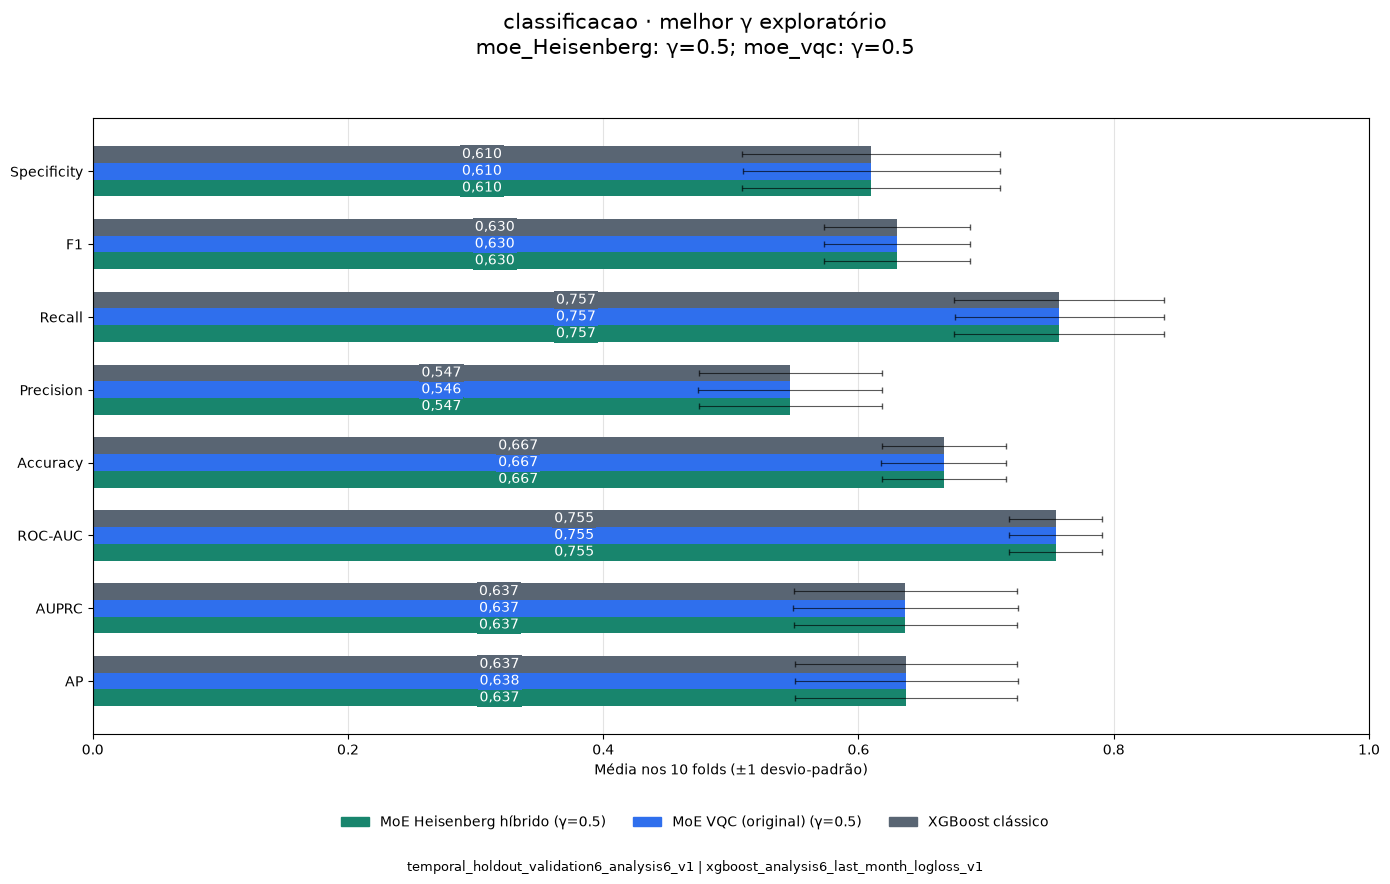

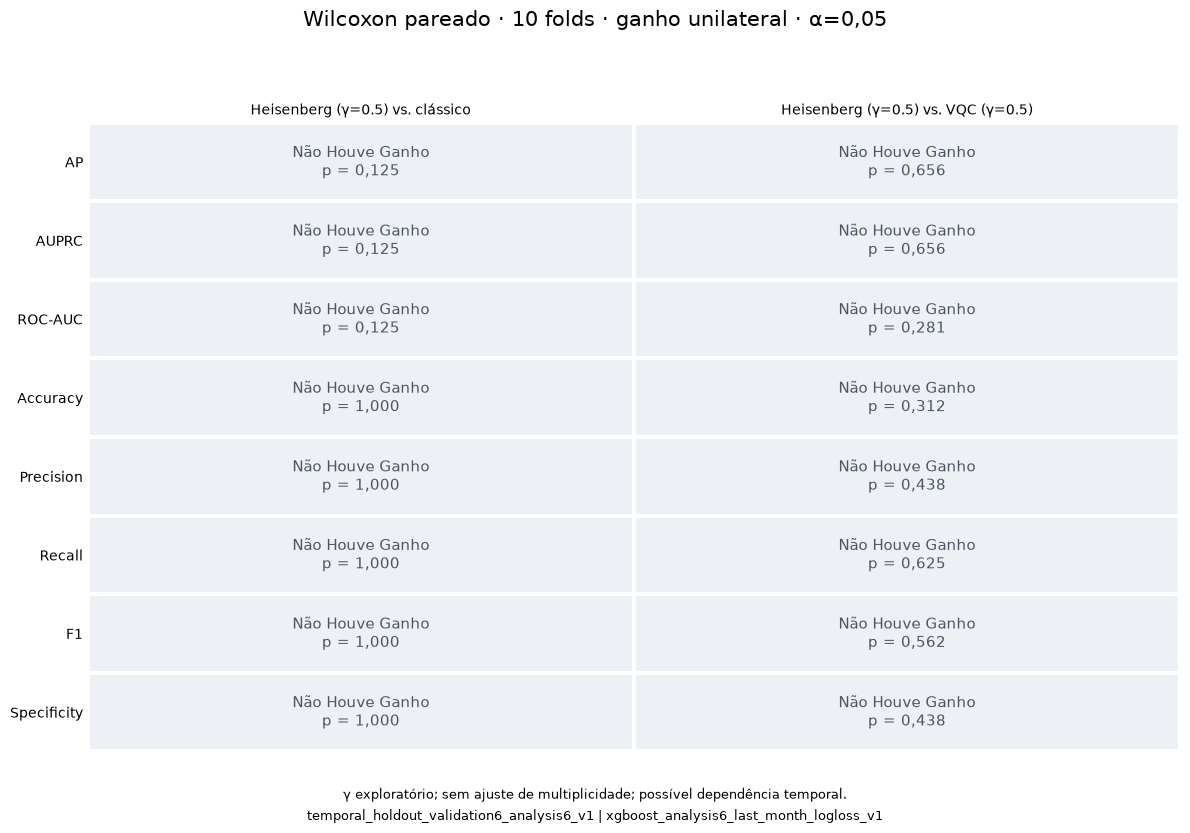

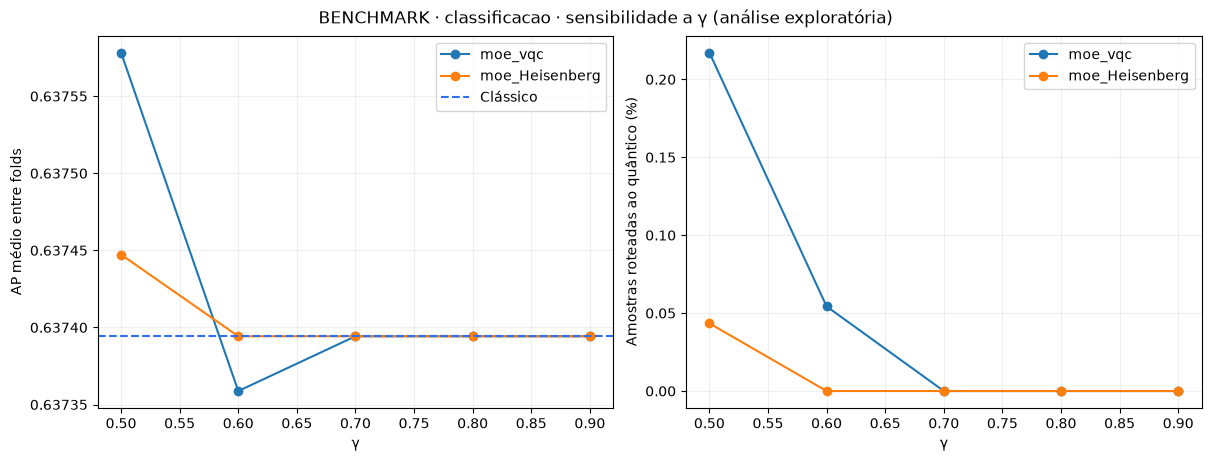

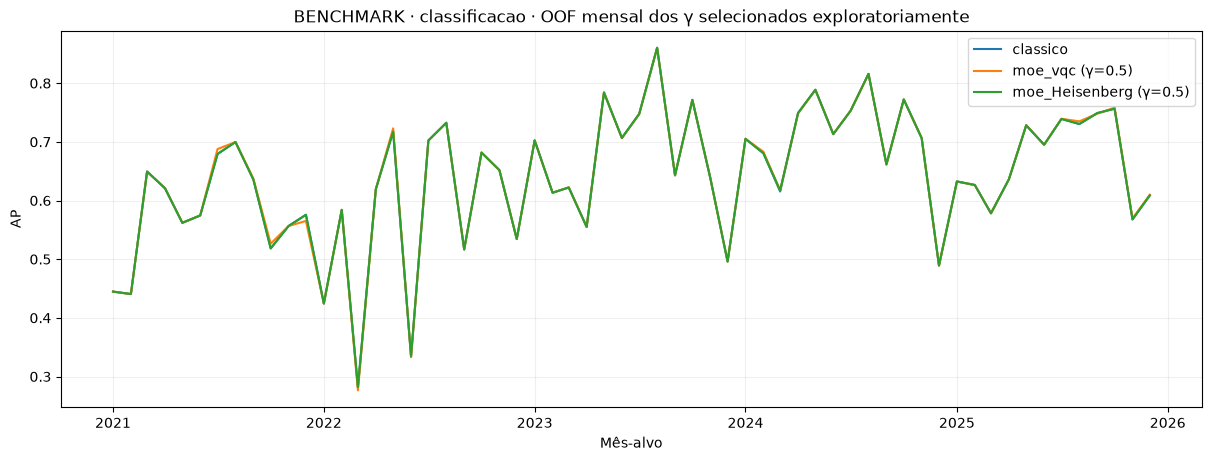

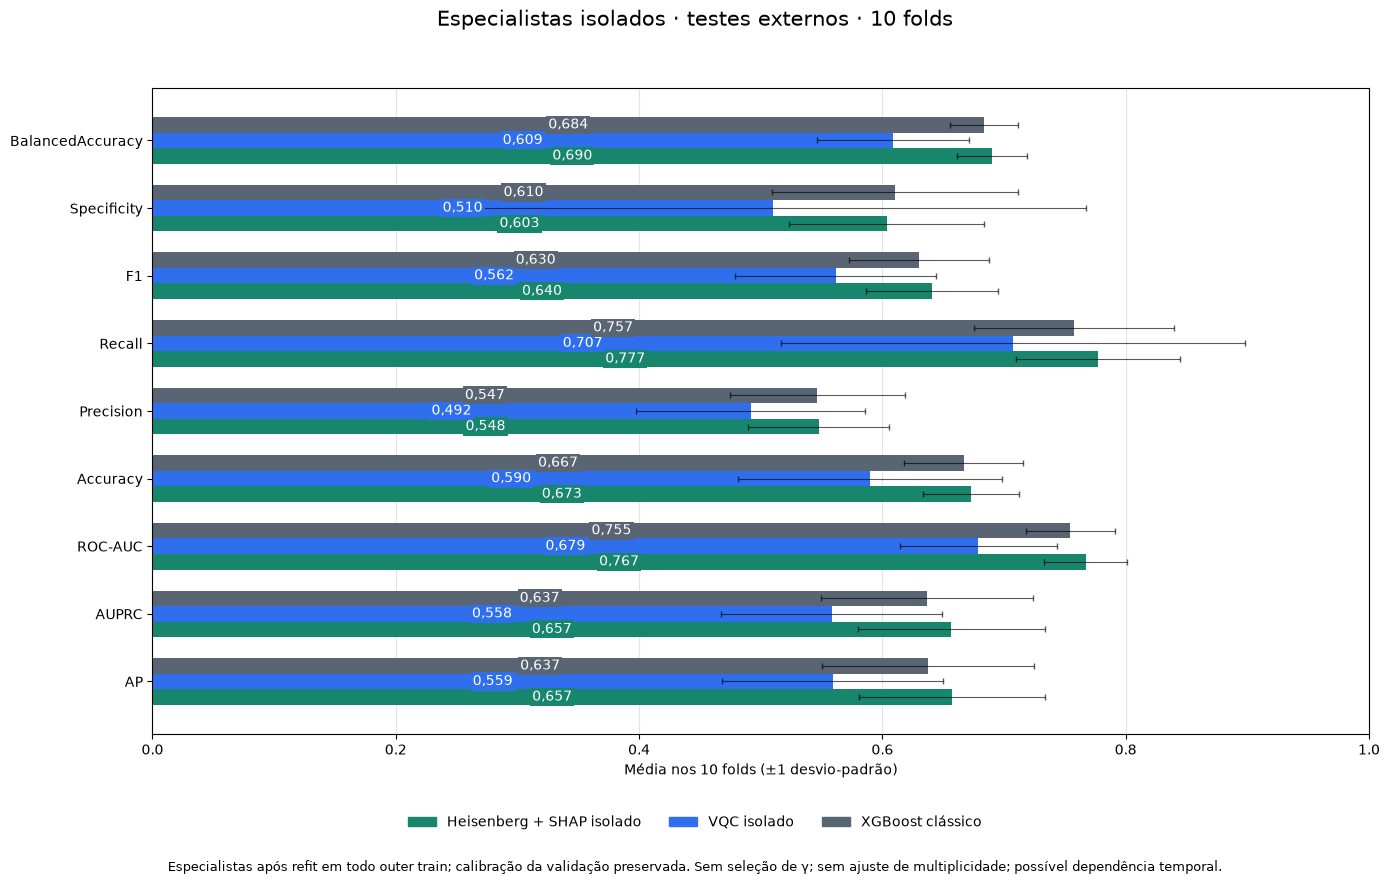

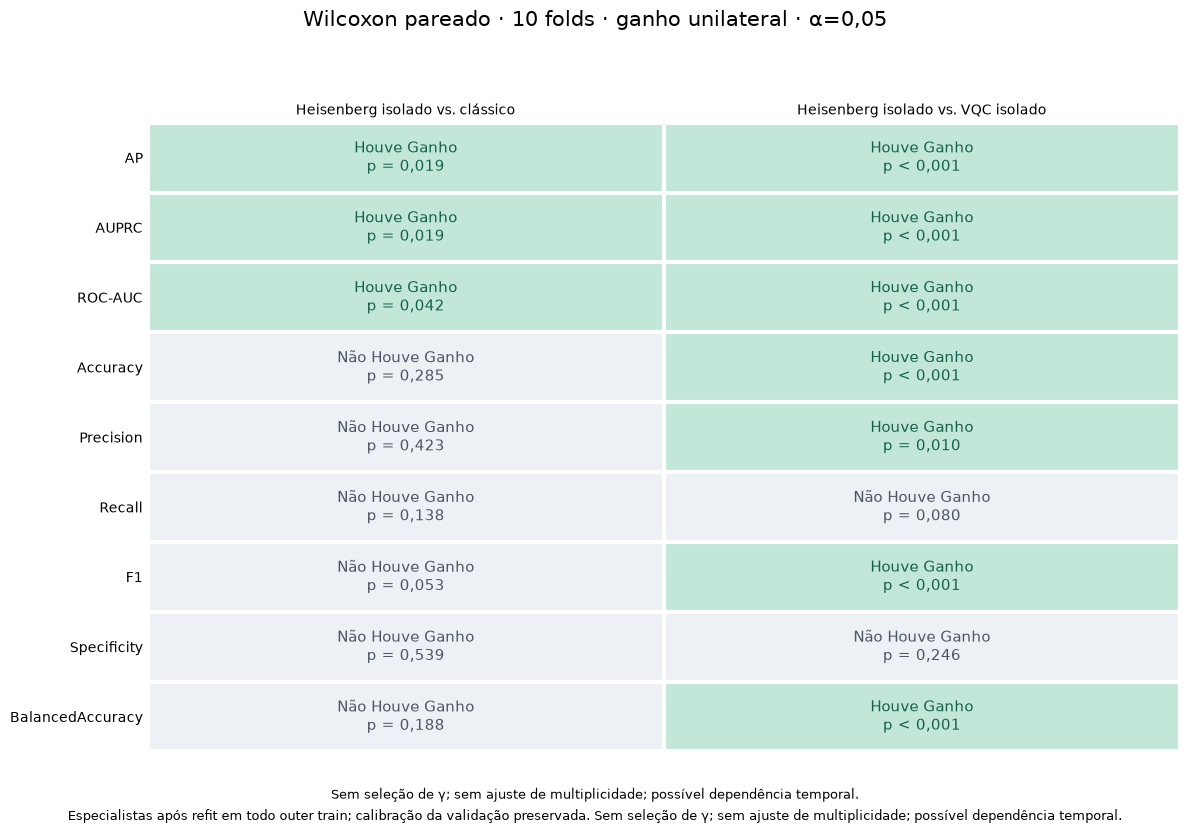

In [30]:
ANALYZE_CLASSIFICATION = True
EXPORT_CLASSIFICATION = False

if ANALYZE_CLASSIFICATION or EXPORT_CLASSIFICATION:
    if "classificacao_moe_results" not in globals():
        raise RuntimeError("Execute primeiro os três cenários de classificacao.")
    classificacao_stats = moe_vs_classic_statistics(classificacao_moe_results["metrics"])
    classificacao_best = select_best_gamma_tables(classificacao_stats)
    classificacao_oof, classificacao_monthly = summarize_selected_oof(
        classificacao_moe_results, classificacao_best)
    if ANALYZE_CLASSIFICATION:
        classificacao_reference = reference_comparison_tables(classificacao_moe_results["metrics"])
        for table_name, table in classificacao_reference.items():
            print(table_name)
            display(table)
        display(classificacao_stats)
        display(classificacao_best)
        display(classificacao_oof)
        classificacao_figures = make_result_figures(
            classificacao_moe_results["metrics"], classificacao_stats, classificacao_best, classificacao_monthly, classificacao_moe_results.get("provenance"))
        if 'standalone_predictions' in classificacao_moe_results:
            classificacao_isolados_tables = standalone_comparison_tables(classificacao_moe_results)
            for name, table in classificacao_isolados_tables.items():
                print(name)
                display(table)
            classificacao_figures.update(standalone_figures(classificacao_moe_results, classificacao_isolados_tables))
        else:
            print('Resultado anterior sem especialistas isolados no teste; execute o experimento atualizado para obter essa comparação.')
        import matplotlib.pyplot as plt
        for figure in classificacao_figures.values():
            display(figure)
            plt.close(figure)
    if EXPORT_CLASSIFICATION:
        classificacao_output = export_moe_results(classificacao_moe_results, data, folds, protocol)
        print("Artefatos:", classificacao_output.resolve())


In [62]:
classificacao_output = export_moe_results(
    classificacao_moe_results, data, folds, protocol
)
print(classificacao_output.resolve())

/home/rafael/projects/pqfmlib-api/notebooks_MoE/outputs/demanda_pressao_holdout/classificacao/full_20261022T182604247227Z_643ddd05


## Limites de interpretação

Validação é reutilizada para selecionar hiperparâmetros, temperatura e threshold F1. Analysis é posterior e separado; os routers recebem alvos produzidos por especialistas que não treinaram nesse bloco. O refit final incorpora as duas reservas, mantendo calibração e routers anteriores. Essa mudança de modelos pode alterar a qualidade do roteamento.

AP, AUPRC trapezoidal, ROC-AUC, Accuracy, Precision, Recall, F1, Specificity e BalancedAccuracy são avaliadas nos testes externos. A escolha do melhor gamma é exploratória. Não confundir melhoria do MoE com avaliação do especialista secundário sozinho em todo o teste.


## Experimento adicional — protocolo clássico sem Analysis

Comparação aprovada: **XGBoost clássico e Heisenberg + SHAP top 50**, seguindo a classificação de `tarefa-demanda-pressao-assistencial.ipynb`.

- Mesma base, dez testes externos de seis meses, grid XGBoost e seed 42.
- Últimos **seis meses do outer train** reservados para validação; todo o período anterior serve ao treino interno (**53 a 107 meses**, em vez de 47 a 101 no MoE).
- Hiperparâmetros selecionados por **AP**. Limiar selecionado por **F1** na mesma validação. AP não seleciona um limiar: ela usa os escores, sem corte de classificação.
- Sem Analysis, router, VQC ou calibração de temperatura neste novo treinamento. Refit integral dos especialistas no outer train (**59 a 113 meses**), preservando o limiar escolhido internamente.
- Pré-processamento, PCA de entrada do mapa e SHAP são ajustados novamente em cada treino; nenhum ajuste usa o teste.

O total de dados do refit final não aumenta. Mudam o tamanho do treino interno, a recência da validação e a calibração. Portanto, comparamos **protocolos completos**, não o efeito isolado de remover Analysis.

Este bloco tem execução e exportação próprias. Para rodar somente ele, carregue as definições/configuração/base das células anteriores, deixe `RUN_CLASSIFICATION_MOE = False` e desative a análise anterior se não houver resultado MoE em memória. Não é necessário treinar o VQC. A configuração Heisenberg vigente acima será usada; confirme que corresponde à execução de referência.


In [31]:
NO_ANALYSIS_PROTOCOL = 'temporal_validation6_no_analysis_no_temperature_v1'
NO_ANALYSIS_LABELS = {
    'classico_sem_analysis': 'Clássico · sem Analysis',
    'heisenberg_sem_analysis': 'Heisenberg · sem Analysis',
    'classico_com_analysis': 'Clássico · protocolo MoE',
    'heisenberg_com_analysis': 'Heisenberg isolado · protocolo MoE',
    'moe_heisenberg_suave': 'MoE Heisenberg suave',
}


def make_no_analysis_folds(data, protocol):
    """Mesmos testes externos; seis meses finais do treino para validação, sem Analysis."""
    if protocol['meses_validacao_interna'] != 6:
        raise ValueError('A referência exige seis meses de validação interna.')
    # Reutiliza somente o calendário externo validado; descarta as reservas do MoE.
    outer = make_temporal_folds(data, protocol)
    result = []
    for fold in outer:
        frame = data.iloc[fold['train']]
        months = pd.DatetimeIndex(sorted(frame.mes_alvo.unique()))
        cutoff = months[-6]
        inner = fold['train'][frame.mes_alvo.lt(cutoff).to_numpy()]
        validation = fold['train'][frame.mes_alvo.ge(cutoff).to_numpy()]
        result.append(dict(fold=fold['fold'], train=fold['train'].copy(), test=fold['test'].copy(),
                           inner_train=inner, inner_validation=validation,
                           temporal_protocol=NO_ANALYSIS_PROTOCOL))
    return result


def describe_no_analysis_folds(data, folds):
    rows = []
    for fold in folds:
        for role in ('inner_train', 'inner_validation', 'train', 'test'):
            block = data.iloc[fold[role]]
            rows.append(dict(fold=fold['fold'], bloco=role, inicio=str(block.mes_alvo.min().date()),
                             fim=str(block.mes_alvo.max().date()), meses=block.mes_alvo.nunique(),
                             amostras=len(block)))
    return pd.DataFrame(rows)


@timed_function('Sem Analysis: ajuste de especialista')
def fit_no_analysis_expert(kind, train, params, protocol, config=None,
                           factory=make_heisenberg_map, stage='inner_fit'):
    """Ajuste independente, sem temperatura; pré-processamento/SHAP veem só train."""
    features = protocol['features_numericas'] + protocol['features_categoricas']
    y = train[TARGETS['classificacao']].to_numpy()
    if kind == 'classic':
        return dict(kind=kind, task='classificacao',
                    pipeline=make_pipeline('classificacao', params, protocol).fit(train[features], y))
    if kind != 'Heisenberg':
        raise ValueError('Este experimento contém somente clássico e Heisenberg.')
    preprocessor = make_preprocessor(protocol).fit(train[features])
    X = preprocessor.transform(train[features])
    feature_map = HeisenbergFeatures(config, factory=factory).fit(X, stage=stage)
    quantum = feature_map.transform(X, stage=stage)
    model = quantum_estimator('classificacao', params, feature_map.config).fit(
        np.column_stack([quantum, X]), y)
    return dict(kind=kind, task='classificacao', preprocessor=preprocessor,
                config=feature_map.config, model=HeisenbergExpert('classificacao', feature_map, model))


def run_no_analysis_experiment(data, protocol, *, folds=None, grid=None,
                               heisenberg_config=None, factory=make_heisenberg_map):
    """Seleção AP, limiar F1, refit integral e teste futuro, como na referência clássica."""
    expected = make_no_analysis_folds(data, protocol)
    folds = expected if folds is None else folds
    lookup = {f['fold']: f for f in expected}
    if not folds or len({f['fold'] for f in folds}) != len(folds):
        raise ValueError('Folds ausentes ou duplicados.')
    for fold in folds:
        ref = lookup.get(fold['fold'])
        if (ref is None or fold.get('temporal_protocol') != NO_ANALYSIS_PROTOCOL
                or 'analysis' in fold or any(not np.array_equal(fold[k], ref[k])
                    for k in ('train', 'test', 'inner_train', 'inner_validation'))):
            raise ValueError('Divisões incompatíveis com o protocolo sem Analysis.')
    selected_grid = protocol['grades_classificacao']['xgboost'] if grid is None else grid
    scientific = (len(folds) == 10 and grid is None and heisenberg_config is None
                  and factory is make_heisenberg_map)
    run_type = 'full' if scientific else 'integration'
    rows, predictions, validations, selections, diagnostics, timing_rows = [], [], [], [], [], []
    for fold in folds:
        number = int(fold['fold'])
        inner, validation, train, test = (data.iloc[fold[k]] for k in
                                        ('inner_train', 'inner_validation', 'train', 'test'))
        with record_fold_timings('classificacao', number, 'Sem Analysis: clássico e Heisenberg') as timings:
            for kind, scenario in (('classic', 'classico_sem_analysis'),
                                   ('Heisenberg', 'heisenberg_sem_analysis')):
                started = time.perf_counter()
                if kind == 'classic':
                    _, table = tune_classic(data, fold, protocol, 'classificacao', selected_grid)
                    calls = []
                else:
                    _, table, calls = tune_heisenberg(inner, validation, protocol, 'classificacao',
                                                       selected_grid, heisenberg_config, factory)
                tuning_seconds = time.perf_counter() - started
                # Mesma ordenação/desempate de tuning_classificacao no notebook de referência.
                table = table.sort_values('score', ascending=False)
                params = dict(table.iloc[0]['params'])
                selections.extend(dict(fold=number, scenario=scenario, **row)
                                  for row in table.to_dict('records'))
                started = time.perf_counter()
                initial = fit_no_analysis_expert(kind, inner, params, protocol,
                    heisenberg_config, factory, stage='no_analysis_inner_fit')
                initial_fit_seconds = time.perf_counter() - started
                raw, _ = expert_output(initial, validation, protocol,
                                        stage='no_analysis_validation', uncalibrated=True)
                threshold = best_f1_threshold(validation[TARGETS['classificacao']], raw)
                val = validation[['cnes', 'competencia', 'mes_alvo']].copy()
                val = val.assign(fold=number, scenario=scenario,
                    real=validation[TARGETS['classificacao']].to_numpy(), score=raw,
                    previsto=(raw >= threshold).astype(int), threshold=threshold,
                    train_end=inner.mes_alvo.max())
                validations.append(val)
                initial_selection = hybrid_selection_diagnostics(initial) if kind == 'Heisenberg' else None
                del initial
                started = time.perf_counter()
                final = fit_no_analysis_expert(kind, train, params, protocol,
                    heisenberg_config, factory, stage='no_analysis_outer_refit')
                refit_seconds = time.perf_counter() - started
                started = time.perf_counter()
                score, _ = expert_output(final, test, protocol,
                                        stage='no_analysis_test', uncalibrated=True)
                inference_seconds = time.perf_counter() - started
                predicted = (score >= threshold).astype(int)
                y = test[TARGETS['classificacao']].to_numpy()
                rows.append(dict(fold=number, scenario=scenario, task='classificacao', run_type=run_type,
                    n_test=len(test), threshold=threshold, tuning_seconds=tuning_seconds,
                    initial_fit_seconds=initial_fit_seconds, refit_seconds=refit_seconds,
                    inference_seconds=inference_seconds, seconds_per_sample=inference_seconds/len(test),
                    **classification_metrics(y, score, predicted)))
                saved = test[['cnes', 'competencia', 'mes_alvo']].copy()
                predictions.append(saved.assign(fold=number, scenario=scenario, real=y, score=score,
                    previsto=predicted, threshold=threshold, train_end=train.mes_alvo.max()))
                detail = dict(fold=number, scenario=scenario, params=params, threshold=threshold,
                    temperature=None, inner_train_n=len(inner), outer_train_n=len(train),
                    validation_n=len(validation), inner_calls=calls, initial_selection=initial_selection)
                if kind == 'Heisenberg':
                    detail.update(final_selection=hybrid_selection_diagnostics(final),
                                  final_calls=copy.deepcopy(final['model'].feature_map.calls))
                diagnostics.append(detail)
                del final
        timing_rows.extend(timings)
    provenance = dict(data_fingerprint=data_fingerprint(data, protocol), protocol=copy.deepcopy(protocol),
        temporal_protocol=NO_ANALYSIS_PROTOCOL, analysis_months=0, inner_validation_months=6,
        calibration='none', threshold_selection='F1', model_selection='AP', seed=SEED,
        expert_train_scope='all_outer_train', run_type=run_type, folds=[f['fold'] for f in folds],
        grid=copy.deepcopy(selected_grid), heisenberg_config=dict(HEISENBERG_CONFIG, **heisenberg_config or {}),
        estimator_defaults=make_estimator('classificacao', {}).get_params(deep=False),
        quantum_factory=getattr(factory, '__name__', type(factory).__name__),
        reference='tarefa-demanda-pressao-assistencial.ipynb')
    result = dict(metrics=pd.DataFrame(rows), predictions=pd.concat(predictions, ignore_index=True),
        validation_predictions=pd.concat(validations, ignore_index=True), tuning=pd.DataFrame(selections),
        diagnostics=diagnostics, timings=pd.DataFrame(timing_rows, columns=TIMING_COLUMNS),
        fold_roles=describe_no_analysis_folds(data, folds), provenance=provenance)
    validate_no_analysis_result(result, data, protocol)
    return result


def validate_no_analysis_result(result, data, protocol):
    """Reconcilia probabilidades, limiares, alvos e calendários antes de comparar/exportar."""
    provenance = result['provenance']
    if (provenance['data_fingerprint'] != data_fingerprint(data, protocol)
            or provenance['protocol'] != protocol or provenance['temporal_protocol'] != NO_ANALYSIS_PROTOCOL
            or provenance['analysis_months'] != 0 or provenance['calibration'] != 'none'):
        raise ValueError('Base/protocolo sem Analysis divergente.')
    folds = {f['fold']: f for f in make_no_analysis_folds(data, protocol)}
    scenarios = {'classico_sem_analysis', 'heisenberg_sem_analysis'}
    metrics = result['metrics']
    pairs = {(f, s) for f in provenance['folds'] for s in scenarios}
    if (metrics.duplicated(['fold', 'scenario']).any()
            or set(zip(metrics.fold, metrics.scenario)) != pairs):
        raise ValueError('Métricas ausentes ou duplicadas.')
    keys = ['cnes', 'competencia', 'mes_alvo']
    for table_name, role, train_role in [('predictions', 'test', 'train'),
                                       ('validation_predictions', 'inner_validation', 'inner_train')]:
        frame = result[table_name]
        if frame.duplicated(['fold', 'scenario', *keys]).any() or set(zip(frame.fold, frame.scenario)) != pairs:
            raise ValueError('Previsões ausentes ou duplicadas.')
        for (fold, scenario), group in frame.groupby(['fold', 'scenario']):
            expected = data.iloc[folds[fold][role]]
            merged = expected.merge(group, on=keys, validate='one_to_one', suffixes=('_data', ''))
            if (len(merged) != len(expected) or len(group) != len(expected)
                    or not np.array_equal(merged[TARGETS['classificacao']], merged.real)):
                raise ValueError('Previsões não correspondem à base.')
            score = group.score.to_numpy(float)
            if not np.isfinite(score).all() or ((score < 0) | (score > 1)).any():
                raise ValueError('Scores inválidos.')
            metric = metrics.loc[metrics.fold.eq(fold) & metrics.scenario.eq(scenario)].iloc[0]
            end = data.iloc[folds[fold][train_role]].mes_alvo.max()
            if (not group.train_end.eq(end).all() or not group.threshold.eq(metric.threshold).all()
                    or not np.array_equal(group.previsto, (score >= metric.threshold).astype(int))):
                raise ValueError('Limiar, previsão ou escopo temporal divergente.')
            if role == 'inner_validation':
                if best_f1_threshold(group.real, score) != metric.threshold:
                    raise ValueError('Limiar não corresponde ao F1 da validação.')
            else:
                computed = classification_metrics(group.real, score, group.previsto)
                if metric.n_test != len(group) or any(not np.isclose(metric[k], v, rtol=0, atol=1e-12)
                                                      for k, v in computed.items()):
                    raise ValueError('Métricas não correspondem às previsões.')
    return True


In [32]:
def load_moe_comparison_reference(directory):
    """Lê uma exportação completa para comparação, sem carregar modelos nem retreinar."""
    directory = Path(directory)
    return dict(
        provenance=json.loads((directory / 'protocolo_execucao.json').read_text()),
        diagnostics=json.loads((directory / 'diagnosticos.json').read_text()),
        metrics=pd.read_csv(directory / 'metricas_por_fold.csv'),
        standalone_metrics=pd.read_csv(directory / 'metricas_especialistas_isolados_por_fold.csv'),
        predictions=pd.read_parquet(directory / 'previsoes_oof.parquet'),
        standalone_predictions=pd.read_parquet(directory / 'previsoes_oof_especialistas_isolados.parquet'))


def no_analysis_comparison_tables(result, moe_result=None):
    """Compara protocolos nos mesmos testes; reconstrói suave sem alterar o MoE original."""
    rows = result['metrics'].copy()
    probability_tables = [result['predictions'].copy()]
    protocols = [dict(experiment='sem_analysis', provenance=json.dumps(json_safe(result['provenance']), ensure_ascii=False))]
    if moe_result is not None:
        if (moe_result['provenance']['data_fingerprint'] != result['provenance']['data_fingerprint']
                or moe_result['provenance']['protocol'] != result['provenance']['protocol']
                or set(moe_result['provenance']['folds']) != set(result['provenance']['folds'])):
            raise ValueError('Comparação exige mesma base, protocolo externo e folds.')
        validate_standalone_predictions(moe_result)
        protocols.append(dict(experiment='referencia_moe', provenance=json.dumps(json_safe(moe_result['provenance']), ensure_ascii=False)))
        keys = ['cnes', 'competencia', 'mes_alvo']
        extra = []
        for fold in result['provenance']['folds']:
            def isolated(scenario):
                return moe_result['standalone_predictions'].loc[lambda x:
                    x.fold.eq(fold) & x.scenario.eq(scenario)].sort_values(keys).reset_index(drop=True)
            classic, heis = isolated('classico'), isolated('heisenberg_isolado')
            target = result['predictions'].loc[lambda x: x.fold.eq(fold)
                & x.scenario.eq('classico_sem_analysis')].sort_values(keys).reset_index(drop=True)
            for frame in (classic, heis):
                if not frame[keys].equals(target[keys]) or not np.array_equal(frame.real, target.real):
                    raise ValueError('Comparação exige exatamente as mesmas amostras e alvos.')
            routes = moe_result['predictions'].loc[lambda x:
                x.fold.eq(fold) & x.scenario.eq('moe_Heisenberg')]
            if routes.empty:
                raise ValueError('Probabilidades do router Heisenberg ausentes.')
            # gamma só duplica o mesmo g(x); não seleciona uma configuração pelo teste.
            gate = routes.sort_values([*keys, 'gamma']).drop_duplicates(keys).sort_values(keys).reset_index(drop=True)
            if (not gate[keys].equals(target[keys])
                    or routes.groupby(keys).router_probability.nunique().ne(1).any()):
                raise ValueError('Scores do router inconsistentes entre gammas.')
            w = gate.router_probability.to_numpy(float)
            if not np.isfinite(w).all() or ((w < 0) | (w > 1)).any():
                raise ValueError('Pesos do router inválidos.')
            detail = next(x for x in moe_result['diagnostics'] if x['fold'] == fold)
            tc, th = detail['classic_threshold'], detail['models']['moe_Heisenberg']['threshold']
            if (not np.array_equal(classic.previsto, (classic.score >= tc).astype(int))
                    or not np.array_equal(heis.previsto, (heis.score >= th).astype(int))):
                raise ValueError('Limiares da referência não reproduzem as decisões.')
            soft_score = (1-w)*classic.score.to_numpy() + w*heis.score.to_numpy()
            soft_pred = (soft_score >= (1-w)*tc + w*th).astype(int)
            isolated_times = moe_result['standalone_metrics'].loc[lambda x: x.fold.eq(fold)].set_index('scenario')
            router_times = moe_result['metrics'].loc[lambda x:
                x.fold.eq(fold) & x.scenario.eq('moe_Heisenberg')].iloc[0]
            soft_seconds = (isolated_times.loc['classico', 'inference_seconds']
                            + isolated_times.loc['heisenberg_isolado', 'inference_seconds']
                            + router_times['router_seconds'] + router_times['router_preprocessing_seconds'])
            for scenario, score, predicted, seconds in (
                ('classico_com_analysis', classic.score, classic.previsto,
                 isolated_times.loc['classico', 'inference_seconds']),
                ('heisenberg_com_analysis', heis.score, heis.previsto,
                 isolated_times.loc['heisenberg_isolado', 'inference_seconds']),
                ('moe_heisenberg_suave', soft_score, soft_pred, soft_seconds)):
                extra.append(dict(fold=fold, scenario=scenario, n_test=len(target),
                    inference_seconds=seconds, seconds_per_sample=seconds/len(target),
                    **classification_metrics(target.real, score, predicted)))
                saved = target[keys].copy().assign(fold=fold, scenario=scenario,
                    real=target.real.to_numpy(), score=np.asarray(score), previsto=np.asarray(predicted))
                probability_tables.append(saved)
        rows = pd.concat([rows, pd.DataFrame(extra)], ignore_index=True)
    names = EVALUATION_METRICS['classificacao']
    summary = []
    for scenario, group in rows.groupby('scenario', sort=False):
        for metric in names:
            summary.append(dict(scenario=scenario, label=NO_ANALYSIS_LABELS[scenario], metric=metric,
                mean=group[metric].mean(), std=group[metric].std(ddof=1), n=len(group)))
    pairs = [('heisenberg_sem_analysis', 'classico_sem_analysis')]
    if moe_result is not None:
        pairs += [('moe_heisenberg_suave', 'classico_sem_analysis'),
                  ('heisenberg_sem_analysis', 'moe_heisenberg_suave'),
                  ('heisenberg_sem_analysis', 'heisenberg_com_analysis'),
                  ('classico_sem_analysis', 'classico_com_analysis')]
    tests = []
    for candidate, reference in pairs:
        a = rows.loc[rows.scenario.eq(candidate)].set_index('fold').sort_index()
        b = rows.loc[rows.scenario.eq(reference)].set_index('fold').sort_index()
        if not a.index.equals(b.index) or not a.index.is_unique:
            raise ValueError('Comparação pareada exige folds únicos e idênticos.')
        for metric in names:
            raw = a[metric].to_numpy() - b[metric].to_numpy()
            delta = np.round(raw, 12)
            n, mean, std, low, high = mean_student_t_ci(raw)
            p = (np.nan if n < 2 else float(wilcoxon(delta, alternative='greater',
                 zero_method='wilcox', method='auto').pvalue) if np.any(delta) else 1.)
            tests.append(dict(candidate=candidate, reference=reference, metric=metric, n_pairs=n,
                delta_mean=mean, delta_std=std, delta_ci95_low=low, delta_ci95_high=high,
                p_value=p, alternative='greater', p_adjustment='none',
                conclusion='Não estimável' if not np.isfinite(p) else 'Houve Ganho' if p <= .05 else 'Não Houve Ganho'))
    costs = rows[['scenario', 'fold', 'n_test', 'inference_seconds', 'seconds_per_sample']].copy()
    costs['quantum_evaluated_fraction'] = costs.scenario.map(lambda s: 0. if s.startswith('classico') else 1.)
    costs['timing_note'] = np.where(costs.scenario.eq('moe_heisenberg_suave'),
        'Soma das etapas medidas na execução MoE; não é benchmark novo de latência.',
        'Inferência completa medida em lote; segundos/amostra é throughput, não latência individual.')
    return dict(metrics_by_fold=rows, summary=pd.DataFrame(summary), paired_tests=pd.DataFrame(tests),
                inference_costs=costs, protocols=pd.DataFrame(protocols),
                predictions=pd.concat(probability_tables, ignore_index=True))


def no_analysis_figures(tables):
    """Barras e painel de Wilcoxon contra o clássico sem Analysis, com rótulos explícitos."""
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    table = tables['summary']
    scenarios = ['classico_sem_analysis', 'heisenberg_sem_analysis']
    if 'moe_heisenberg_suave' in table.scenario.values:
        scenarios.append('moe_heisenberg_suave')
    names = list(EVALUATION_METRICS['classificacao'])
    labels = ['AUPRC' if x == 'AUPRC_trapezoidal' else x for x in names]
    fig, ax = plt.subplots(figsize=(14, 9))
    height = .72/len(scenarios)
    for i, (scenario, color) in enumerate(zip(scenarios, ('#596573', '#2f6fed', '#18856d'))):
        group = table.loc[table.scenario.eq(scenario)].set_index('metric').loc[names]
        pos = np.arange(len(names)) + (i-(len(scenarios)-1)/2)*height
        ax.barh(pos, group['mean'], height=height, xerr=group['std'], capsize=2,
                color=color, label=NO_ANALYSIS_LABELS[scenario], error_kw={'elinewidth': .8})
        for y, mean in zip(pos, group['mean']):
            ax.text(mean/2, y, f'{mean:.3f}', color='white', va='center', ha='center')
    ax.set_yticks(range(len(names)), labels); ax.invert_yaxis(); ax.set_xlim(0, 1)
    ax.set_xlabel('Média nos folds externos ± 1 desvio-padrão'); ax.grid(axis='x', alpha=.25)
    ax.set_axisbelow(True); ax.legend(loc='lower center', bbox_to_anchor=(.5, -.16), ncol=3)
    ax.set_title('Protocolos completos · mesmos testes temporais')
    fig.tight_layout(rect=(0, .08, 1, 1))
    tests = tables['paired_tests'].loc[lambda x: x.reference.eq('classico_sem_analysis')]
    candidates = list(tests.candidate.drop_duplicates())
    values = np.array([[tests.loc[tests.candidate.eq(c) & tests.metric.eq(m), 'p_value'].iloc[0] <= .05
                        for c in candidates] for m in names])
    panel, ax2 = plt.subplots(figsize=(max(8, 6*len(candidates)), 9))
    ax2.imshow(values, cmap=ListedColormap(['#edf0f4', '#c2e7d9']), aspect='auto', vmin=0, vmax=1)
    for j, candidate in enumerate(candidates):
        for i, metric in enumerate(names):
            row = tests.loc[tests.candidate.eq(candidate) & tests.metric.eq(metric)].iloc[0]
            ax2.text(j, i, f'{row.conclusion}\np = {row.p_value:.4f}', ha='center', va='center')
    ax2.set_xticks(range(len(candidates)), [NO_ANALYSIS_LABELS[c]+'\nvs. clássico sem Analysis' for c in candidates])
    ax2.xaxis.tick_top(); ax2.set_yticks(range(len(names)), labels)
    panel.suptitle('Wilcoxon pareado unilateral · α=0,05', fontsize=15)
    panel.text(.5, .025, 'Exploratório, sem ajuste múltiplo. Ausência de significância não implica equivalência.', ha='center')
    panel.tight_layout(rect=(0, .055, 1, .93))
    return dict(comparacao_protocolos=fig, ganhos_vs_classico_sem_analysis=panel)


def export_no_analysis_results(result, data, protocol, tables, figures, *,
                               output_root=Path('outputs/demanda_pressao_sem_analysis')):
    """Exportação própria, com manifesto; não sobrescreve artefatos do MoE."""
    from datetime import datetime, timezone
    import uuid
    validate_no_analysis_result(result, data, protocol)
    directory = Path(output_root) / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')+'_'+uuid.uuid4().hex[:8])
    directory.mkdir(parents=True, exist_ok=False)
    for name in ('metrics', 'tuning', 'timings', 'fold_roles'):
        result[name].to_csv(directory / f'{name}.csv', index=False)
    for name in ('predictions', 'validation_predictions'):
        result[name].to_parquet(directory / f'{name}.parquet', index=False)
    for name in ('diagnostics', 'provenance'):
        (directory / f'{name}.json').write_text(json.dumps(json_safe(result[name]), ensure_ascii=False, indent=2, allow_nan=False))
    for name, table in tables.items():
        if name == 'predictions':
            table.to_parquet(directory / 'comparison_predictions.parquet', index=False)
        else:
            table.to_csv(directory / f'comparison_{name}.csv', index=False)
    for name, fig in figures.items():
        for suffix in ('png', 'svg'):
            fig.savefig(directory / f'{name}.{suffix}', dpi=180, bbox_inches='tight')
    (directory / 'LEIA_ME.txt').write_text(
        'Sem Analysis: validação final de seis meses, AP para parâmetros, F1 para limiar, sem temperatura.\n'
        'Refit em todo outer train. MoE suave opcional reconstruído com escores/limiares originais.\n'
        'AP/ROC-AUC usam scores; decisão suave usa limiares F1 ponderados.\n'
        'IC95% t da diferença média é aproximado e não corrige dependência temporal.\n'
        'Houve Ganho usa somente Wilcoxon unilateral p<=0.05, sem ajuste múltiplo.\n'
        'Comparação de protocolos completos; não isola causalmente o efeito de Analysis.\n'
        'Tempos por amostra são médias de execução em lote, não latência individual.\n', encoding='utf-8')
    manifest = {f.name: hashlib.sha256(f.read_bytes()).hexdigest() for f in directory.iterdir() if f.is_file()}
    (directory / 'manifest.json').write_text(json.dumps(manifest, indent=2))
    return directory


### Comparação com o MoE e custos

O comparador opcional usa `classificacao_moe_results` em memória ou uma exportação indicada em `MOE_REFERENCE_DIR`. Reconstrói a mistura suave dos escores existentes, sem modificar o treinamento nem as saídas anteriores:

`p_suave = (1-g) * p_classico + g * p_Heisenberg`

A decisão usa `p_suave >= (1-g) * limiar_F1_classico + g * limiar_F1_Heisenberg`. Essa regra preserva os extremos; não é um novo limiar escolhido por F1. O router original aprende correção exclusiva e não foi treinado especificamente para otimizar esses pesos.

A tabela inclui os dois especialistas nos dois protocolos e o MoE suave. O painel mostra **Heisenberg sem Analysis × clássico sem Analysis** e, quando disponível, **MoE suave × clássico sem Analysis**. A comparação direta Heisenberg sem Analysis × MoE suave consta da tabela pareada.

Barras: média ± DP. “Houve Ganho”: Wilcoxon unilateral, p ≤ 0,05, sem ajuste de multiplicidade. IC95% t das diferenças é exibido separadamente, aproximado e sem correção da dependência temporal. Ausência de significância não demonstra equivalência.

O MoE suave e o Heisenberg isolado calculam o quântico para **100% das amostras**. Tempos/amostra medidos em lote representam throughput, não latência de uma requisição individual. O custo do MoE é reconstruído das etapas medidas, sem novo benchmark; não inclui o custo desprezível da combinação dos vetores. Tempos de treino do novo experimento e tempos por etapa são exportados, sem atribuir ao Heisenberg o custo de treinamento do VQC da execução antiga.


In [33]:
RUN_NO_ANALYSIS = True

if RUN_NO_ANALYSIS:
    folds_sem_analysis = make_no_analysis_folds(data, protocol)
    display(describe_no_analysis_folds(data, folds_sem_analysis))
    if globals().get("tilelang_verified_config") != HEISENBERG_CONFIG:
        raise RuntimeError("Execute a comparação TileLang vs CUDA-Q com a configuração atual primeiro.")
    classificacao_sem_analysis_results = run_no_analysis_experiment(
        data, protocol, folds=folds_sem_analysis)
    display(classificacao_sem_analysis_results['metrics'])


,fold,bloco,inicio,fim,meses,amostras
0,1,inner_train,2016-02-01,2020-06-01,53,15080
1,1,inner_validation,2020-07-01,2020-12-01,6,1799
2,1,train,2016-02-01,2020-12-01,59,16879
3,1,test,2021-01-01,2021-06-01,6,1812
4,2,inner_train,2016-02-01,2020-12-01,59,16879
5,2,inner_validation,2021-01-01,2021-06-01,6,1812
6,2,train,2016-02-01,2021-06-01,65,18691
7,2,test,2021-07-01,2021-12-01,6,1810
8,3,inner_train,2016-02-01,2021-06-01,65,18691
9,3,inner_validation,2021-07-01,2021-12-01,6,1810


[2026-10-24  22:07:45] classificacao: fold 01 | Sem Analysis: clássico e Heisenberg: início
[2026-10-24  22:07:45] classificacao: fold 01 |   Clássico: busca interna: início
[2026-10-24  22:07:52] classificacao: fold 01 |   Clássico: busca interna: concluído em 00:00:06.986
[2026-10-24  22:07:52] classificacao: fold 01 |   Sem Analysis: ajuste de especialista [classic]: início
[2026-10-24  22:07:52] classificacao: fold 01 |   Sem Analysis: ajuste de especialista [classic]: concluído em 00:00:00.314
[2026-10-24  22:07:52] classificacao: fold 01 |   Sem Analysis: ajuste de especialista [classic]: início
[2026-10-24  22:07:52] classificacao: fold 01 |   Sem Analysis: ajuste de especialista [classic]: concluído em 00:00:00.339
[2026-10-24  22:07:52] classificacao: fold 01 |   Heisenberg: seleção interna: início
[2026-10-24  22:07:52] classificacao: fold 01 |     Heisenberg: preparar PCA/mapa [inner_train]: início
PCA Heisenberg [inner_train]: 50/54 componentes; 4 posições de encoding preen

,fold,scenario,task,run_type,n_test,threshold,tuning_seconds,initial_fit_seconds,refit_seconds,inference_seconds,...,Accuracy,BalancedAccuracy,Precision,Recall,F1,Specificity,tn,fp,fn,tp
0,1,classico_sem_analysis,classificacao,full,1812,0.289043,6.986593,0.315249,0.340725,0.007601,...,0.649558,0.651861,0.490385,0.659128,0.562371,0.644593,769,424,211,408
1,1,heisenberg_sem_analysis,classificacao,full,1812,0.302612,731.900225,630.317271,761.517708,74.740226,...,0.699227,0.694244,0.548303,0.678514,0.606498,0.709975,847,346,199,420
2,2,classico_sem_analysis,classificacao,full,1810,0.210654,7.278890,0.437666,0.438166,0.006838,...,0.565746,0.652682,0.420255,0.899317,0.572826,0.406046,497,727,59,527
3,2,heisenberg_sem_analysis,classificacao,full,1810,0.253815,815.126165,697.156671,759.978354,72.749737,...,0.664641,0.706678,0.489383,0.825939,0.614603,0.587418,719,505,102,484
4,3,classico_sem_analysis,classificacao,full,1816,0.333310,8.009615,0.299265,0.310861,0.006367,...,0.638216,0.640561,0.450363,0.646957,0.531049,0.634166,787,454,203,372
5,3,heisenberg_sem_analysis,classificacao,full,1816,0.314198,894.004708,772.244301,832.523532,75.224791,...,0.611233,0.623619,0.426156,0.657391,0.517100,0.589847,732,509,197,378
6,4,classico_sem_analysis,classificacao,full,1824,0.321826,7.855849,0.393090,0.402365,0.006595,...,0.692434,0.685495,0.549479,0.662480,0.600712,0.708509,841,346,215,422
7,4,heisenberg_sem_analysis,classificacao,full,1824,0.250104,963.910419,846.256935,903.456844,75.346832,...,0.636513,0.678172,0.487805,0.816327,0.610687,0.540017,641,546,117,520
8,5,classico_sem_analysis,classificacao,full,1844,0.293716,8.559159,0.564363,0.411662,0.006223,...,0.630152,0.670068,0.495032,0.816692,0.616423,0.523444,614,559,123,548
9,5,heisenberg_sem_analysis,classificacao,full,1844,0.312211,1071.388753,922.366081,983.029032,73.676458,...,0.629067,0.665389,0.494009,0.798808,0.610478,0.531969,624,549,135,536


summary


,scenario,label,metric,mean,std,n
0,classico_sem_analysis,Clássico · sem Analysis,AP,0.641373,0.075332,10
1,classico_sem_analysis,Clássico · sem Analysis,AUPRC_trapezoidal,0.640548,0.075592,10
2,classico_sem_analysis,Clássico · sem Analysis,ROC-AUC,0.754964,0.031559,10
3,classico_sem_analysis,Clássico · sem Analysis,Accuracy,0.664347,0.044226,10
4,classico_sem_analysis,Clássico · sem Analysis,Precision,0.542679,0.074877,10
5,classico_sem_analysis,Clássico · sem Analysis,Recall,0.756749,0.082127,10
6,classico_sem_analysis,Clássico · sem Analysis,F1,0.627866,0.059749,10
7,classico_sem_analysis,Clássico · sem Analysis,Specificity,0.607316,0.090471,10
8,classico_sem_analysis,Clássico · sem Analysis,BalancedAccuracy,0.682033,0.027376,10
9,heisenberg_sem_analysis,Heisenberg · sem Analysis,AP,0.650801,0.075197,10


paired_tests


,candidate,reference,metric,n_pairs,delta_mean,delta_std,delta_ci95_low,delta_ci95_high,p_value,alternative,p_adjustment,conclusion
0,heisenberg_sem_analysis,classico_sem_analysis,AP,10,0.009428,0.020188,-0.005014,0.023870,0.116211,greater,none,Não Houve Ganho
1,heisenberg_sem_analysis,classico_sem_analysis,AUPRC_trapezoidal,10,0.009669,0.020426,-0.004942,0.024281,0.116211,greater,none,Não Houve Ganho
2,heisenberg_sem_analysis,classico_sem_analysis,ROC-AUC,10,0.008224,0.015205,-0.002653,0.019101,0.052734,greater,none,Não Houve Ganho
3,heisenberg_sem_analysis,classico_sem_analysis,Accuracy,10,0.002841,0.045494,-0.029704,0.035385,0.539062,greater,none,Não Houve Ganho
4,heisenberg_sem_analysis,classico_sem_analysis,Precision,10,-0.002718,0.044299,-0.034407,0.028972,0.753906,greater,none,Não Houve Ganho
5,heisenberg_sem_analysis,classico_sem_analysis,Recall,10,0.030124,0.068915,-0.019175,0.079422,0.116211,greater,none,Não Houve Ganho
6,heisenberg_sem_analysis,classico_sem_analysis,F1,10,0.010915,0.020132,-0.003486,0.025317,0.080078,greater,none,Não Houve Ganho
7,heisenberg_sem_analysis,classico_sem_analysis,Specificity,10,-0.016764,0.105212,-0.092029,0.058500,0.751953,greater,none,Não Houve Ganho
8,heisenberg_sem_analysis,classico_sem_analysis,BalancedAccuracy,10,0.006680,0.025548,-0.011596,0.024955,0.312500,greater,none,Não Houve Ganho
9,moe_heisenberg_suave,classico_sem_analysis,AP,10,0.007117,0.010340,-0.000279,0.014514,0.032227,greater,none,Houve Ganho


inference_costs


,scenario,fold,n_test,inference_seconds,seconds_per_sample,quantum_evaluated_fraction,timing_note
0,classico_sem_analysis,1,1812,0.007601,0.000004,0.0,Inferência completa medida em lote; segundos/a...
1,heisenberg_sem_analysis,1,1812,74.740226,0.041247,1.0,Inferência completa medida em lote; segundos/a...
2,classico_sem_analysis,2,1810,0.006838,0.000004,0.0,Inferência completa medida em lote; segundos/a...
3,heisenberg_sem_analysis,2,1810,72.749737,0.040193,1.0,Inferência completa medida em lote; segundos/a...
4,classico_sem_analysis,3,1816,0.006367,0.000004,0.0,Inferência completa medida em lote; segundos/a...
5,heisenberg_sem_analysis,3,1816,75.224791,0.041423,1.0,Inferência completa medida em lote; segundos/a...
6,classico_sem_analysis,4,1824,0.006595,0.000004,0.0,Inferência completa medida em lote; segundos/a...
7,heisenberg_sem_analysis,4,1824,75.346832,0.041309,1.0,Inferência completa medida em lote; segundos/a...
8,classico_sem_analysis,5,1844,0.006223,0.000003,0.0,Inferência completa medida em lote; segundos/a...
9,heisenberg_sem_analysis,5,1844,73.676458,0.039955,1.0,Inferência completa medida em lote; segundos/a...


Tempos de treino e inferência por especialista e fold:


,fold,scenario,tuning_seconds,initial_fit_seconds,refit_seconds,inference_seconds,seconds_per_sample
0,1,classico_sem_analysis,6.986593,0.315249,0.340725,0.007601,0.000004
1,1,heisenberg_sem_analysis,731.900225,630.317271,761.517708,74.740226,0.041247
2,2,classico_sem_analysis,7.278890,0.437666,0.438166,0.006838,0.000004
3,2,heisenberg_sem_analysis,815.126165,697.156671,759.978354,72.749737,0.040193
4,3,classico_sem_analysis,8.009615,0.299265,0.310861,0.006367,0.000004
5,3,heisenberg_sem_analysis,894.004708,772.244301,832.523532,75.224791,0.041423
6,4,classico_sem_analysis,7.855849,0.393090,0.402365,0.006595,0.000004
7,4,heisenberg_sem_analysis,963.910419,846.256935,903.456844,75.346832,0.041309
8,5,classico_sem_analysis,8.559159,0.564363,0.411662,0.006223,0.000003
9,5,heisenberg_sem_analysis,1071.388753,922.366081,983.029032,73.676458,0.039955


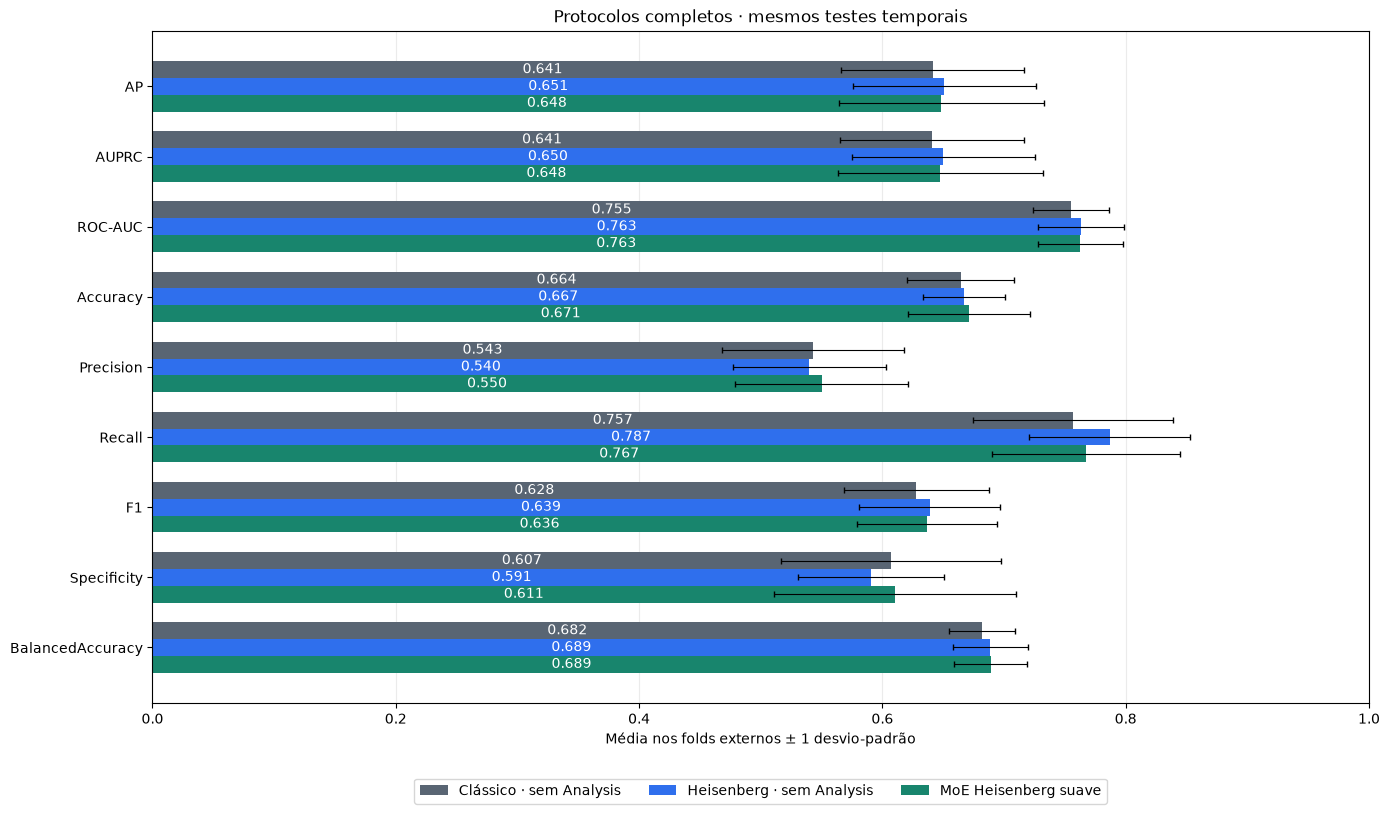

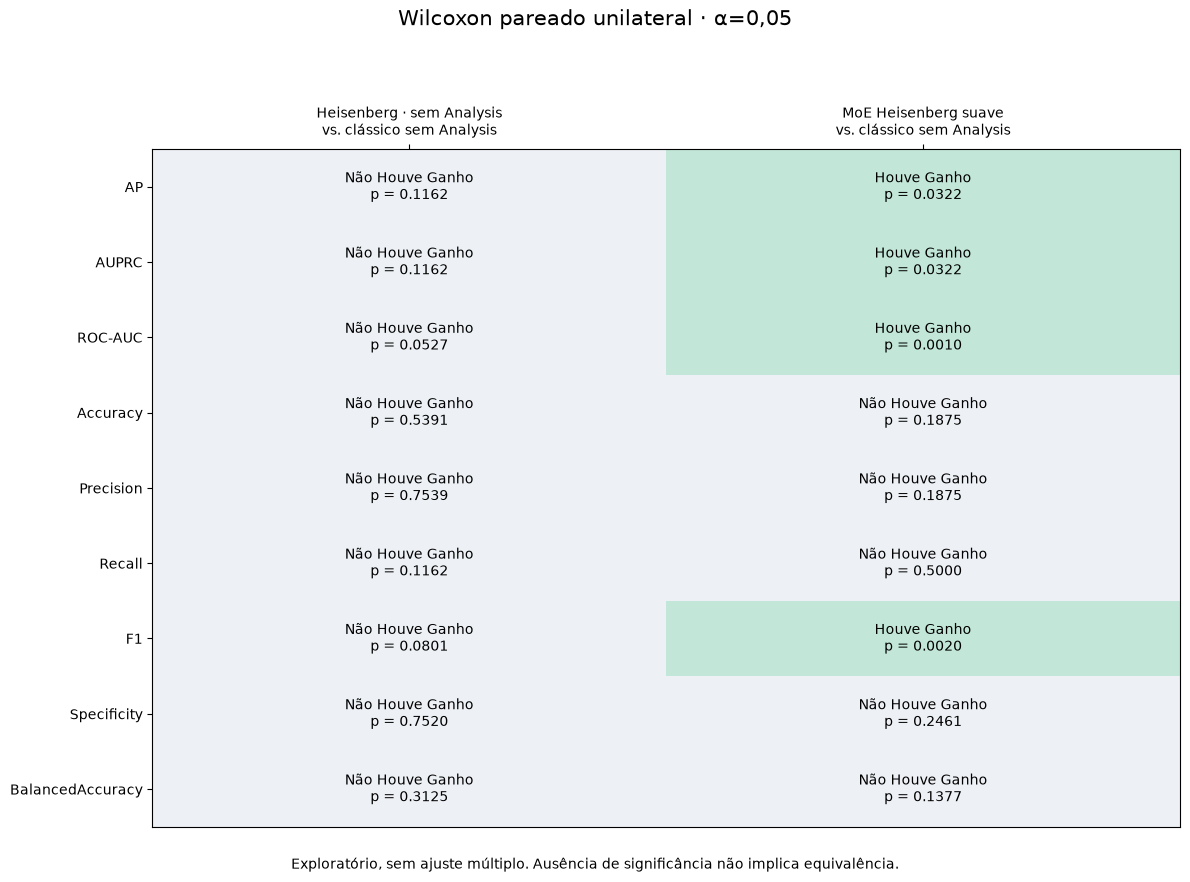

Artefatos sem Analysis: /home/rafael/projects/pqfmlib-api/notebooks_MoE/outputs/demanda_pressao_sem_analysis/20261026T123232_1b68553c


In [34]:
ANALYZE_NO_ANALYSIS = True
EXPORT_NO_ANALYSIS = True
# Opcional: caminho da pasta exportada pelo MoE. Tem prioridade sobre o objeto em memória.
MOE_REFERENCE_DIR = None

if ANALYZE_NO_ANALYSIS or EXPORT_NO_ANALYSIS:
    if 'classificacao_sem_analysis_results' not in globals():
        raise RuntimeError('Execute primeiro o experimento sem Analysis.')
    validate_no_analysis_result(classificacao_sem_analysis_results, data, protocol)
    referencia_moe = (load_moe_comparison_reference(MOE_REFERENCE_DIR)
                      if MOE_REFERENCE_DIR is not None
                      else globals().get('classificacao_moe_results'))
    if referencia_moe is None:
        print('Sem referência MoE: comparação restrita aos dois especialistas sem Analysis.')
    tabelas_sem_analysis = no_analysis_comparison_tables(
        classificacao_sem_analysis_results, referencia_moe)
    figuras_sem_analysis = no_analysis_figures(tabelas_sem_analysis)
    if ANALYZE_NO_ANALYSIS:
        for name in ('summary', 'paired_tests', 'inference_costs'):
            print(name)
            display(tabelas_sem_analysis[name])
        print('Tempos de treino e inferência por especialista e fold:')
        display(classificacao_sem_analysis_results['metrics'][[
            'fold', 'scenario', 'tuning_seconds', 'initial_fit_seconds',
            'refit_seconds', 'inference_seconds', 'seconds_per_sample']])
        for figure in figuras_sem_analysis.values():
            display(figure)
    if EXPORT_NO_ANALYSIS:
        classificacao_sem_analysis_output = export_no_analysis_results(
            classificacao_sem_analysis_results, data, protocol,
            tabelas_sem_analysis, figuras_sem_analysis)
        print('Artefatos sem Analysis:', classificacao_sem_analysis_output.resolve())
    import matplotlib.pyplot as plt
    for figure in figuras_sem_analysis.values():
        plt.close(figure)
